# models version 2

In [1]:
import numpy as np
import pandas as pd
import joblib
import os
import json
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
from mpl_toolkits.mplot3d import Axes3D
warnings.filterwarnings('ignore')

# Clustering & ML Metrics
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN
)
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score
)

# Dimensionality Reduction
from sklearn.decomposition import (
    PCA, KernelPCA, NMF, FactorAnalysis, TruncatedSVD, FastICA
)
from sklearn.manifold import (
    TSNE, Isomap, LocallyLinearEmbedding, SpectralEmbedding
)
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, normalize
)
from sklearn.base import BaseEstimator, TransformerMixin

# Anomaly Detection
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope

# Association Rules
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Dynamic Paths Resolution
PROJECT_ROOT = Path(os.getcwd()).resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'online+retail'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'

MODELS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Loading feature artifacts from: {PROCESSED_DIR}")

# Load Preprocessed Data
rfm = pd.read_csv(PROCESSED_DIR / 'rfm_features.csv')
x_scaled = np.load(PROCESSED_DIR / 'x_processed.npy')
with open(PROCESSED_DIR / 'model_features.txt', 'r') as f:
    model_features = [line.strip() for line in f if line.strip()]

print(f"Loaded RFM records: {rfm.shape}")
print(f"Scaled feature matrix: {x_scaled.shape}")
print(f"Feature count: {len(model_features)} features: {model_features}")

# Load Raw Transaction Data for Market Basket Analysis
raw_data_file = RAW_DIR / 'Online Retail.xlsx'
if raw_data_file.exists():
    print('Loading raw retail transactions for Market Basket Analysis...')
    raw_df = pd.read_excel(raw_data_file).dropna(subset=['CustomerID'])
    print(f'Loaded raw_df: {raw_df.shape[0]:,} rows')
else:
    raw_df = None


Project Root: C:\--------projects------\Customer_Segmentation--UCI-
Loading feature artifacts from: C:\--------projects------\Customer_Segmentation--UCI-\data\processed
Loaded RFM records: (4319, 24)
Scaled feature matrix: (4319, 14)
Feature count: 14 features: ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'ProductVariety', 'LifespanDays', 'PurchaseRate', 'AvgDaysBetweenPurchases', 'SpendPerProduct', 'QtyPerOrder', 'RevenuePerDay', 'UniqueProductPct', 'OrderValueConsistency', 'CLV_score']
Loading raw retail transactions for Market Basket Analysis...
Loaded raw_df: 406,829 rows


In [2]:
class PercentileClipper(BaseEstimator, TransformerMixin):
    """Clips features to [lower, upper] percentiles to mitigate outlier skew."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper
        self.lower_bounds_ = None
        self.upper_bounds_ = None
        
    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        self.lower_bounds_ = np.percentile(X_arr, self.lower * 100, axis=0)
        self.upper_bounds_ = np.percentile(X_arr, self.upper * 100, axis=0)
        return self

    def transform(self, X):
        X_arr = np.asarray(X)
        clipped = np.clip(X_arr, self.lower_bounds_, self.upper_bounds_)
        if isinstance(X, pd.DataFrame):
            return pd.DataFrame(clipped, columns=X.columns, index=X.index)
        return clipped

    def get_feature_names_out(self, input_features=None):
        return input_features

print("PercentileClipper loaded and verified.")


PercentileClipper loaded and verified.


# 01 | Customer Segmentation (Clustering & Evaluation)

This section implements the end-to-end customer segmentation engine:
1. **Optimal $K$ Search**: Evaluating Inertia (Elbow Method), Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score across $K \in [2, 8]$.
2. **Algorithm Comparison**: Benchmarking K-Means++, MiniBatchKMeans, Agglomerative Clustering (Ward), Gaussian Mixture Models (GMM), and DBSCAN.
3. **Model Fitting & Profiling**: Fitting final K-Means++ with optimal $K=4$ and profiling business customer personas (Champions, Loyal, At Risk, Lost).
4. **Surrogate Model Explainability**: Training a decision tree to extract feature importance explaining cluster memberships.
5. **Artifacts Export**: Serializing the clustering model (`kmeans_clusterer.joblib`) and cluster profiles (`cluster_profiles.json`).

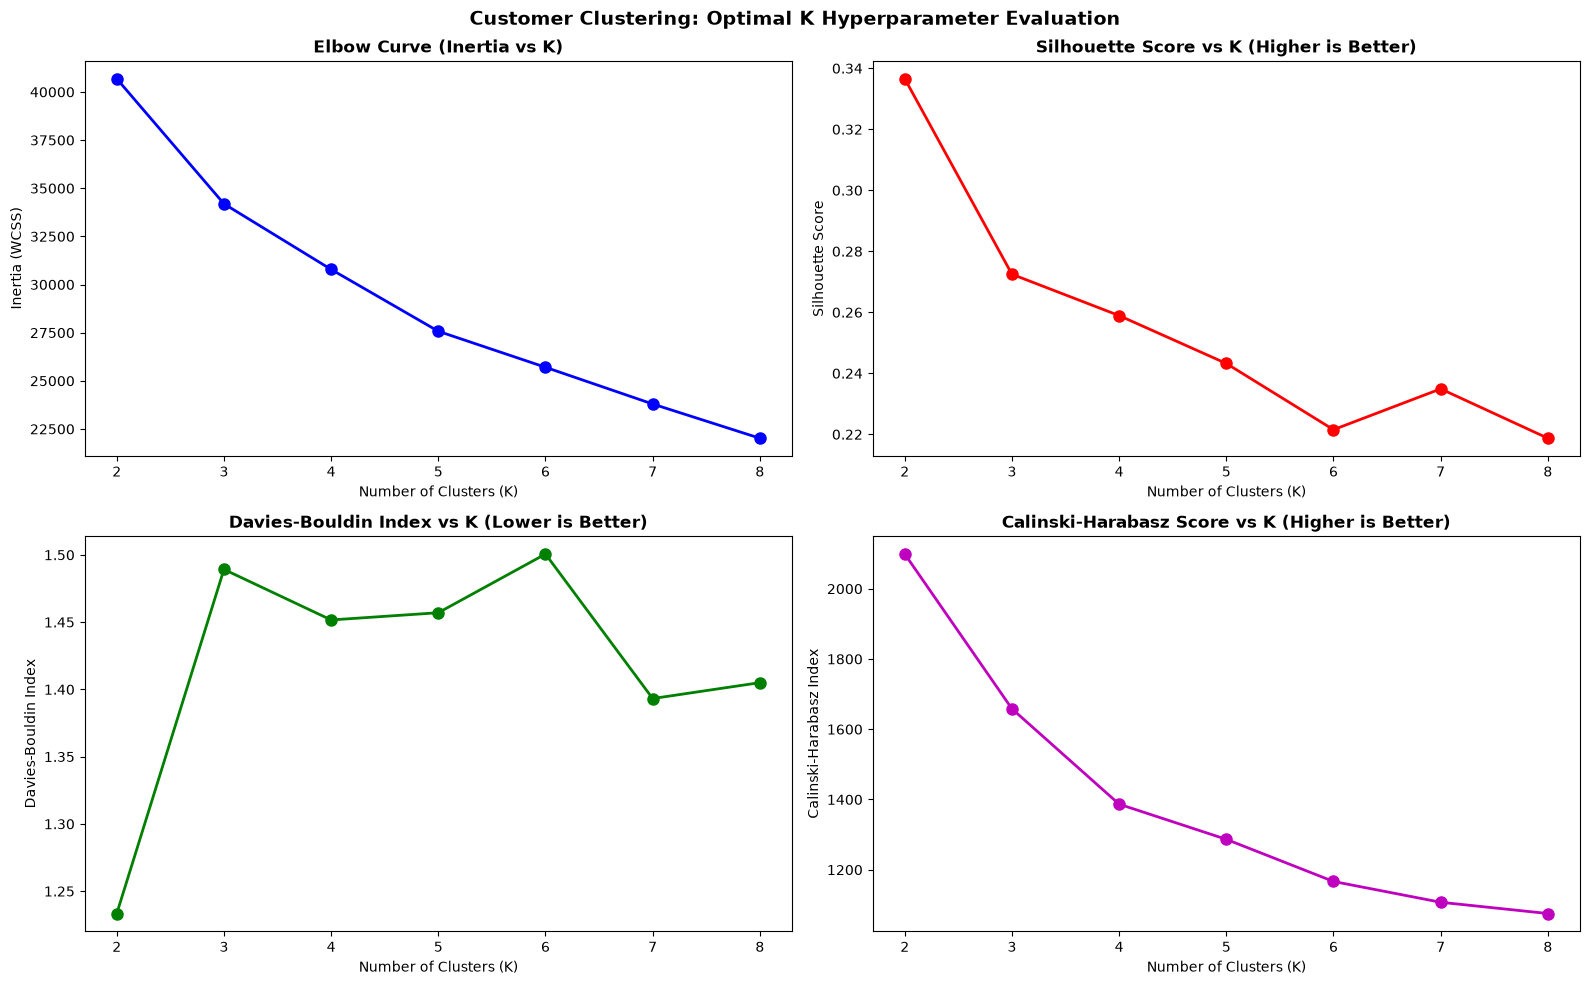

Selected Optimal K: 4 based on elbow deflection and balanced silhouette cohesion.


In [3]:
# 1.1 Hyperparameter Search for Optimal K (Elbow & Silhouette Analysis)
k_range = range(2, 9)
inertias = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(x_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(x_scaled, labels))
    davies_bouldin_scores.append(davies_bouldin_score(x_scaled, labels))
    calinski_scores.append(calinski_harabasz_score(x_scaled, labels))

# Plot 4-panel evaluation
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].plot(k_range, inertias, 'bo-', lw=2, markersize=8)
axes[0, 0].set_title('Elbow Curve (Inertia vs K)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Number of Clusters (K)')
axes[0, 0].set_ylabel('Inertia (WCSS)')

axes[0, 1].plot(k_range, silhouette_scores, 'ro-', lw=2, markersize=8)
axes[0, 1].set_title('Silhouette Score vs K (Higher is Better)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Number of Clusters (K)')
axes[0, 1].set_ylabel('Silhouette Score')

axes[1, 0].plot(k_range, davies_bouldin_scores, 'go-', lw=2, markersize=8)
axes[1, 0].set_title('Davies-Bouldin Index vs K (Lower is Better)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Number of Clusters (K)')
axes[1, 0].set_ylabel('Davies-Bouldin Index')

axes[1, 1].plot(k_range, calinski_scores, 'mo-', lw=2, markersize=8)
axes[1, 1].set_title('Calinski-Harabasz Score vs K (Higher is Better)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Number of Clusters (K)')
axes[1, 1].set_ylabel('Calinski-Harabasz Index')

plt.suptitle('Customer Clustering: Optimal K Hyperparameter Evaluation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

opt_k = 4
print(f"Selected Optimal K: {opt_k} based on elbow deflection and balanced silhouette cohesion.")


In [4]:
# 1.2 Multi-Algorithm Clustering Comparison
algorithms = {
    'K-Means++': KMeans(n_clusters=opt_k, init='k-means++', n_init=15, random_state=42),
    'MiniBatch K-Means': MiniBatchKMeans(n_clusters=opt_k, batch_size=256, random_state=42),
    'Hierarchical (Ward)': AgglomerativeClustering(n_clusters=opt_k, linkage='ward'),
    'Gaussian Mixture (GMM)': GaussianMixture(n_components=opt_k, random_state=42, n_init=5)
}

comparison_results = []
for name, algo in algorithms.items():
    if name == 'Gaussian Mixture (GMM)':
        labels = algo.fit_predict(x_scaled)
    else:
        labels = algo.fit_predict(x_scaled)
    
    sil = silhouette_score(x_scaled, labels)
    db = davies_bouldin_score(x_scaled, labels)
    ch = calinski_harabasz_score(x_scaled, labels)
    
    comparison_results.append({
        'Algorithm': name,
        'Silhouette Score': round(sil, 4),
        'Davies-Bouldin': round(db, 4),
        'Calinski-Harabasz': round(ch, 2)
    })

comp_df = pd.DataFrame(comparison_results)
print("Clustering Algorithm Benchmark Results:")
print(comp_df.to_string(index=False))


Clustering Algorithm Benchmark Results:
             Algorithm  Silhouette Score  Davies-Bouldin  Calinski-Harabasz
             K-Means++            0.2589          1.4516            1386.68
     MiniBatch K-Means            0.2176          1.7322            1288.69
   Hierarchical (Ward)            0.2132          1.5713            1219.61
Gaussian Mixture (GMM)            0.1941          2.5449             936.09


In [5]:
# 1.3 Final K-Means Model Fitting, Profiling & Business Personas
kmeans_final = KMeans(n_clusters=opt_k, init='k-means++', n_init=20, random_state=42)
cluster_labels = kmeans_final.fit_predict(x_scaled)
rfm['Cluster'] = cluster_labels

# Rank clusters by average monetary spend to assign intuitive persona names
cluster_spend_rank = rfm.groupby('Cluster')['Monetary'].mean().sort_values(ascending=False).index.tolist()

persona_mapping = {
    cluster_spend_rank[0]: 'Champions / VIP',
    cluster_spend_rank[1]: 'Loyal & High Spenders',
    cluster_spend_rank[2]: 'Potential & Active Shoppers',
    cluster_spend_rank[3]: 'At-Risk / Inactive'
}

strategy_mapping = {
    cluster_spend_rank[0]: 'Reward loyalty, offer exclusive VIP perks and dedicated account support.',
    cluster_spend_rank[1]: 'Upsell high-margin items, personalized product recommendations, and loyalty incentives.',
    cluster_spend_rank[2]: 'Encourage frequency with limited-time promotions and targeted email campaigns.',
    cluster_spend_rank[3]: 'Run aggressive re-engagement/win-back discounts or survey to understand churn.'
}

rfm['Segment_Persona'] = rfm['Cluster'].map(persona_mapping)
rfm['Recommended_Strategy'] = rfm['Cluster'].map(strategy_mapping)

# Profile Summary
profile_metrics = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'ProductVariety', 'LifespanDays']
cluster_profile = rfm.groupby('Segment_Persona')[profile_metrics].mean().round(2)
cluster_profile['Customer_Count'] = rfm.groupby('Segment_Persona').size()
cluster_profile['Customer_Pct'] = (cluster_profile['Customer_Count'] / len(rfm) * 100).round(1).astype(str) + '%'
cluster_profile['Total_Revenue'] = rfm.groupby('Segment_Persona')['Monetary'].sum().round(0)
cluster_profile['Revenue_Pct'] = (cluster_profile['Total_Revenue'] / rfm['Monetary'].sum() * 100).round(1).astype(str) + '%'

print("Cluster Profiles Summary:")
print(cluster_profile[['Customer_Count', 'Customer_Pct', 'Total_Revenue', 'Revenue_Pct'] + profile_metrics].to_string())


Cluster Profiles Summary:
                             Customer_Count Customer_Pct  Total_Revenue Revenue_Pct  Recency  Frequency  Monetary  AvgOrderValue  ProductVariety  LifespanDays
Segment_Persona                                                                                                                                               
At-Risk / Inactive                      430        10.0%       109860.0        1.4%   137.13       1.34    255.49           6.59           44.74         15.10
Champions / VIP                         826        19.1%      5545420.0       68.2%    19.49      11.96   6713.58          50.49          123.25        272.78
Loyal & High Spenders                  1864        43.2%      1998150.0       24.6%    71.42       3.58   1071.97          18.36           66.91        177.31
Potential & Active Shoppers            1199        27.8%       482797.0        5.9%   159.62       1.04    402.67          37.16           17.25          0.14


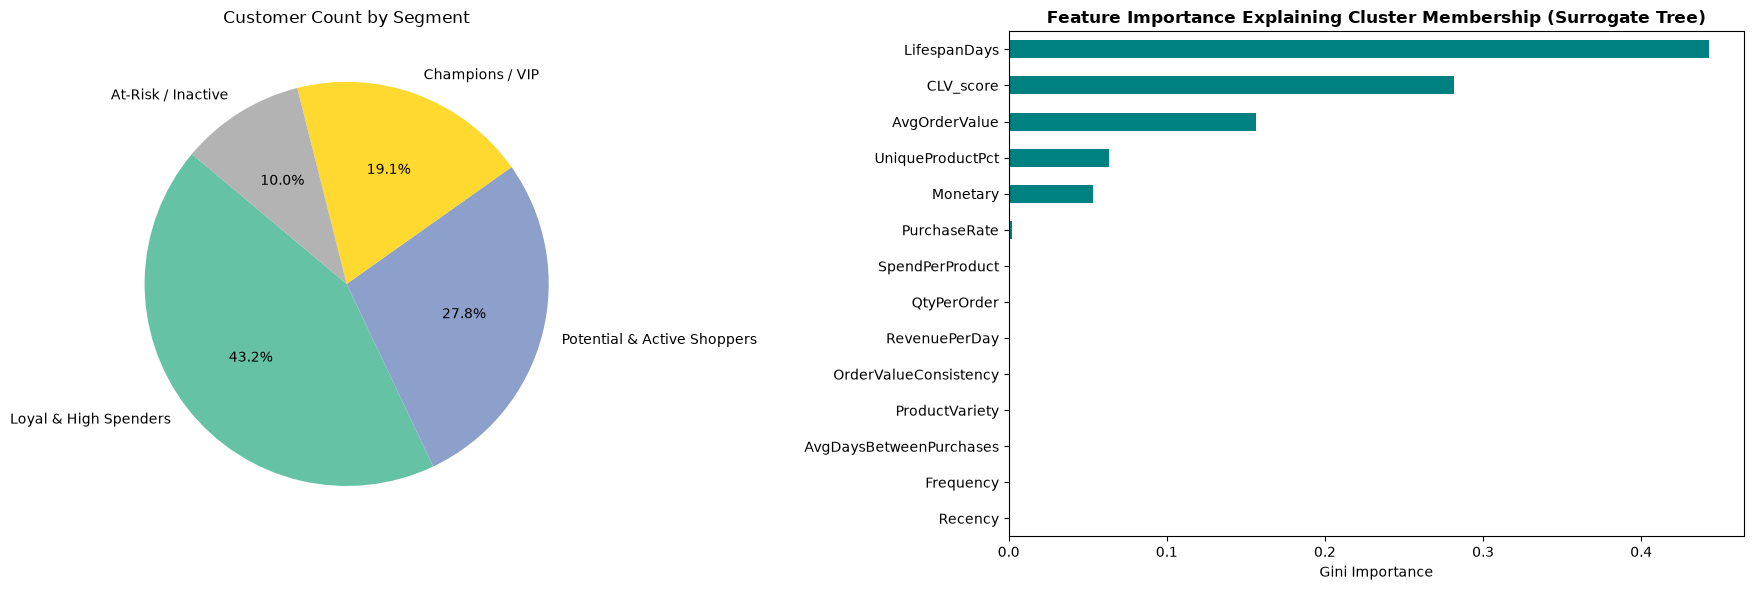

In [6]:
# 1.4 Visualizing Segment Distribution & Feature Importance (Surrogate Decision Tree)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Customer vs Revenue Pie Charts
rfm['Segment_Persona'].value_counts().plot.pie(
    ax=axes[0], autopct='%1.1f%%', startangle=140, cmap='Set2',
    title='Customer Count by Segment'
)
axes[0].set_ylabel('')

# Surrogate Decision Tree for Feature Importance Explanation
surrogate_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
surrogate_tree.fit(x_scaled, cluster_labels)
importances = pd.Series(surrogate_tree.feature_importances_, index=model_features).sort_values(ascending=True)

importances.plot.barh(ax=axes[1], color='teal')
axes[1].set_title('Feature Importance Explaining Cluster Membership (Surrogate Tree)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gini Importance')

plt.tight_layout()
plt.show()


In [7]:
# 1.5 Save Clustering Model & Segment Metadata Artifacts
kmeans_model_path = MODELS_DIR / 'kmeans_clusterer.joblib'
joblib.dump(kmeans_final, kmeans_model_path)
print(f"Saved trained KMeans model to: {kmeans_model_path}")

# Save cluster profiles as JSON
profiles_export = {}
for cid in range(opt_k):
    c_df = rfm[rfm['Cluster'] == cid]
    p_name = persona_mapping[cid]
    profiles_export[p_name] = {
        'cluster_id': int(cid),
        'customer_count': int(len(c_df)),
        'customer_percentage': float(round(len(c_df) / len(rfm) * 100, 2)),
        'total_revenue': float(round(c_df['Monetary'].sum(), 2)),
        'revenue_percentage': float(round(c_df['Monetary'].sum() / rfm['Monetary'].sum() * 100, 2)),
        'mean_metrics': {
            'Recency': float(round(c_df['Recency'].mean(), 2)),
            'Frequency': float(round(c_df['Frequency'].mean(), 2)),
            'Monetary': float(round(c_df['Monetary'].mean(), 2)),
            'AvgOrderValue': float(round(c_df['AvgOrderValue'].mean(), 2)),
            'LifespanDays': float(round(c_df['LifespanDays'].mean(), 2))
        },
        'recommended_strategy': strategy_mapping[cid]
    }

profiles_json_path = MODELS_DIR / 'cluster_profiles.json'
with open(profiles_json_path, 'w', encoding='utf-8') as f:
    json.dump(profiles_export, f, indent=2)
print(f"Saved cluster profiles metadata to: {profiles_json_path}")


Saved trained KMeans model to: C:\--------projects------\Customer_Segmentation--UCI-\models\kmeans_clusterer.joblib
Saved cluster profiles metadata to: C:\--------projects------\Customer_Segmentation--UCI-\models\cluster_profiles.json


##  2 dimensionality reduction

### 2.1 pca (principal component analysis)

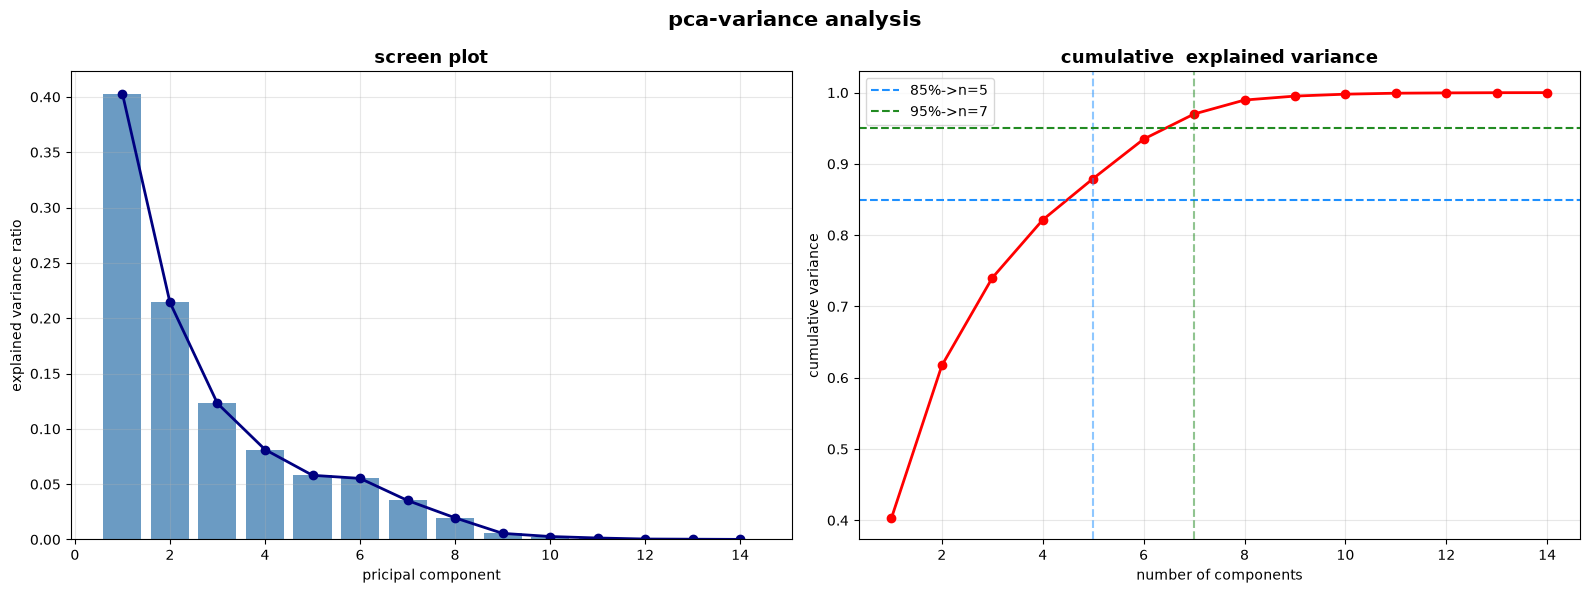

 pca :(4319, 7) | variance retained: 97.00%
 n_components 85%: 5 | n_components 95% : 7


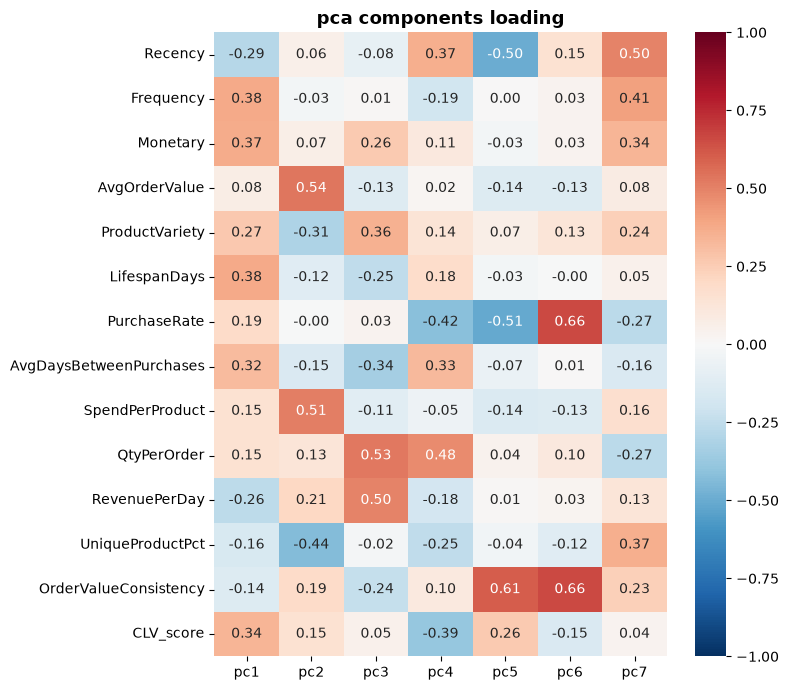

PCA transformer saved to: C:\--------projects------\Customer_Segmentation--UCI-\models\pca_transformer.joblib


In [8]:
pca_full=PCA(random_state=42)
pca_full.fit(x_scaled)
cumulative=np.cumsum(pca_full.explained_variance_ratio_)

n_comp_85=int(np.argmax(cumulative >=0.85))+1
n_comp_95=int(np.argmax(cumulative>=0.95))+1


pca_final=PCA(n_components=n_comp_95,random_state=42)
x_pca=pca_final.fit_transform(x_scaled)

fig,axes=plt.subplots(1,2,figsize=(16,6))

axes[0].bar(range(1,len(pca_full.explained_variance_ratio_)+1),
            pca_full.explained_variance_ratio_,color='steelblue',alpha=0.8)
axes[0].plot(range(1,len(pca_full.explained_variance_ratio_)+1),
                pca_full.explained_variance_ratio_,'o-',color='navy',lw=2)
axes[0].set_title('screen plot',fontsize=13,fontweight='bold')
axes[0].set_xlabel('pricipal component')
axes[0].set_ylabel('explained variance ratio')
axes[0].grid(True,alpha=0.3)


#cumulative
axes[1].plot(range(1,len(cumulative)+1),cumulative,'ro-',lw=2)
for pct,col,lbl in [(0.85,'dodgerblue','85%'),(0.95,'forestgreen','95%')]:
    idx=np.argmax(cumulative>=pct)
    axes[1].axhline(y=pct,color=col,linestyle='--',lw=1.5,label=f'{lbl}->n={idx+1}')
    axes[1].axvline(x=idx+1,color=col,linestyle='--',alpha=0.5)
axes[1].set_title('cumulative  explained variance',fontsize=13,fontweight='bold')
axes[1].set_xlabel('number of components')
axes[1].set_ylabel('cumulative variance')
axes[1].legend()
axes[1].grid(True,alpha=0.3)

plt.suptitle('pca-variance analysis',fontsize=15,fontweight='bold')
plt.tight_layout()
plt.show()

print(f' pca :{x_pca.shape} | variance retained: {pca_final.explained_variance_ratio_.sum():.2%}')
print(f' n_components 85%: {n_comp_85} | n_components 95% : {n_comp_95}')

#loading heatmap
comp_df=pd.DataFrame(pca_final.components_.T,columns=[f'pc{i+1}' for i in range(n_comp_95)],index=model_features)
fig,ax=plt.subplots(figsize=(max(8,n_comp_85 * 1.5),7))
sns.heatmap(comp_df,annot=True,fmt='.2f',cmap='RdBu_r',center=0,ax=ax,vmin=-1,vmax=1)
ax.set_title('pca components loading',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.show()


# Save trained PCA transformer
joblib.dump(pca_final, MODELS_DIR / 'pca_transformer.joblib')
print(f'PCA transformer saved to: {MODELS_DIR / "pca_transformer.joblib"}')


### 2.2 -- kernal pca (non_linear)

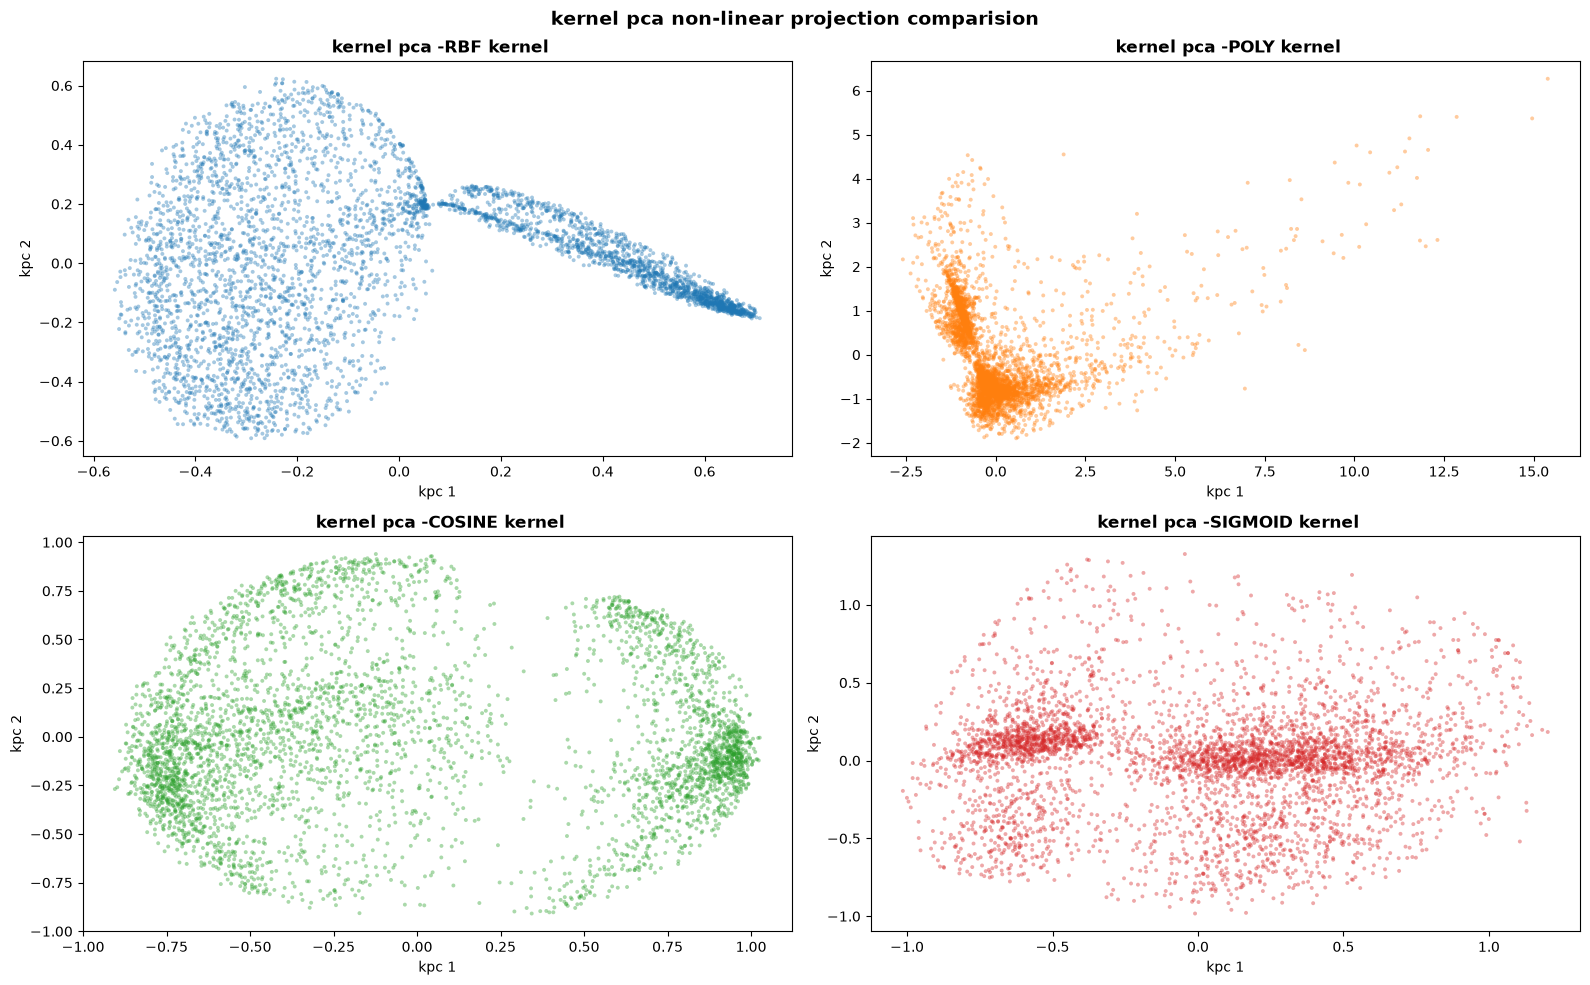

 kernel pca done | best kernel for viz: RBF |shape: (4319, 2)
 kernel pca maps data to higher-dim space -> reveals non-linear structures 


In [9]:
kernels=['rbf','poly','cosine','sigmoid']
kpca_results={}

fig,axes=plt.subplots(2,2,figsize=(16,10))
axes=axes.flatten()

for idx,kernel in enumerate(kernels):
    kpca=KernelPCA(n_components=2,kernel=kernel,random_state=42,n_jobs=-1,gamma=0.1 if kernel in ['rbf','sigmoid'] else None)
    x_kpca=kpca.fit_transform(x_scaled)
    kpca_results[kernel]=x_kpca

    axes[idx].scatter(x_kpca[:,0],x_kpca[:,1],alpha=0.4,s=8,c=sns.color_palette('tab10')[idx],edgecolor='none')
    axes[idx].set_title(f' kernel pca -{kernel.upper()} kernel',fontsize=12,fontweight='bold')
    axes[idx].set_xlabel('kpc 1')
    axes[idx].set_ylabel('kpc 2')

plt.suptitle('kernel pca non-linear projection comparision',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

x_kpca_best=kpca_results['rbf']
print(f' kernel pca done | best kernel for viz: RBF |shape: {x_kpca_best.shape}')
print(f' kernel pca maps data to higher-dim space -> reveals non-linear structures ')

### 2.3 t-sne (t-distributed stochastic neighbor embedding)


 t-sne input sampled to 3000 points


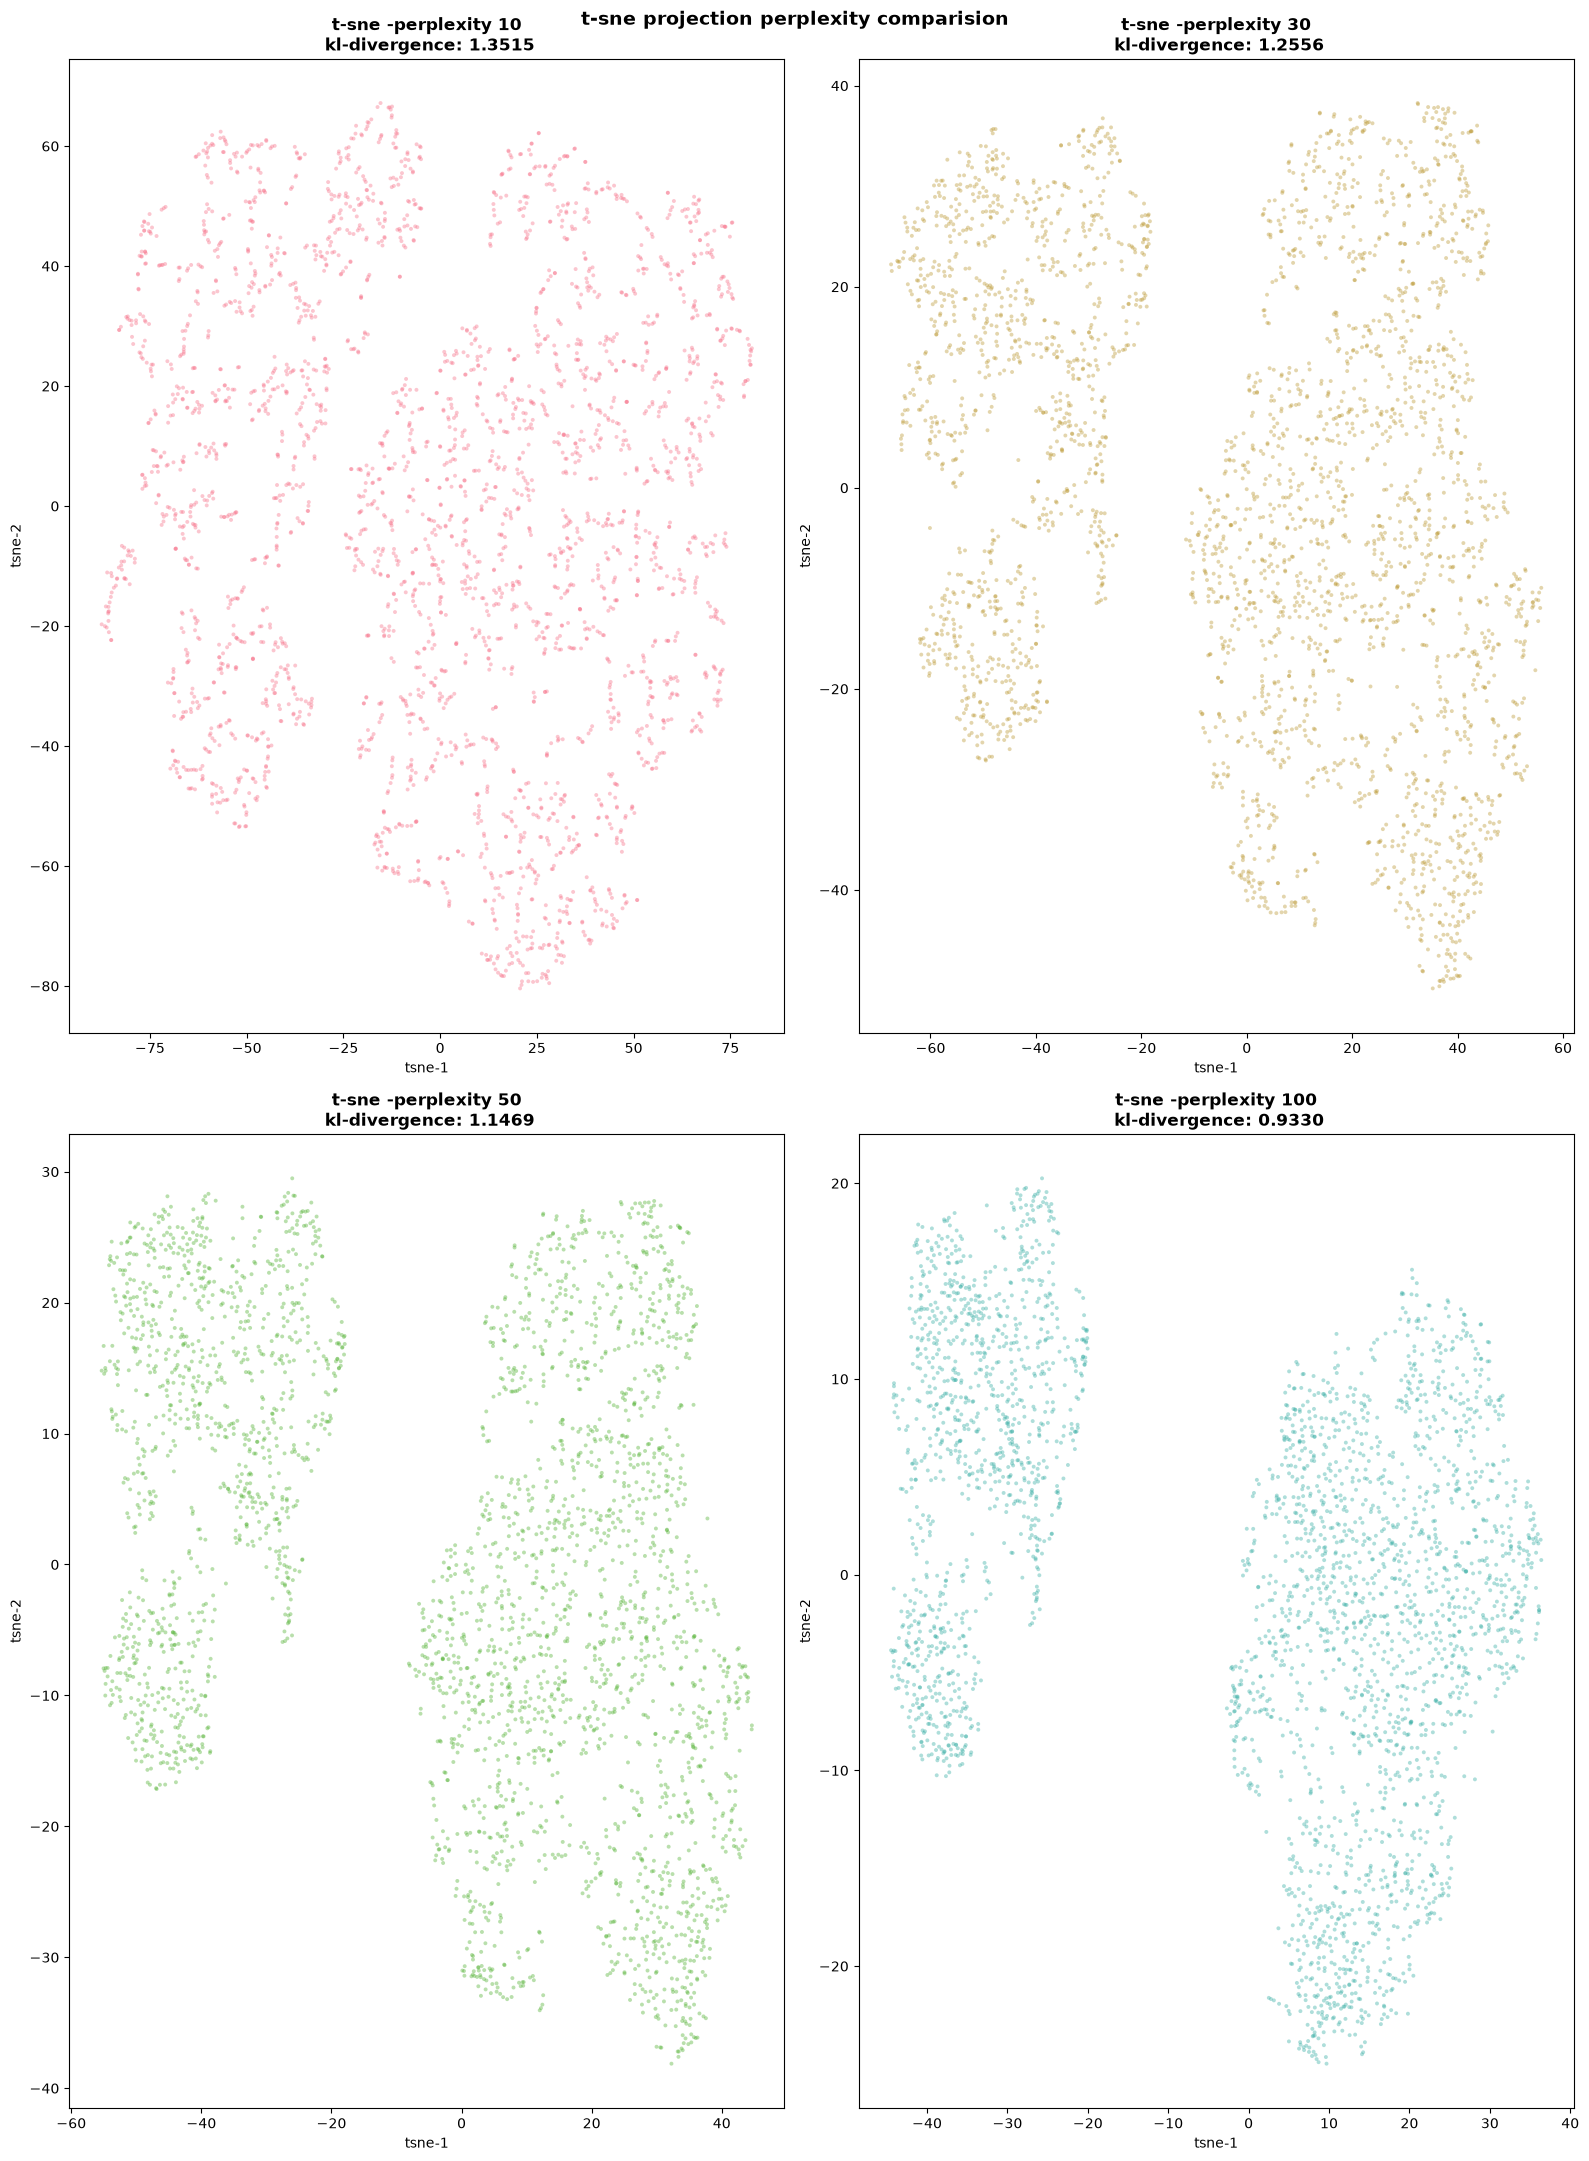

 t-sne done | best perplexity :30
 lower kl-divergence better local structure preservation
 t-sne  is not deterministic  acroos runs -distances between clusters not meaningful


In [10]:
perplexties=[10,30,50,100]
tsne_results={}
max_tsne=3000
if x_scaled.shape[0]>max_tsne:
    np.random.seed(42)
    tsne_idx=np.random.choice(x_scaled.shape[0],max_tsne,replace=False)
    x_tsne_input=x_scaled[tsne_idx]
    print(f' t-sne input sampled to {max_tsne} points')
else:
    tsne_idx=np.arange(x_scaled.shape[0])
    x_tsne_input=x_scaled

fig,axes=plt.subplots(2,2,figsize=(16,22))
axes=axes.flatten()

for idx,perp in enumerate(perplexties):
    tsne=TSNE(n_components=2,perplexity=perp,learning_rate='auto',init='pca',random_state=42,max_iter=1000)
    x_tsne=tsne.fit_transform(x_tsne_input)
    tsne_results[perp]=x_tsne

    axes[idx].scatter(x_tsne[:,0],x_tsne[:,1],alpha=0.4,s=8,c=sns.color_palette('husl')[idx],edgecolor='none')
    axes[idx].set_title(f't-sne -perplexity {perp}\n kl-divergence: {tsne.kl_divergence_:.4f}',
    fontsize=12,fontweight='bold')
    axes[idx].set_xlabel('tsne-1')
    axes[idx].set_ylabel('tsne-2')

plt.suptitle('t-sne projection perplexity comparision',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

x_tsne_best=tsne_results[30]

print(f' t-sne done | best perplexity :30')
print(f' lower kl-divergence better local structure preservation')
print(f' t-sne  is not deterministic  acroos runs -distances between clusters not meaningful')

### 2.4 --umap (uniform manifold approximation and projection)


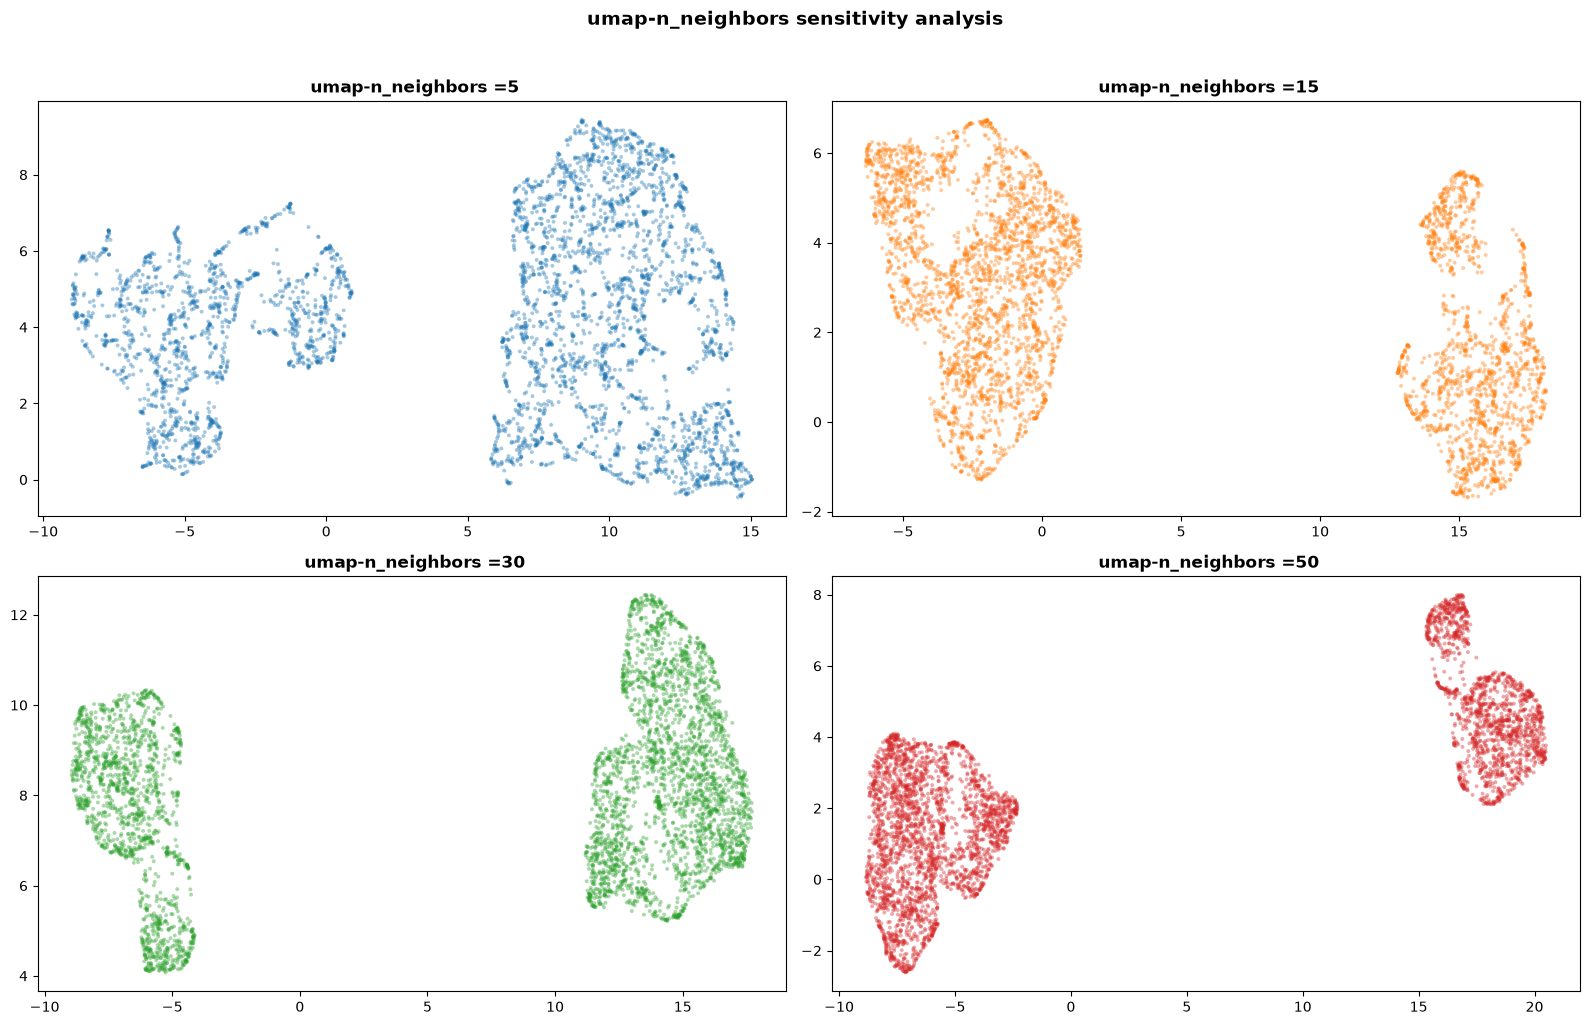

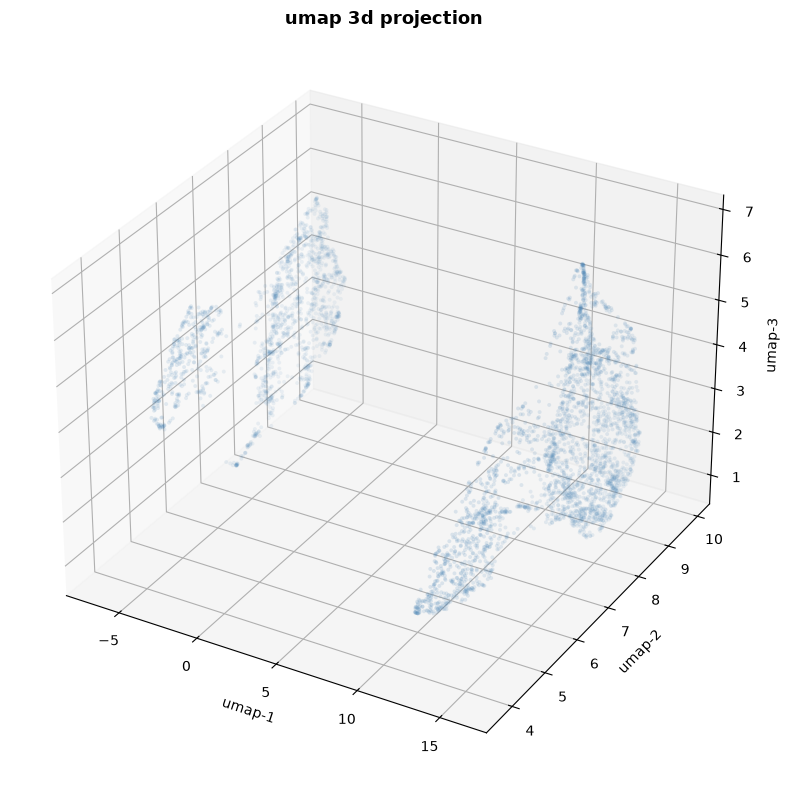

 umap 2d : (4319, 2) | umap 3d: (4319, 3)
 umap preserves local and some global structure |best for downstream clustering


In [11]:
import umap
umap_2d=umap.UMAP(n_neighbors=15,min_dist=0.1,n_components=2,random_state=42,metric='euclidean')
x_umap_2d=umap_2d.fit_transform(x_scaled)

umap_3d=umap.UMAP(n_neighbors=15,min_dist=0.1,n_components=3,random_state=42,metric='euclidean')
x_umap_3d=umap_3d.fit_transform(x_scaled)

neighbors_list=[5,15,30,50]

fig,axes=plt.subplots(2,2,figsize=(16,10))
axes=axes.flatten()

for idx,nn in enumerate(neighbors_list):
    u=umap.UMAP (n_neighbors=nn,min_dist=0.1,n_components=2,metric='euclidean',random_state=42)
    xu=u.fit_transform(x_scaled)
    axes[idx].scatter(xu[:,0],xu[:,1],alpha=0.4,s=8,c=sns.color_palette('tab10')[idx],edgecolor='none')
    axes[idx].set_title(f' umap-n_neighbors ={nn}',fontsize=12,fontweight='bold')

plt.suptitle('umap-n_neighbors sensitivity analysis',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

# 3d plot
fig=plt.figure(figsize=(10,8))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(x_umap_3d[:,0],x_umap_3d[:,1],x_umap_3d[:,2],alpha=0.4,s=8,c='steelblue',edgecolor='none')
ax.set_title('umap 3d projection',fontsize=13,fontweight='bold')
ax.set_xlabel('umap-1')
ax.set_ylabel('umap-2')
ax.set_zlabel('umap-3')
plt.tight_layout()
plt.show()


print(f' umap 2d : {x_umap_2d.shape} | umap 3d: {x_umap_3d.shape}')
print(f' umap preserves local and some global structure |best for downstream clustering')




### 2.5 -- NMF (non-negative matrix factorization)


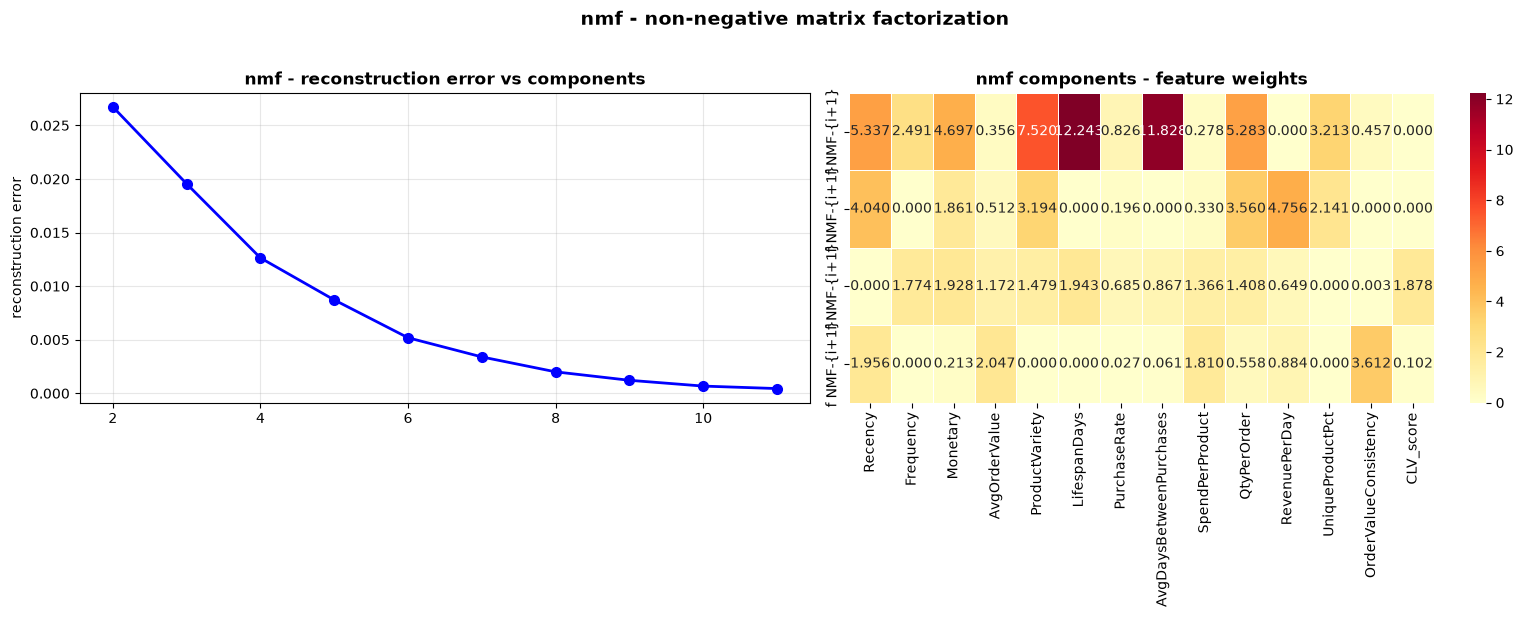

In [12]:
# -- NMF -- requires non -negative input
# shift x_scaled to non-negative range

from sklearn.preprocessing import MinMaxScaler

mms=MinMaxScaler()
x_nonneg=mms.fit_transform(x_scaled)

nmf_errors=[]
n_comps_range=range(2,min(12,x_scaled.shape[1]+1))

for n in n_comps_range:
    nmf_tmp=NMF(n_components=n,random_state=42,max_iter=500)
    w=nmf_tmp.fit_transform(x_nonneg)
    h=nmf_tmp.components_
    recon_err=np.mean((x_nonneg - w @ h)**2)
    nmf_errors.append(recon_err)

fig,axes=plt.subplots(1,2,figsize=(16,6))


# reconstruction error
axes[0].plot(n_comps_range,nmf_errors,'bo-',lw=2,markersize=7)
axes[0].set_title('number of components')
axes[0].set_ylabel('reconstruction error')
axes[0].set_title('nmf - reconstruction error vs components',fontsize=12,fontweight='bold')
axes[0].grid(True,alpha=0.3)

nmf_final=NMF(n_components=4,random_state=42,max_iter=500,init='nndsvda')
x_nmf=nmf_final.fit_transform(x_nonneg)

h_nmf=nmf_final.components_

#components heatmap
nmf_comp_df=pd.DataFrame(h_nmf,index=['f NMF-{i+1}' for i in range(4)],columns=model_features)
sns.heatmap(nmf_comp_df,annot=True,fmt='.3f',cmap='YlOrRd',ax=axes[1],linewidths=0.5)
axes[1].set_title('nmf components - feature weights', fontsize=12,fontweight='bold')

plt.suptitle('nmf - non-negative matrix factorization',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()


### 2.6 -- factor analysis (probabilistic linear model)



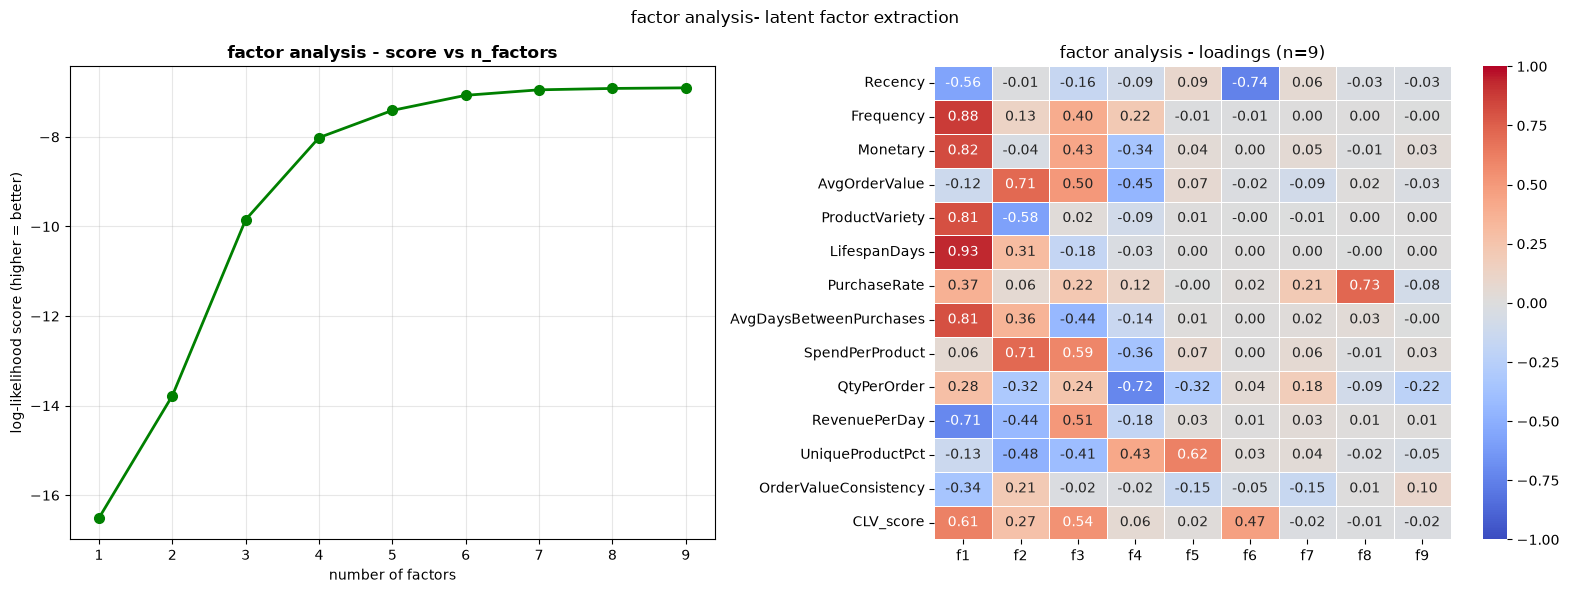

 factor analysis : (4319, 9) | best n_factors: 9
 noise variance per feature: (top 5):
 LifespanDays: 0.0004
 ProductVariety: 0.0005
 Frequency: 0.0008
 AvgDaysBetweenPurchases: 0.0044
 AvgOrderValue: 0.0046
 factor analysis : unlike pca factors have probabilistic interpretation


In [13]:
from sklearn.decomposition import FactorAnalysis

fa_scores=[]
n_factors_range=range(1,min(10,x_scaled.shape[1]))

for n in n_factors_range:
    fa_tmp=FactorAnalysis(n_components=n,random_state=42)
    fa_tmp.fit(x_scaled)
    fa_scores.append(fa_tmp.score(x_scaled))

fig,axes=plt.subplots(1,2,figsize=(16,6))

axes[0].plot(n_factors_range,fa_scores,'go-',lw=2,markersize=7)
axes[0].set_xlabel('number of factors')
axes[0].set_ylabel('log-likelihood score (higher = better)')
axes[0].set_title('factor analysis - score vs n_factors',fontsize=12,fontweight='bold')
axes[0].grid(True,alpha=0.3)

# best fa
best_fa_n=list(n_factors_range)[np.argmax(fa_scores)]
fa_final=FactorAnalysis(n_components=best_fa_n,random_state=42)
x_fa=fa_final.fit_transform(x_scaled)

fa_loadings_df=pd.DataFrame(fa_final.components_.T,index=model_features,columns=[f'f{i+1}' for i in range(best_fa_n)])

sns.heatmap(fa_loadings_df,annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=axes[1],linewidths=0.5,vmin=-1,vmax=1)
axes[1].set_title(f'factor analysis - loadings (n={best_fa_n})')
plt.suptitle('factor analysis- latent factor extraction')
plt.tight_layout()
plt.show()

print(f' factor analysis : {x_fa.shape} | best n_factors: {best_fa_n}')
print(f' noise variance per feature: (top 5):')

for feat,noise in sorted(zip(model_features,fa_final.noise_variance_),key=lambda x:x[1])[:5]:
    print(f' {feat}: {noise:.4f}')
print (f' factor analysis : unlike pca factors have probabilistic interpretation')



### 2.7 -- isomap (geodesic distance manifold)

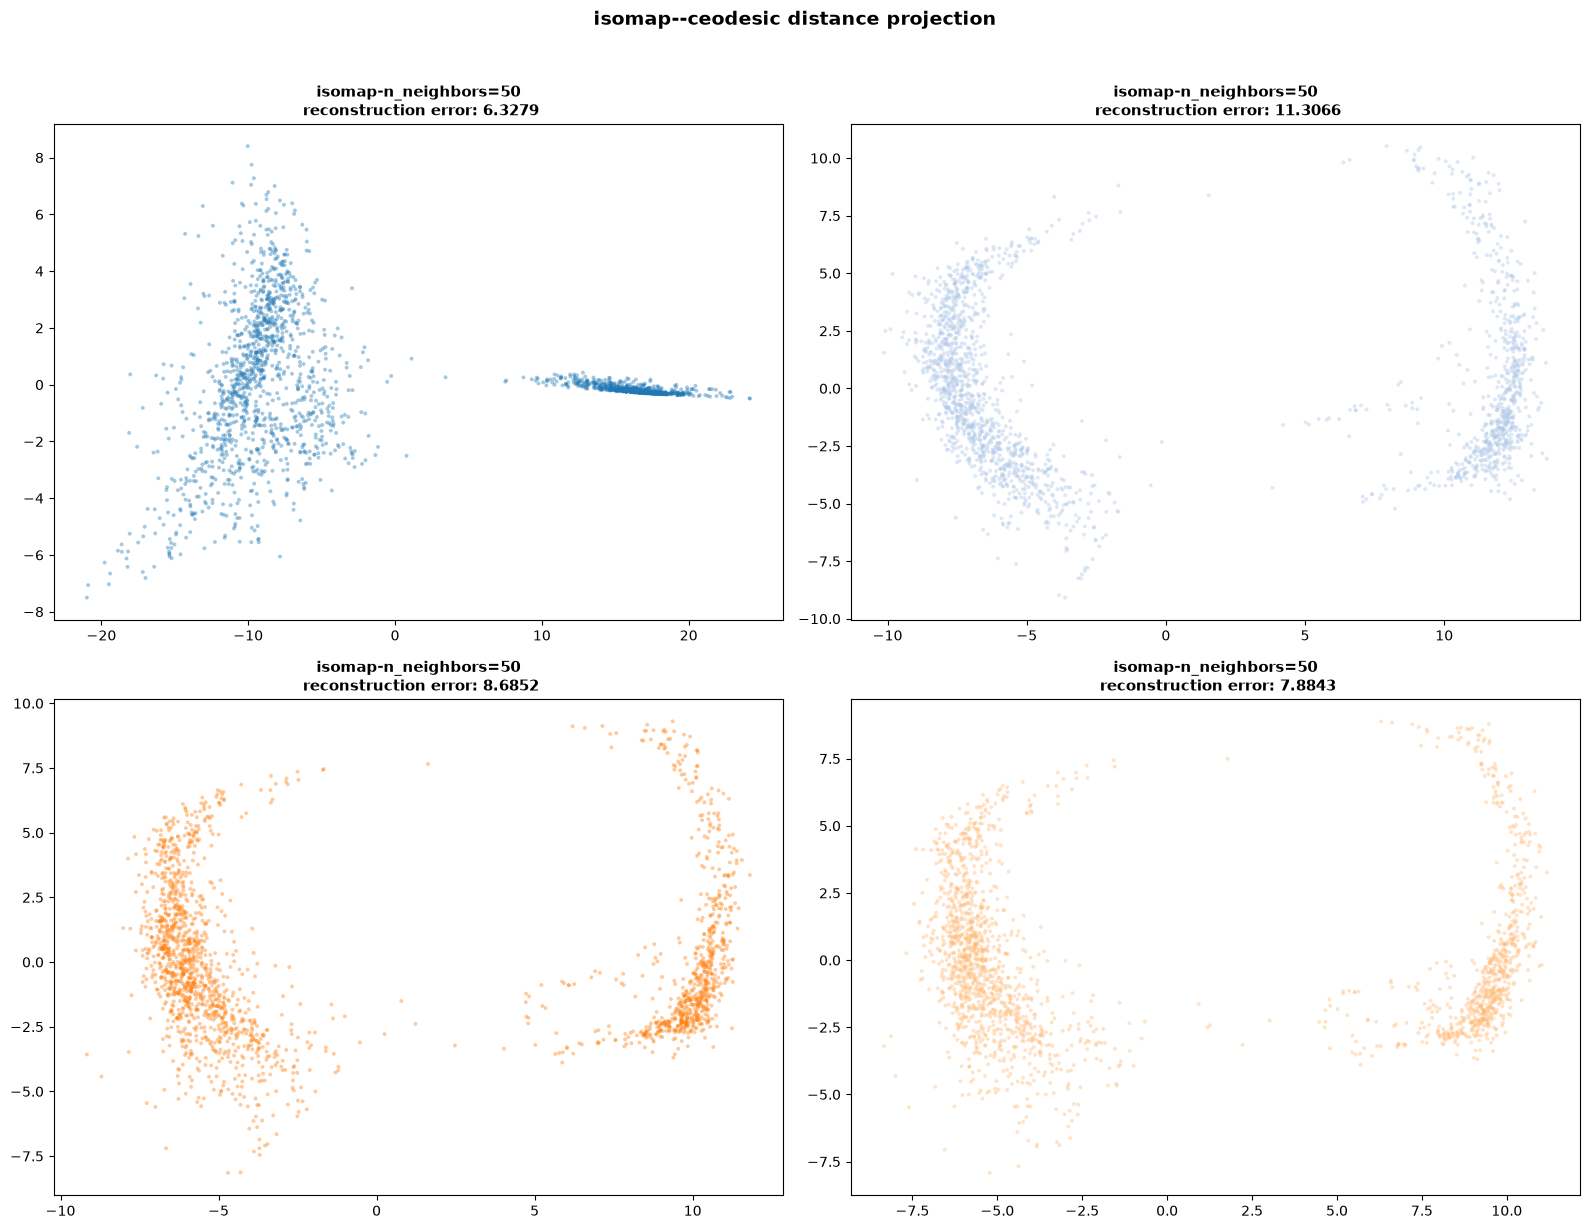

 isomap : (2000, 2)


In [14]:
from sklearn.manifold import Isomap

max_iso=2000
if x_scaled.shape[0]>max_iso:
    np.random.seed(42)
    iso_idx=np.random.choice(x_scaled.shape[0],max_iso,replace=False)
    x_iso_input=x_scaled[iso_idx]

else:
    iso_idx=np.arange(x_scaled.shape[0])
    x_iso_input=x_scaled

iso_neighbors=[5,10,20,30]
fig,axes=plt.subplots(2,2,figsize=(16,12))
axes=axes.flatten()

isomap_results={}

for idx,n_neighbors in enumerate(iso_neighbors):
    iso=Isomap(n_neighbors=n_neighbors,n_components=2,n_jobs=-1)
    x_iso=iso.fit_transform(x_iso_input)
    isomap_results[nn]=x_iso
    axes[idx].scatter(x_iso[:,0],x_iso[:,1],alpha=0.4,s=8,c=sns.color_palette('tab20')[idx],edgecolor='none')
    axes[idx].set_title(f'isomap-n_neighbors={nn}\n reconstruction error: {iso.reconstruction_error():.4f}',
                        fontsize=11,fontweight='bold')

plt.suptitle('isomap--ceodesic distance projection',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

best_iso=Isomap(n_neighbors=10,n_components=2,n_jobs=-1)
x_isomap=best_iso.fit_transform(x_iso_input)

print(f' isomap : {x_isomap.shape}')


### 2.8 lle (locally linear embeddding)

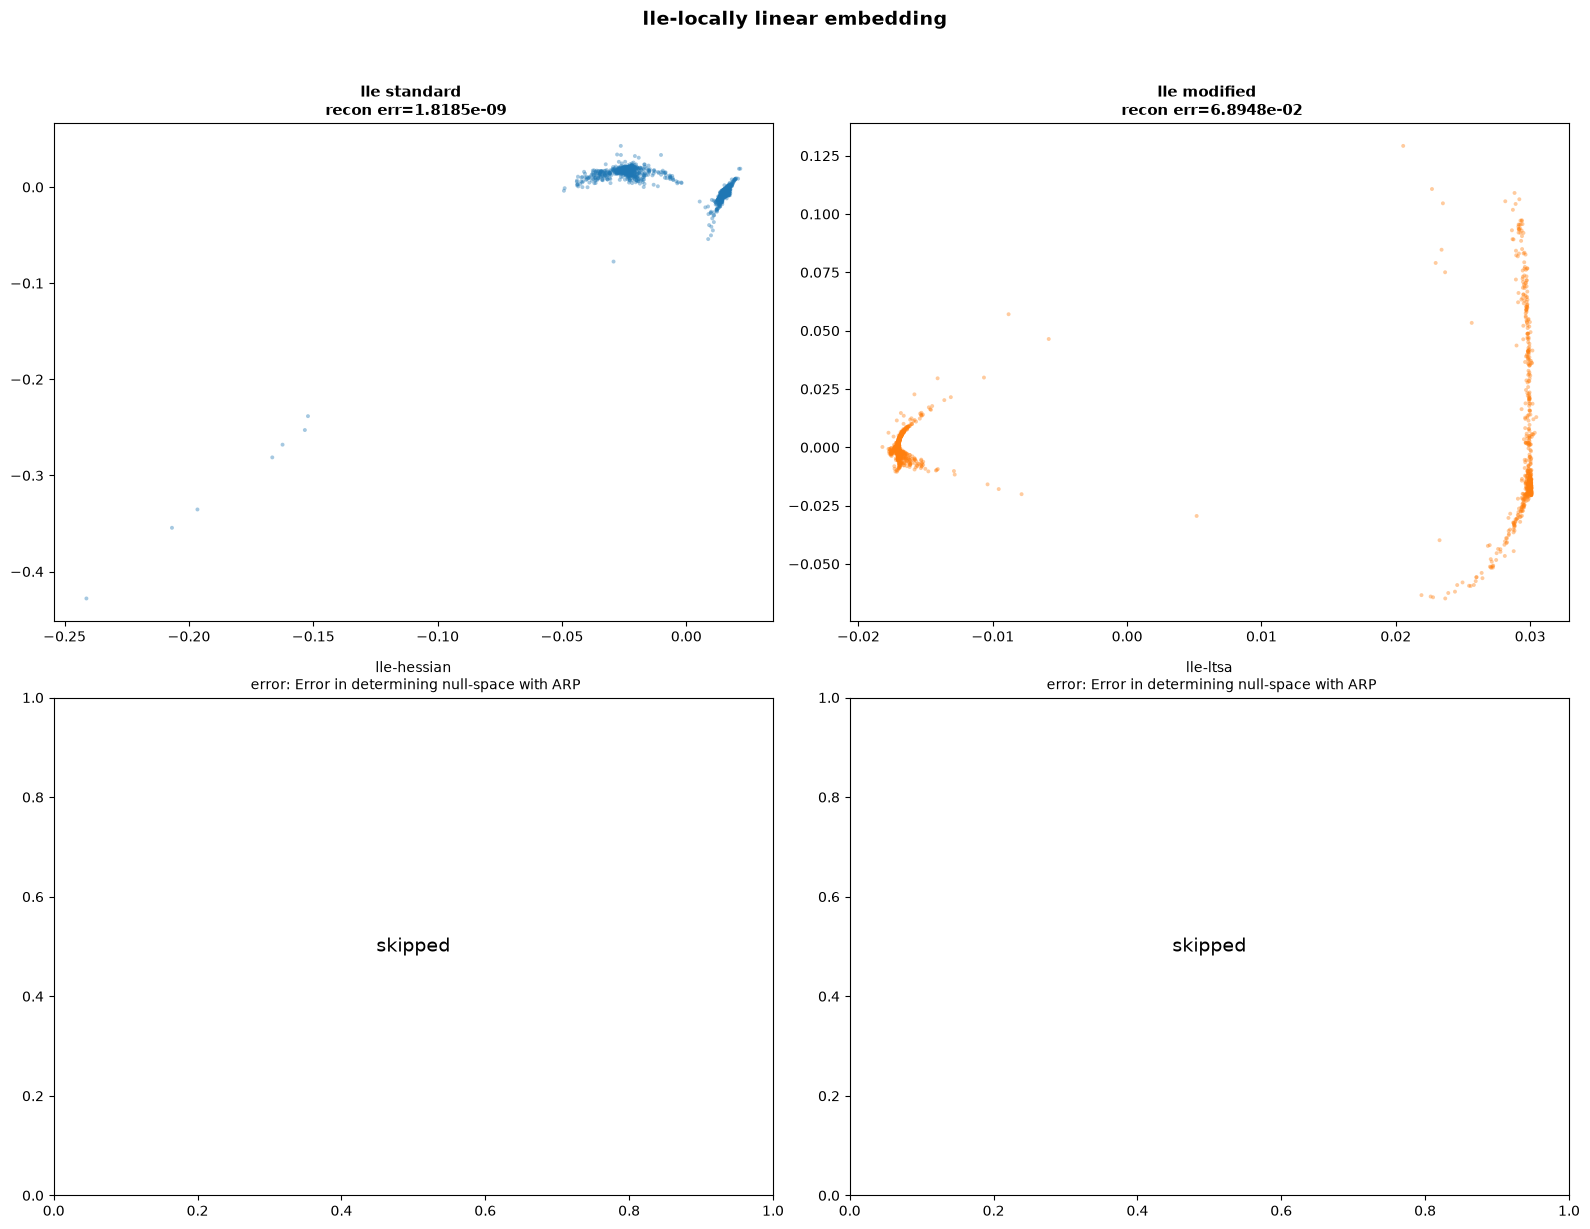

In [15]:
from sklearn.manifold import LocallyLinearEmbedding

lle_methods=['standard','modified','hessian','ltsa']
lle_results={}

max_lle=2000
if x_scaled.shape[0]>max_lle:
    np.random.seed(42)
    lle_idx=np.random.choice(x_scaled.shape[0],max_lle,replace=False)
    x_lle_input=x_scaled[lle_idx]
else:
    x_lle_input=x_scaled

fig,axes=plt.subplots(2,2,figsize=(16,12))
axes=axes.flatten()

for idx,method in enumerate(lle_methods):
    try:
        n_nbrs=12 if method in ['hessian','ltsa']else 10
        lle=LocallyLinearEmbedding(n_neighbors=n_nbrs,n_components=2,method=method,random_state=42,n_jobs=-1)
        x_lle=lle.fit_transform(x_lle_input)
        lle_results[method]=x_lle
        axes[idx].scatter(x_lle[:,0],x_lle[:,1],alpha=0.4,s=8,c=sns.color_palette('tab10')[idx],edgecolors='none')
        axes[idx].set_title(f'lle {method} \n recon err={lle.reconstruction_error_:.4e}',
                            fontsize=11,fontweight='bold')

    except Exception as e:
        axes[idx].set_title(f'lle-{method}\n error: {str(e)[:40]}',fontsize=10)
        axes[idx].text(0.5,0.5,'skipped',transform=axes[idx].transAxes,ha='center',va='center',fontsize=14)


plt.suptitle('lle-locally linear embedding',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

### 2.9 ---autoencoder (deep non-linear dr)


tensorflow not installed,-using truncatedsvd (linear autoencoder equivalent)
 linear autoencoder(truncatedsvd) : (4319, 2) | recon mse=0.382798


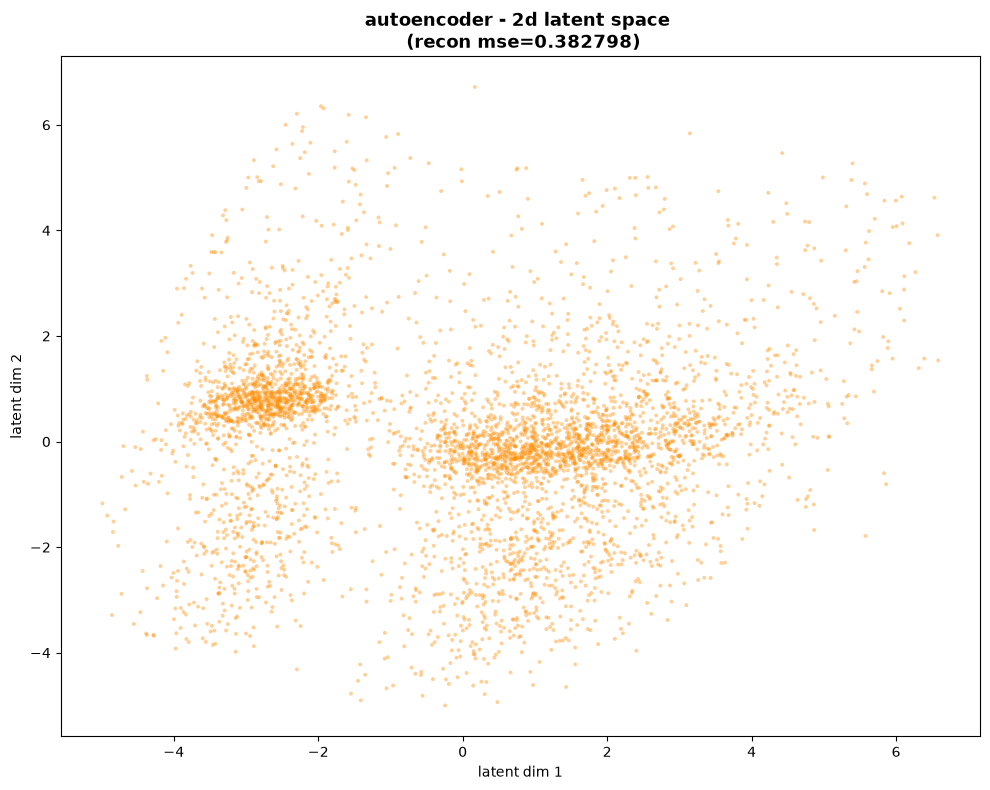

In [16]:
# ── Autoencoder — using sklearn's MLPRegressor as encoder backbone ────────
# Note: For real deep autoencoder, use PyTorch/Keras
# This is a sklearn-native approximation via MLPRegressor

from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

n_features=x_scaled.shape[1]
encoding_dim=2

encoder_pipe=MLPRegressor(hidden_layer_sizes=(max(8,n_features//2),encoding_dim),activation='relu',solver='adam',max_iter=500,random_state=42,early_stopping=True)

# ── Fit as identity mapping (autoencoder principle) ────────────────────────
# We fit input → input; the bottleneck layer IS the encoding
# For 2D viz we extract penultimate layer activations manually

# simplified: use turncatedsvd to simulate a linear autoencoder (exact analogue to pca)
from sklearn.decomposition import TruncatedSVD

svd_ae=TruncatedSVD(n_components=2,random_state=42)
x_svd=svd_ae.fit_transform(x_scaled)


try:
    import tensorflow as tf
    from tensorflow import keras

    input_dim=x_scaled.shape[1]
    enc_dim=2

    inputs=keras.Input(shape=(input_dim,))
    encoded=keras.layers.Dense(32,activation='relu')(inputs)
    encoded=keras.layers.Dense(16,activation='relu')(encoded)
    encoded=keras.layers.Dense(enc_dim,activation='relu',name='bottleneck')(encoded)
    decoded=keras.layers.Dense(16,activation='relu')(encoded)
    decoded=keras.layers.Dense(32,activation='relu')(decoded)
    decoded=keras.layers.Dense(input_dim,activation='linear')(decoded)

    autoencoder=keras.Model(inputs,decoded)
    encoder=keras.Model(inputs,encoded)

    autoencoder.compile(optimizer='adam',loss='mse')
    autoencoder.fit(x_scaled,x_scaled,epochs=50,batch_size=256,validation_split=0.1,verbose=0)



    x_ae_encoded=encoder.predict(x_scaled,verbose=0)
    x_ae_recon=autoencoder.predict(x_scaled,verbose=0)
    ae_recon_err=np.mean((x_scaled -x_ae_recon) ** 2)

    print(f' deep autoencoder (tf) : encoded {x_ae_encoded.shape} | recon mse={ae_recon_err:.6f}')
    ae_available=True

except ImportError:
    print('tensorflow not installed,-using truncatedsvd (linear autoencoder equivalent)')
    x_ae_encoded=x_svd
    ae_recon_err=float(np.mean((x_scaled-svd_ae.inverse_transform(x_svd))**2))
    ae_available=False

    print(f' linear autoencoder(truncatedsvd) : {x_ae_encoded.shape} | recon mse={ae_recon_err:.6f}')


fig,ax=plt.subplots(figsize=(10,8))
ax.scatter(x_ae_encoded[:,0],x_ae_encoded[:,1],alpha=0.4,s=8,c='darkorange',edgecolor='none')
ax.set_title(f'autoencoder - 2d latent space \n (recon mse={ae_recon_err:.6f})',fontsize=13,fontweight='bold')
ax.set_xlabel('latent dim 1')
ax.set_ylabel('latent dim 2')
plt.tight_layout()
plt.show()



### 2.10 -- all dr methods comparison



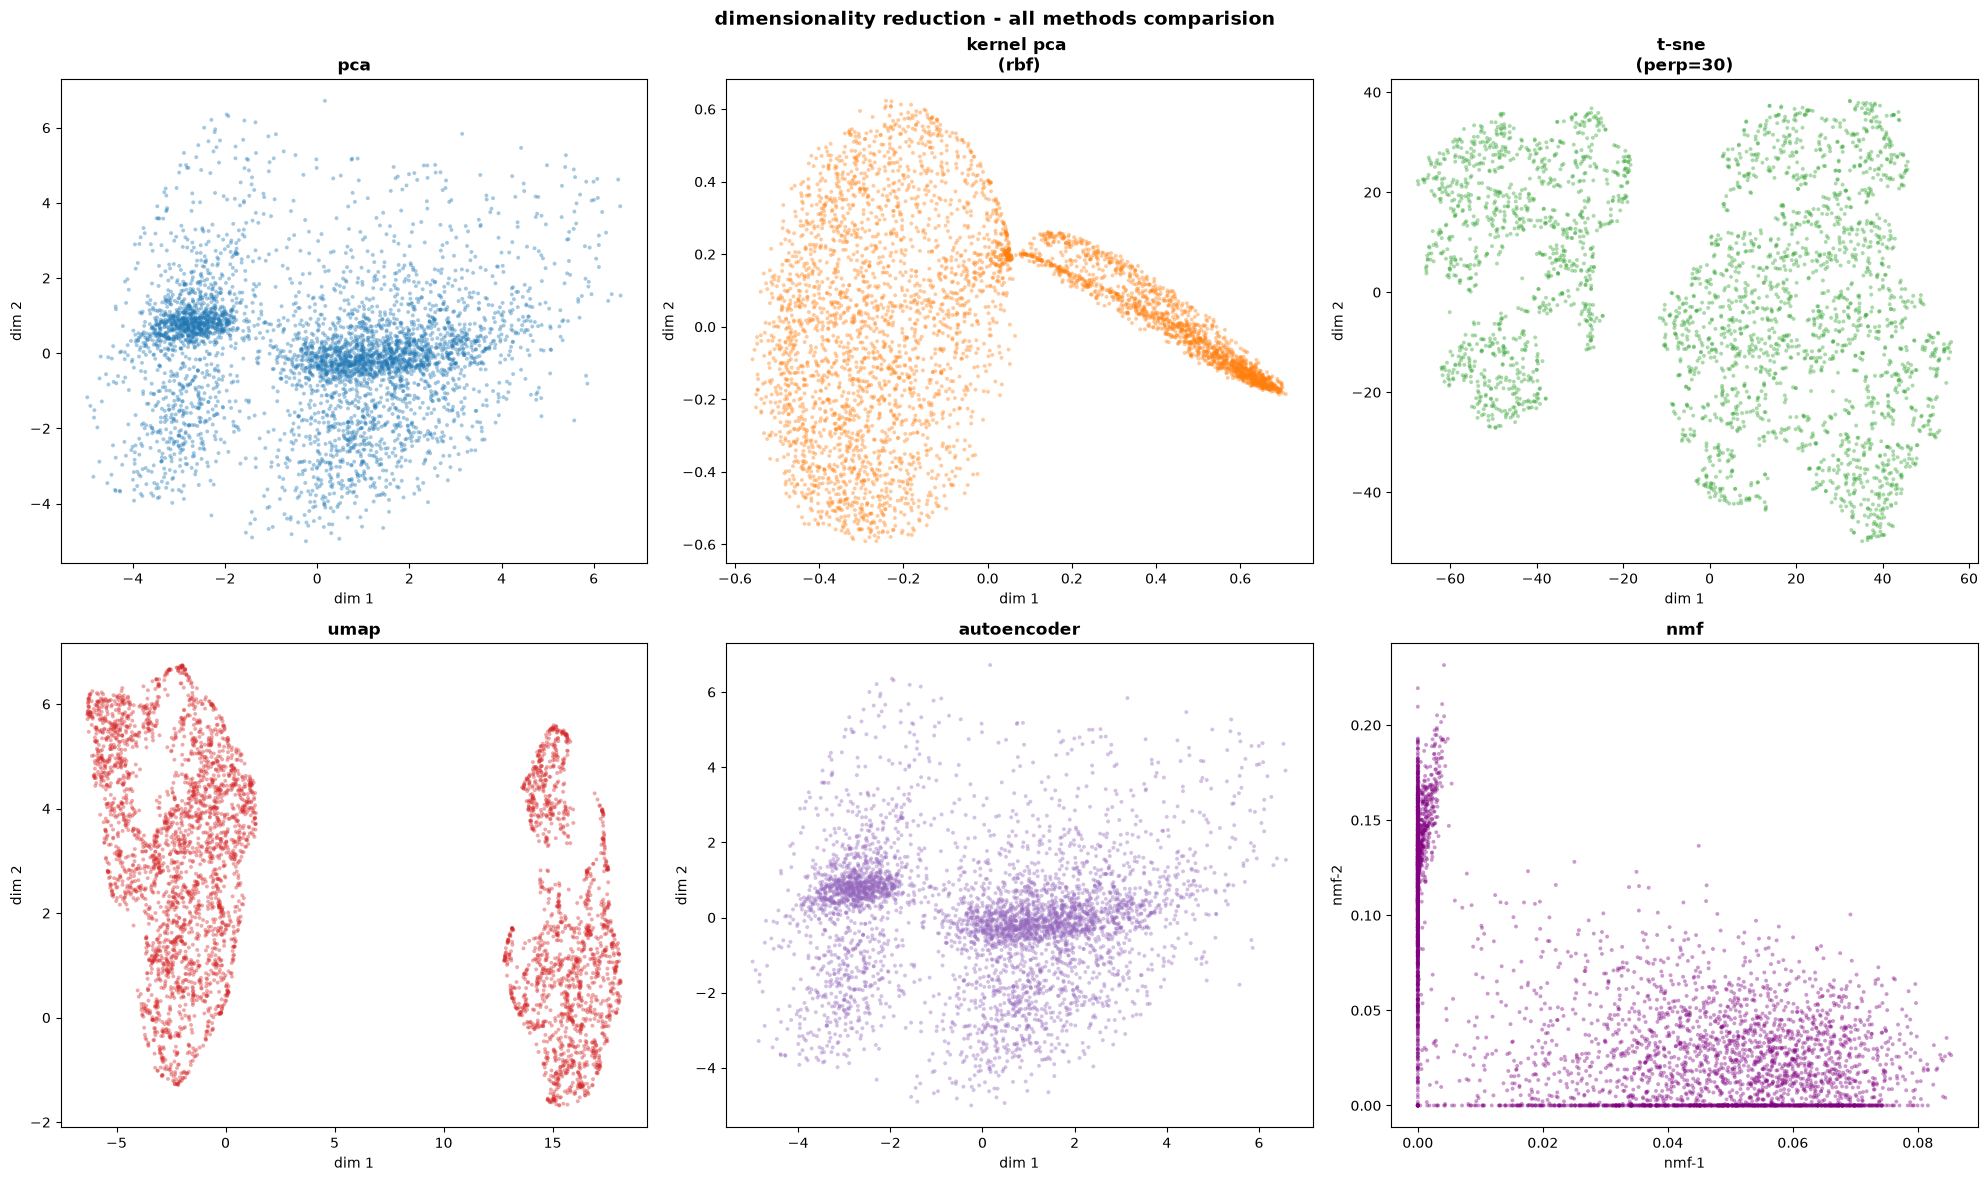

📊 DR Methods Summary:
     Method            Type           Preserves Speed Interpretable
        PCA          Linear     Global variance   ⚡⚡⚡             ✅
 Kernel PCA      Non-linear    Kernel structure    ⚡⚡             ❌
      t-SNE      Non-linear    Local neighbours     ⚡             ❌
       UMAP      Non-linear Local + some global    ⚡⚡             ❌
        NMF          Linear       Non-neg parts   ⚡⚡⚡             ✅
Factor Anal   Probabilistic      Latent factors   ⚡⚡⚡             ✅
     ISOMAP        Manifold  Geodesic distances     ⚡             ❌
        LLE        Manifold      Local geometry     ⚡             ❌
Autoencoder Deep Non-linear      Reconstruction    ⚡⚡             ❌


In [17]:
# -- side by side comparision of all 3d projections

dr_methods={'pca':x_pca[:,:2],
             'kernel pca \n(rbf)': x_kpca_best,
             't-sne \n(perp=30)': x_tsne_best,
             'umap':x_umap_2d,
             'autoencoder':x_ae_encoded,
             }

fig,axes=plt.subplots(2,3,figsize=(20,12))
axes=axes.flatten()
colors_dr=sns.color_palette('tab10',len(dr_methods))

for idx,(name,x_2d) in enumerate(dr_methods.items()):
    n=min(x_2d.shape[0],rfm.shape[0])
    axes[idx].scatter(x_2d[:n,0],x_2d[:n,1],alpha=0.4,s=8,c=[colors_dr[idx]],edgecolors='none')
    axes[idx].set_title(name,fontsize=12,fontweight='bold')
    axes[idx].set_xlabel('dim 1')
    axes[idx].set_ylabel('dim 2')


n=x_nmf.shape[0]
axes[len(dr_methods)].scatter(x_nmf[:,0],x_nmf[:,1],alpha=0.4,s=8,c='purple',edgecolors='none')
axes[len(dr_methods)].set_title('nmf',fontsize=12,fontweight='bold')
axes[len(dr_methods)].set_xlabel('nmf-1')
axes[len(dr_methods)].set_ylabel('nmf-2')

for j in range(len(dr_methods)+1,len(axes)):
    axes[j].axis('off')

plt.suptitle('dimensionality reduction - all methods comparision',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

print('📊 DR Methods Summary:')
summary_dr = pd.DataFrame([
    {'Method': 'PCA',        'Type': 'Linear',        'Preserves': 'Global variance',     'Speed': '⚡⚡⚡', 'Interpretable': '✅'},
    {'Method': 'Kernel PCA', 'Type': 'Non-linear',    'Preserves': 'Kernel structure',    'Speed': '⚡⚡',   'Interpretable': '❌'},
    {'Method': 't-SNE',      'Type': 'Non-linear',    'Preserves': 'Local neighbours',    'Speed': '⚡',     'Interpretable': '❌'},
    {'Method': 'UMAP',       'Type': 'Non-linear',    'Preserves': 'Local + some global', 'Speed': '⚡⚡',   'Interpretable': '❌'},
    {'Method': 'NMF',        'Type': 'Linear',        'Preserves': 'Non-neg parts',       'Speed': '⚡⚡⚡', 'Interpretable': '✅'},
    {'Method': 'Factor Anal','Type': 'Probabilistic', 'Preserves': 'Latent factors',      'Speed': '⚡⚡⚡', 'Interpretable': '✅'},
    {'Method': 'ISOMAP',     'Type': 'Manifold',      'Preserves': 'Geodesic distances',  'Speed': '⚡',     'Interpretable': '❌'},
    {'Method': 'LLE',        'Type': 'Manifold',      'Preserves': 'Local geometry',      'Speed': '⚡',     'Interpretable': '❌'},
    {'Method': 'Autoencoder','Type': 'Deep Non-linear','Preserves': 'Reconstruction',     'Speed': '⚡⚡',   'Interpretable': '❌'},
])
print(summary_dr.to_string(index=False))


# 3-- association rule mining

> **Goal:** Discover "if X then Y" buying patterns across customer transactions  
> **Methods:** Apriori · FP-Growth  
> **Metrics:** Support · Confidence · Lift · Conviction · Leverage · Zhang's Metric

| Metric | Formula | Interpretation |
|---|---|---|
| **Support** | P(A∩B) | How often this pair appears |
| **Confidence** | P(B\|A) | How often Y bought when X bought |
| **Lift** | P(A∩B) / P(A)P(B) | How much better than random (>1 = positive) |
| **Conviction** | (1-P(B)) / (1-Conf) | How much A implies B directionally |
| **Leverage** | P(A∩B) - P(A)P(B) | Absolute deviation from independence |


In [18]:
# --- Build Transaction Matrix for Market Basket Analysis ---
# Safety Check: If raw_df is not in namespace, load it automatically
if 'raw_df' not in globals() or raw_df is None:
    raw_data_path = RAW_DIR / 'Online Retail.xlsx'
    if not raw_data_path.exists():
        raise FileNotFoundError(f"Raw transaction dataset not found at: {raw_data_path}")
    print("Loading raw transactions for Market Basket Analysis...")
    raw_df = pd.read_excel(raw_data_path).dropna(subset=['CustomerID'])
    print(f"Loaded raw_df: {raw_df.shape[0]:,} rows")

# Use top N products for performance
top_n_products = 100
top_products = raw_df['StockCode'].value_counts().head(top_n_products).index.tolist()
df_top = raw_df[raw_df['StockCode'].isin(top_products)]

basket = (df_top.groupby(['InvoiceNo', 'StockCode'])['Quantity']
          .sum()
          .unstack(fill_value=0)
          .reset_index()
          .drop('InvoiceNo', axis=1))
basket = (basket > 0).astype(bool)

basket = basket[basket.sum(axis=1) >= 2]

print(f"Transaction matrix : {basket.shape}")
print(f"{basket.shape[0]:,} invoices x {basket.shape[1]} products")
print(f"Sparsity : {(~basket).mean().mean():.1%}")


Transaction matrix : (12307, 100)
12,307 invoices x 100 products
Sparsity : 93.8%


 apriori frequent itemsets: 899
 1-itemsets: 100
 2-itemsets: 455
 3-itemsets: 277
 4-itemsets: 67


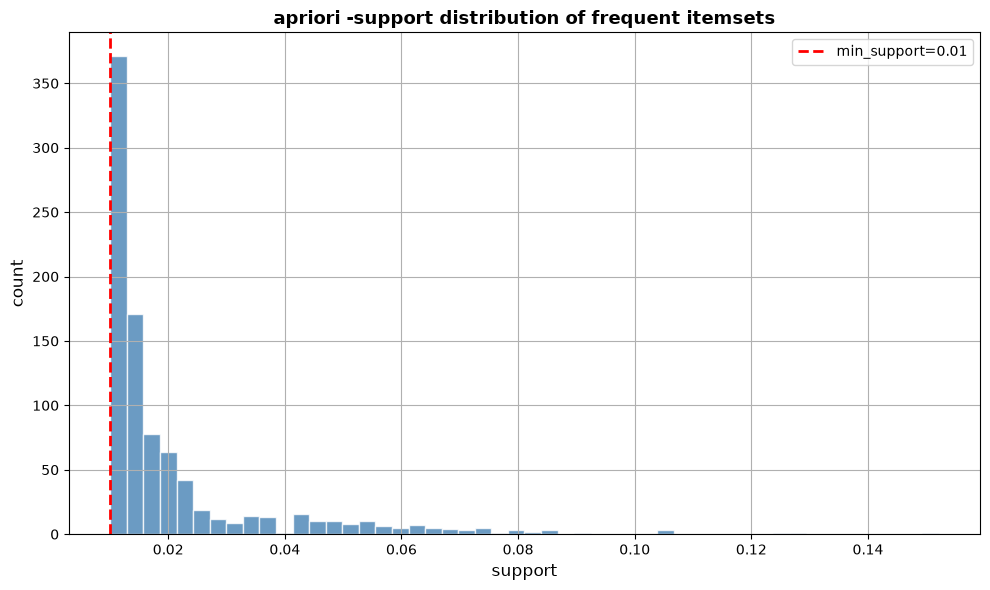

In [19]:
#--- aprior algorithm
min_support=0.01
min_confidence=0.3
min_lift=1.0

frequent_itemsets_apriori=apriori(basket,min_support=min_support,use_colnames=True,max_len=4,verbose=0)
frequent_itemsets_apriori['length']=frequent_itemsets_apriori['itemsets'].apply(len)


print(f' apriori frequent itemsets: {len(frequent_itemsets_apriori)}')
print(f' 1-itemsets: {(frequent_itemsets_apriori.length==1).sum()}')
print(f' 2-itemsets: {(frequent_itemsets_apriori.length==2).sum()}')
print(f' 3-itemsets: {(frequent_itemsets_apriori.length==3).sum()}')
print(f' 4-itemsets: {(frequent_itemsets_apriori.length==4).sum()}')

# support distribution 
fig,ax=plt.subplots(figsize=(10,6))
frequent_itemsets_apriori['support'].hist(bins=50,ax=ax,color='steelblue',edgecolor='white',alpha=0.8)
ax.axvline(x=min_support,color='red',linestyle='--',lw=2,label=f'min_support={min_support}')
ax.set_xlabel('support',fontsize=12)
ax.set_ylabel('count',fontsize=12)
ax.set_title('apriori -support distribution of frequent itemsets',fontsize=13,fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
#-- fp - growth algorithm

print(f' running fp-growth')
frequent_itemsets_fpgrowth=fpgrowth(basket,min_support=min_support,use_colnames=True,max_len=4)
frequent_itemsets_fpgrowth['length']=frequent_itemsets_fpgrowth['itemsets'].apply(len)

print(f' fp-growth frequent itemsets: {len(frequent_itemsets_fpgrowth)}')
print(f' (should match apriori - same itemsets, faster algorithm)')

import time

t0=time.time()
_=apriori(basket,min_support=min_support,use_colnames=True,max_len=3)
t_apriori=time.time() -t0

t0=time.time()
_=fpgrowth(basket,min_support=min_support,use_colnames=True,max_len=3)
t_fpgrowth=time.time() -t0

print(f'\n perfromance')
print(f' apriori time: {t_apriori:.3f}s')
print(f" fpgrowth : {t_fpgrowth:.3f}s ({'faster' if t_fpgrowth < t_apriori else 'slower'})")
print(f' fp-growth =no candidate generation -> much faster on large datasets')



 running fp-growth
 fp-growth frequent itemsets: 899
 (should match apriori - same itemsets, faster algorithm)

 perfromance
 apriori time: 0.448s
 fpgrowth : 1.154s (slower)
 fp-growth =no candidate generation -> much faster on large datasets


In [21]:
#-- generate association rules---
rules=association_rules(frequent_itemsets_fpgrowth,metric='lift',min_threshold=min_lift,num_itemsets=len(frequent_itemsets_fpgrowth))

# add addtional metrics

rules['leverage']=rules['support'] - rules['antecedent support'] * rules['consequent support']
rules['n_ant']=rules['antecedents'].apply(len)
rules['n_cons']=rules['consequents'].apply(len)
# rules['ant_str']=rules['antecedents'].apply(lambda x: ', '.join(list(x)))
# rules['cons_str']=rules['consequents'].apply(lambda x: ', '.join(list(x)))
rules['ant_str'] = rules['antecedents'].apply(lambda x: ', '.join(map(str, x)))
rules['cons_str'] = rules['consequents'].apply(lambda x: ', '.join(map(str, x)))


# filter meaningul rules
strong_rules=rules[
    (rules['confidence']>=min_confidence) &
    (rules['lift']>=min_lift)

].sort_values('lift',ascending=False)

print(f' total rules generated: {len(rules)}')
print(f' strong rules (conf >={min_confidence},lift>={min_lift}): {len(strong_rules)}')
print(f'\n top 10 rules by lift')
display_cols=['ant_str','cons_str','support','confidence','lift','leverage','conviction']
print(strong_rules[display_cols].head(10).to_string(index=False))


 total rules generated: 3496
 strong rules (conf >=0.3,lift>=1.0): 1688

 top 10 rules by lift
            ant_str            cons_str  support  confidence      lift  leverage  conviction
       23203, 20725       85099B, 23209 0.011051    0.527132 25.440827  0.010616    2.070937
      85099B, 23209        23203, 20725 0.011051    0.533333 25.440827  0.010616    2.097935
       22386, 20725       22384, 85099B 0.010482    0.542017 24.081591  0.010047    2.134341
      22384, 85099B        22386, 20725 0.010482    0.465704 24.081591  0.010047    1.835427
       22698, 22699        22697, 22423 0.019420    0.548165 18.038151  0.018343    2.145941
       22697, 22423        22698, 22699 0.019420    0.639037 18.038151  0.018343    2.672224
       22698, 22423        22697, 22699 0.019420    0.773463 17.595206  0.018316    4.220239
       22697, 22699        22698, 22423 0.019420    0.441774 17.595206  0.018316    1.746413
              22698 22697, 22699, 22423 0.019420    0.438532 17.2981

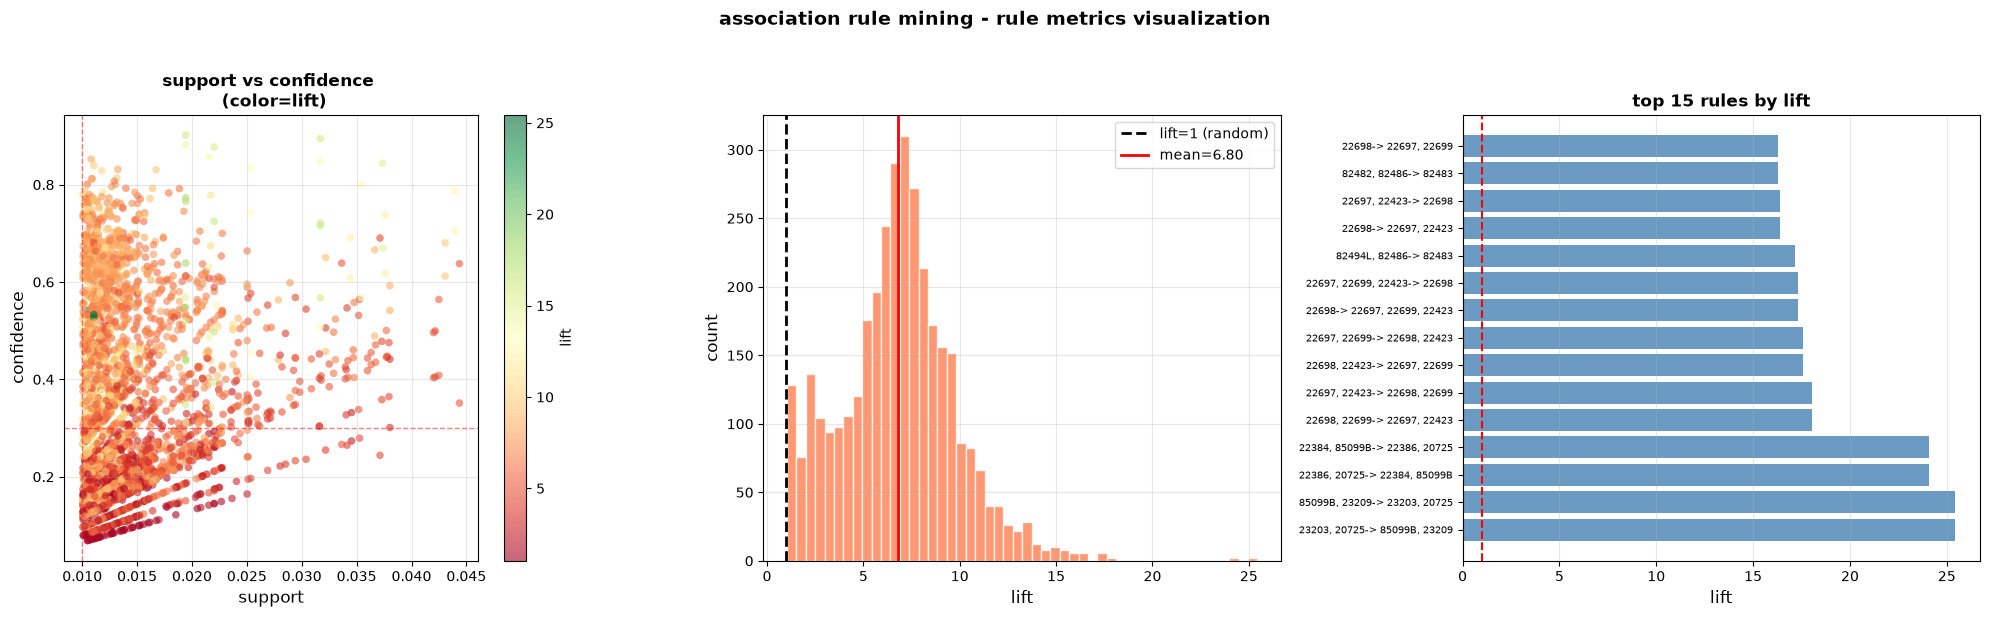

In [22]:
#-- association rules visualization

fig,axes=plt.subplots(1,3,figsize=(20,6))
sc=axes[0].scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap='RdYlGn',alpha=0.6,s=30,edgecolor='none')

plt.colorbar(sc,ax=axes[0],label='lift')
axes[0].set_xlabel('support',fontsize=12)
axes[0].set_ylabel('confidence',fontsize=12)
axes[0].set_title('support vs confidence \n (color=lift)', fontsize=12,fontweight='bold')
axes[0].axvline(x=min_support,color='red',linestyle='--',alpha=0.5,lw=1)
axes[0].axhline(y=min_confidence,color='red',linestyle='--',alpha=0.5,lw=1)
axes[0].grid(True,alpha=0.3)

#lift distribution
axes[1].hist(rules['lift'],bins=50,color='coral',edgecolor='white',alpha=0.8)
axes[1].axvline(x=1.0,color='black',linestyle='--',lw=2,label='lift=1 (random)')
axes[1].axvline(x=rules['lift'].mean(),color='red',linestyle='-',lw=2,label=f'mean={rules["lift"].mean():.2f}')
axes[1].set_xlabel('lift',fontsize=12)
axes[1].set_ylabel('count',fontsize=12)
axes[1].legend()
axes[1].grid(True,alpha=0.3)

# top 15 rules by lift - horizontal bar
top15=strong_rules.head(15)
labels=[f' {a}-> {c}' for a,c in zip(top15['ant_str'],top15['cons_str'])]
axes[2].barh(range(len(labels)),top15['lift'].values,color='steelblue',alpha=0.8)
axes[2].set_yticks(range(len(labels)))
axes[2].set_yticklabels(labels,fontsize=7)
axes[2].set_xlabel('lift',fontsize=12)
axes[2].set_title('top 15 rules by lift',fontsize=12,fontweight='bold')
axes[2].axvline(x=1.0,color='red',linestyle='--',lw=1.5)
axes[2].grid(True,alpha=0.3,axis='x'
)

plt.suptitle('association rule mining - rule metrics visualization',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()















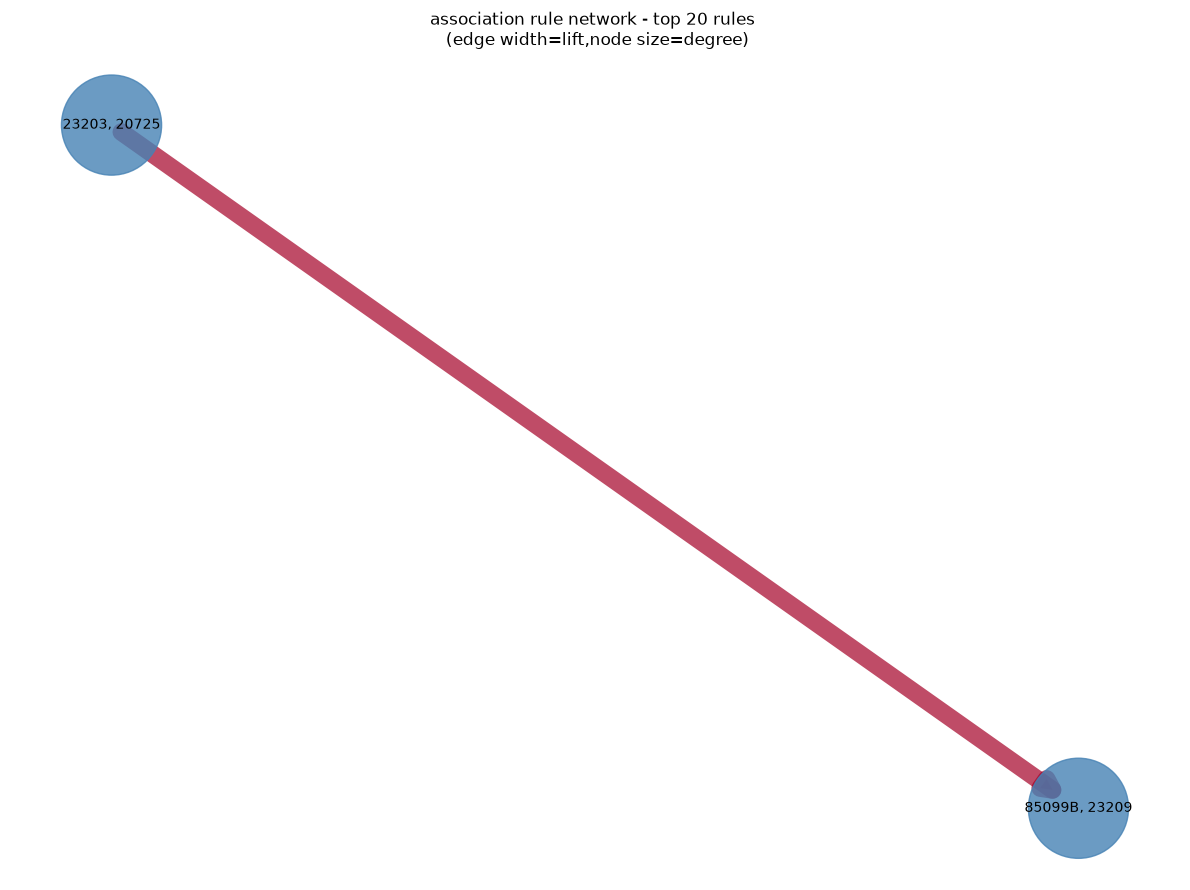

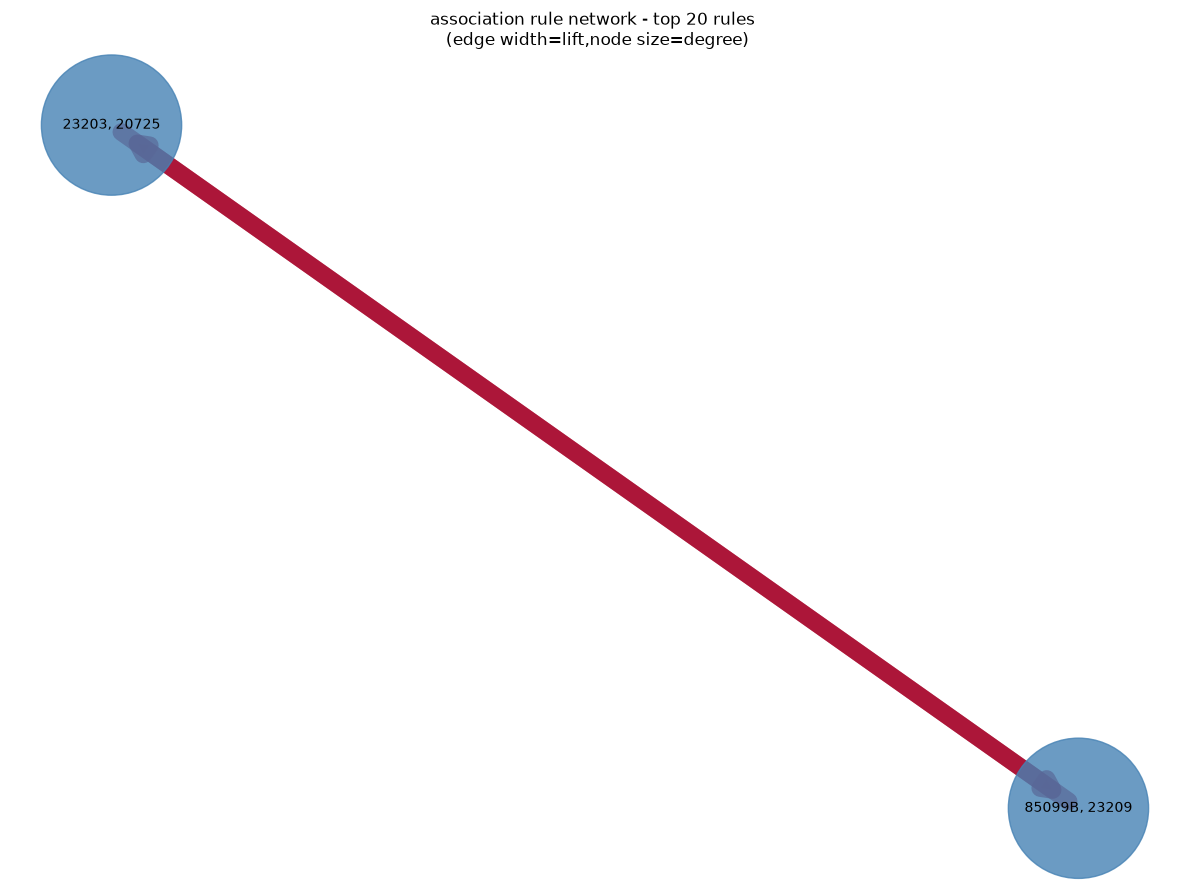

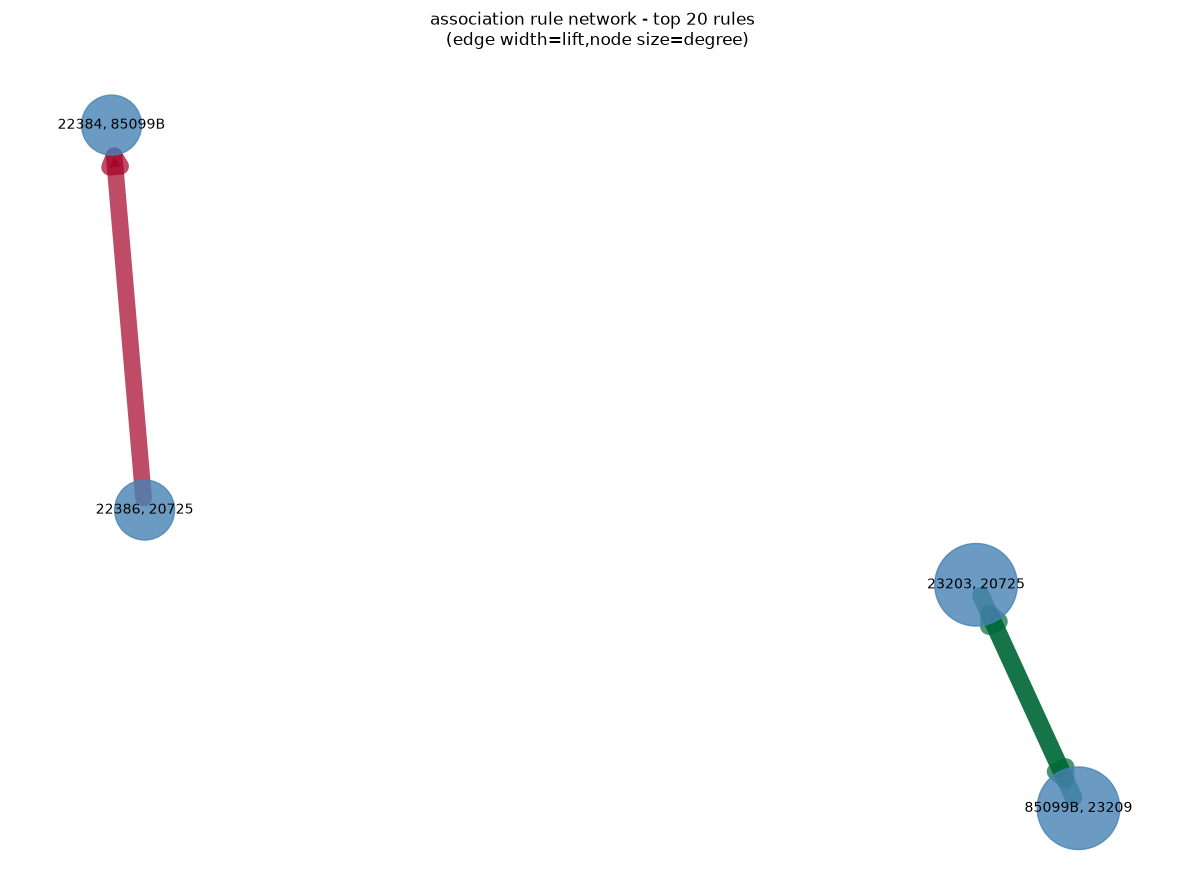

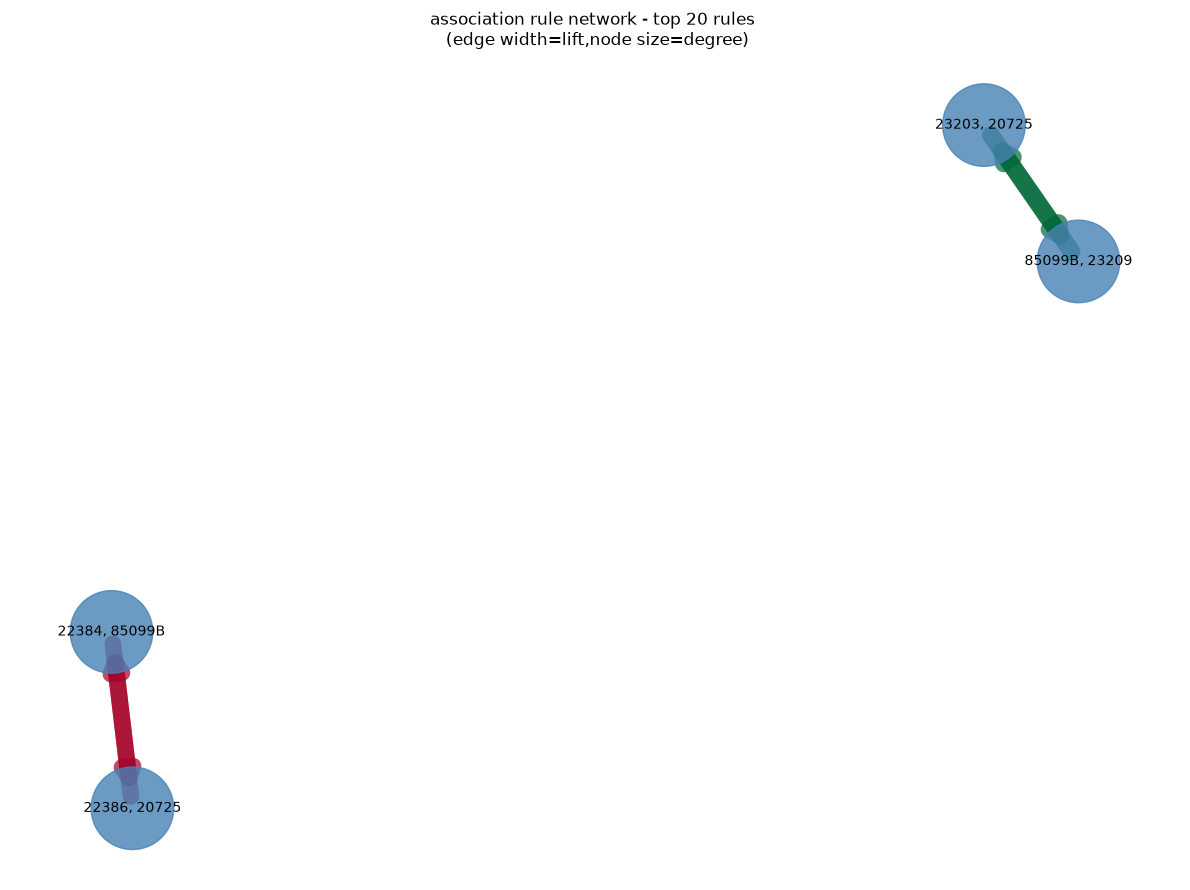

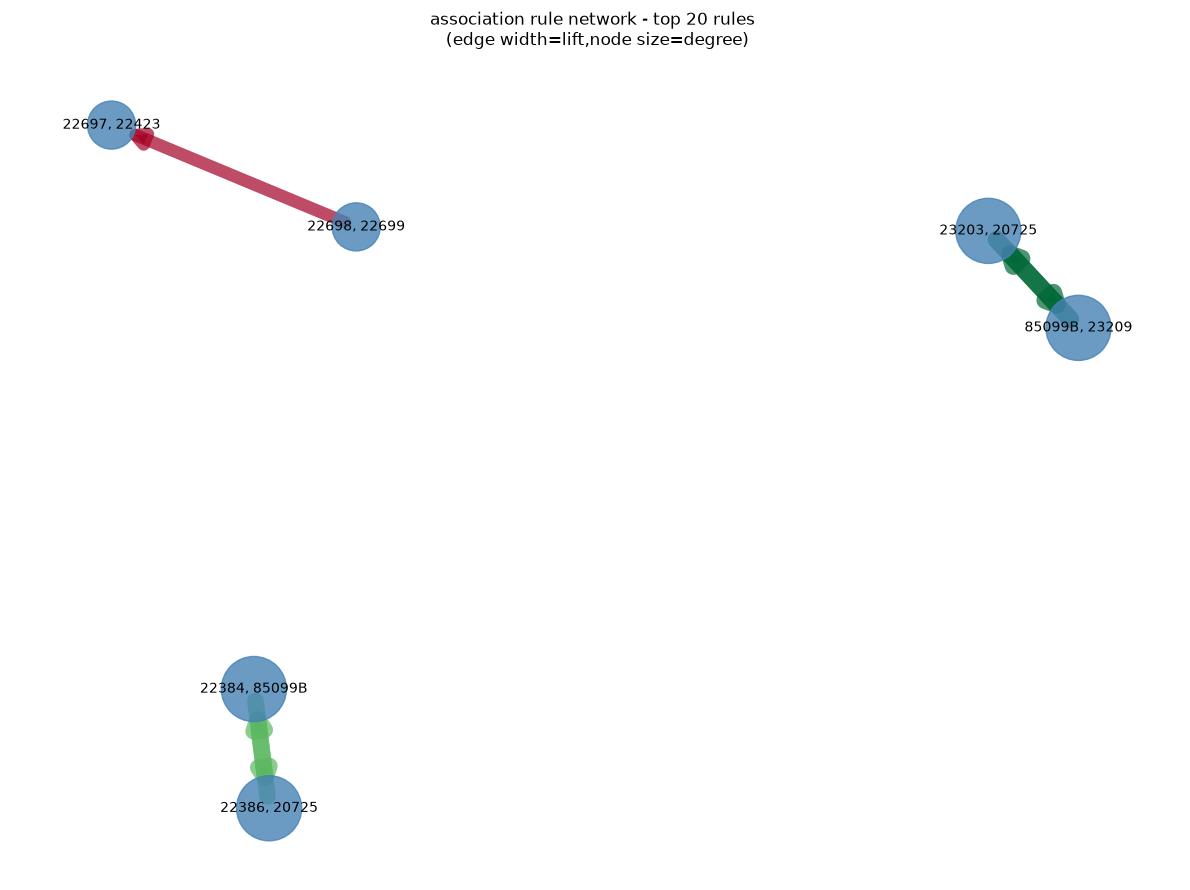

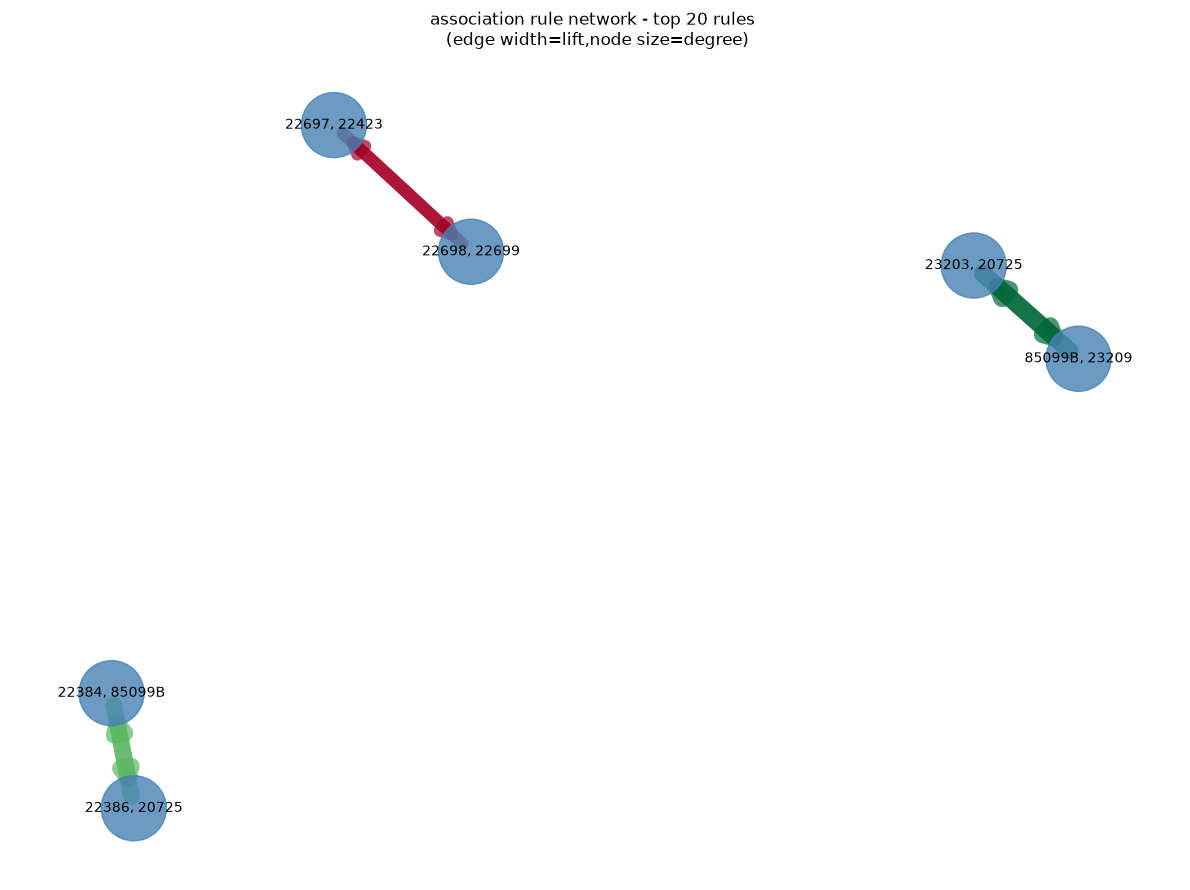

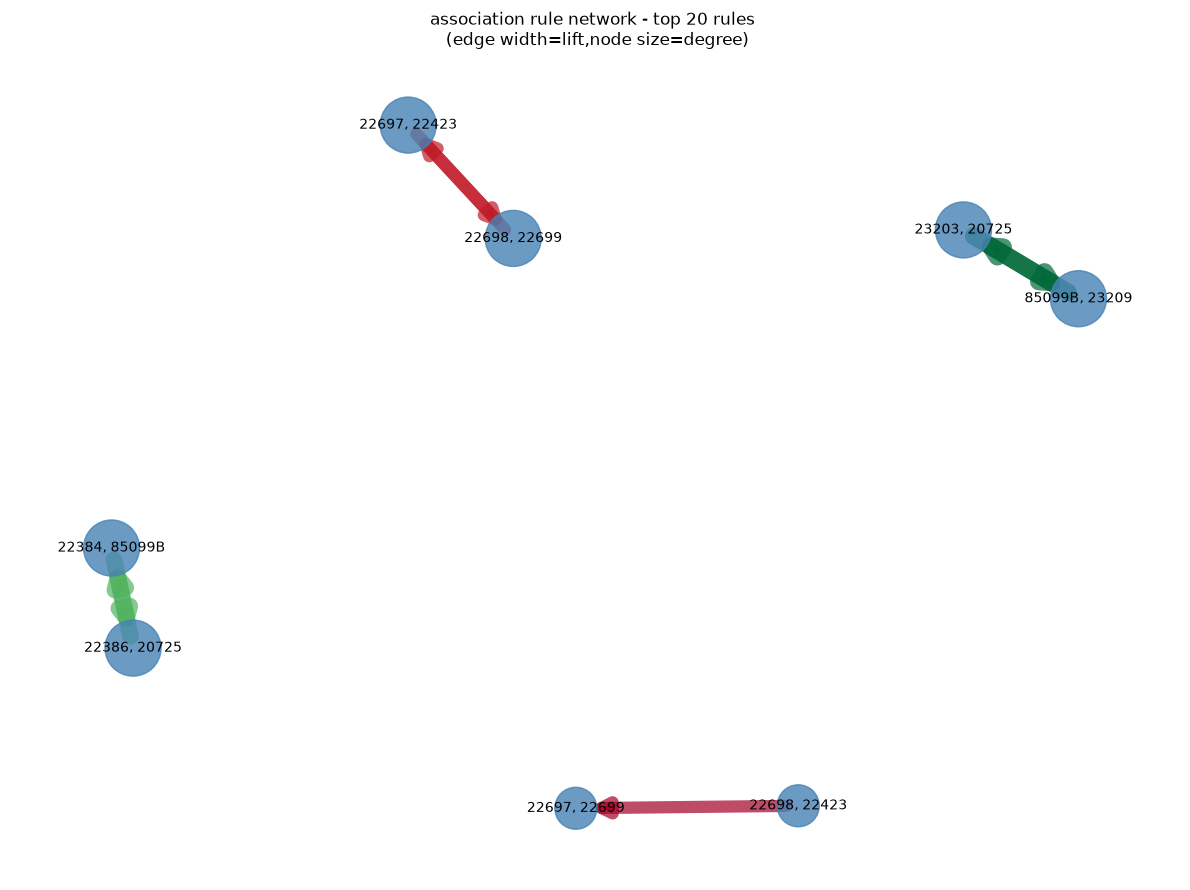

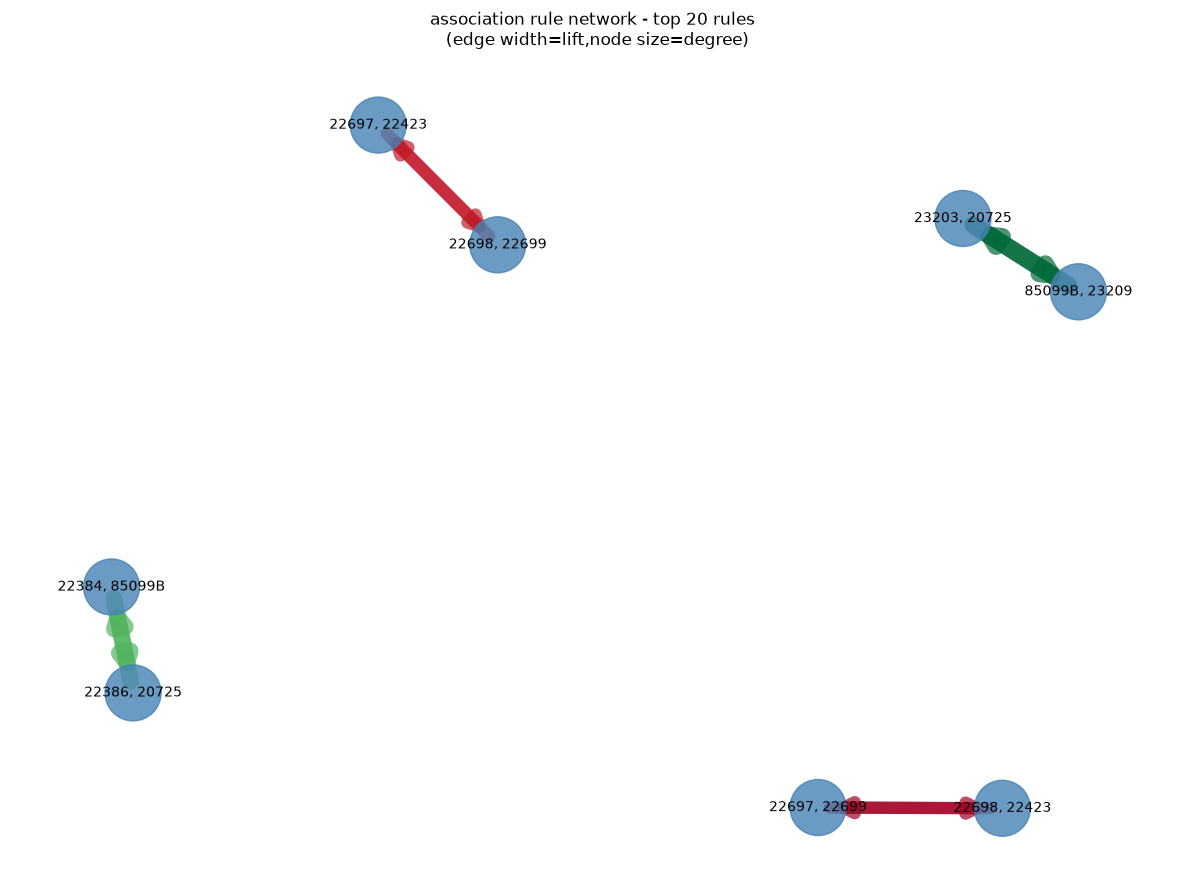

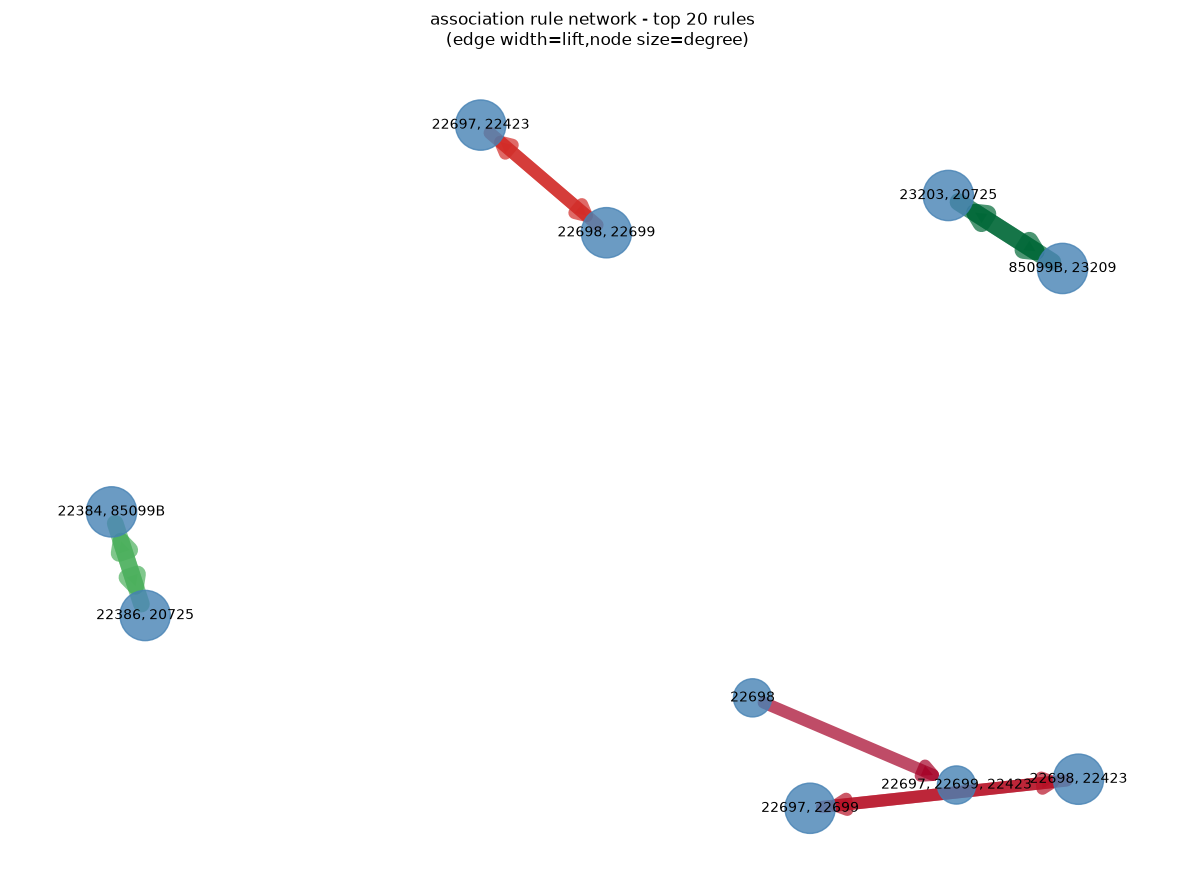

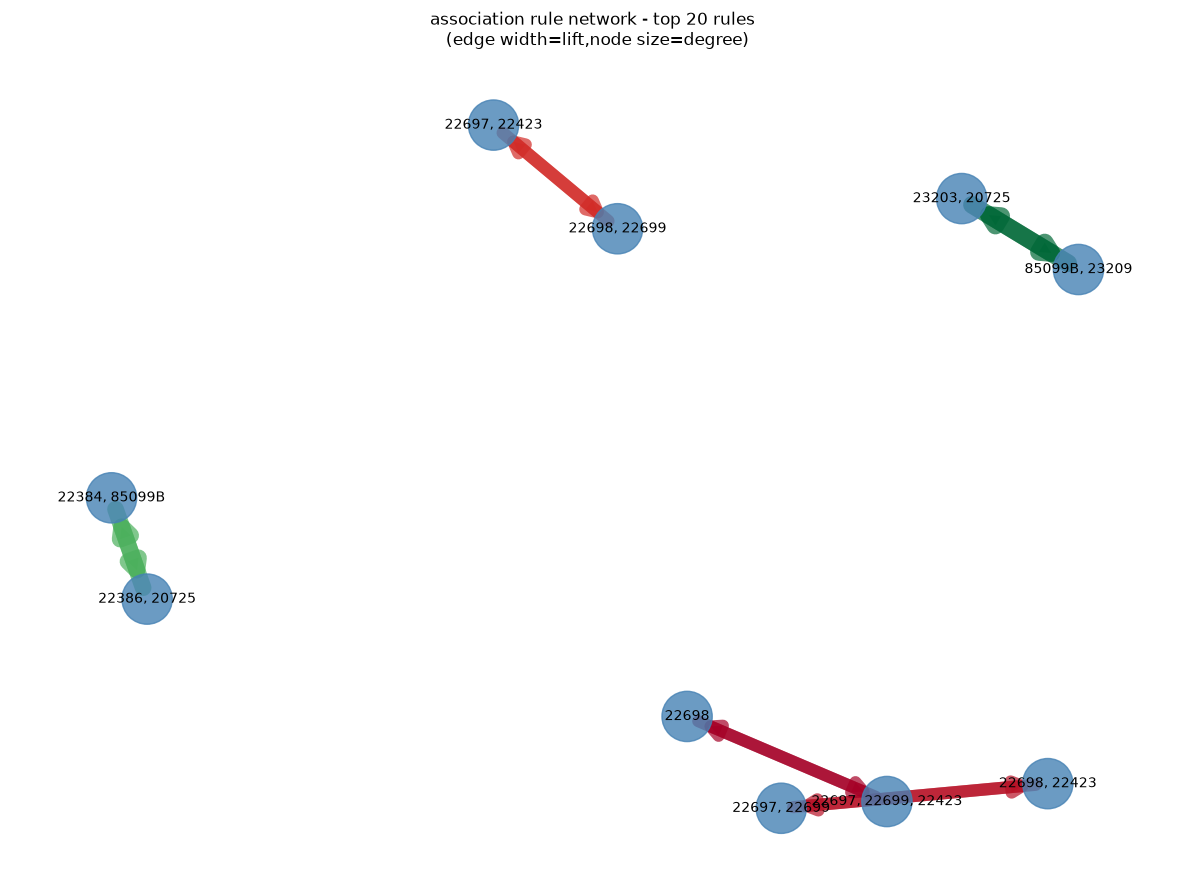

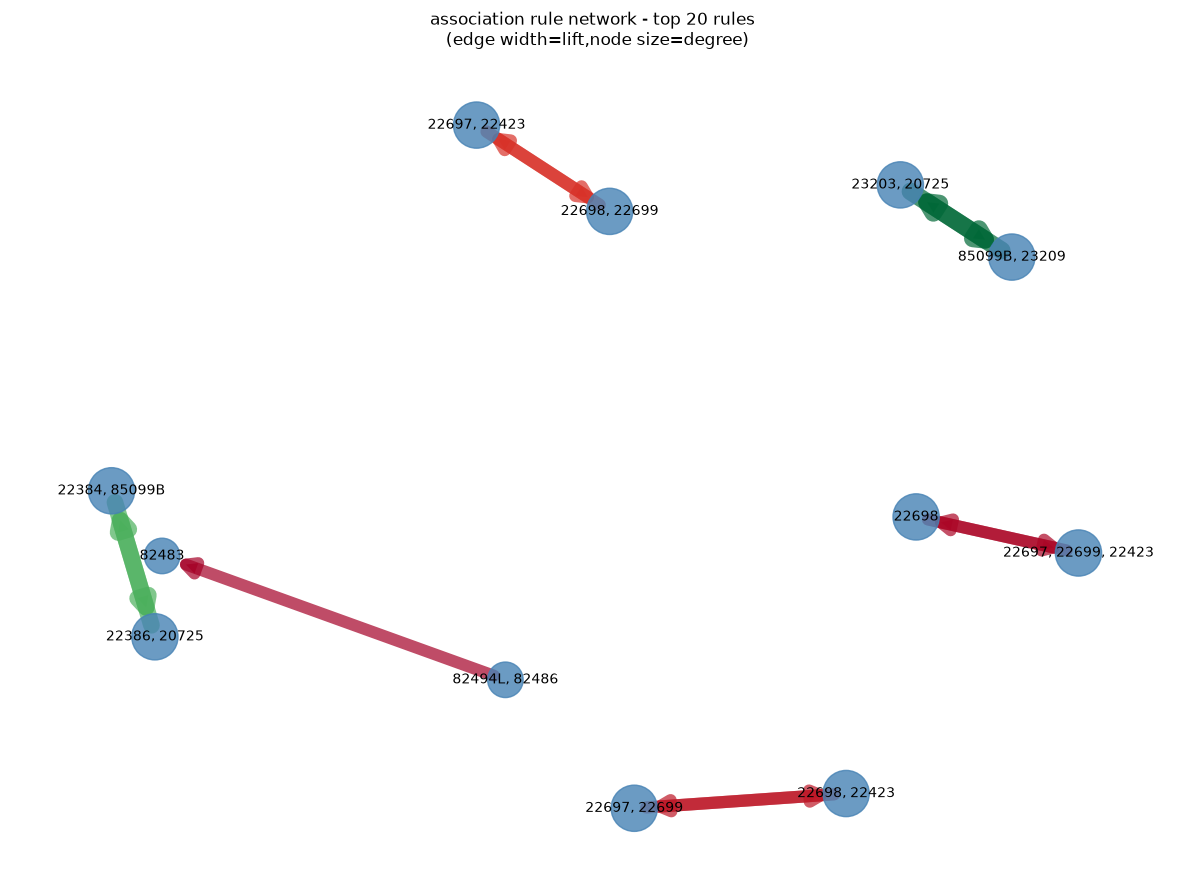

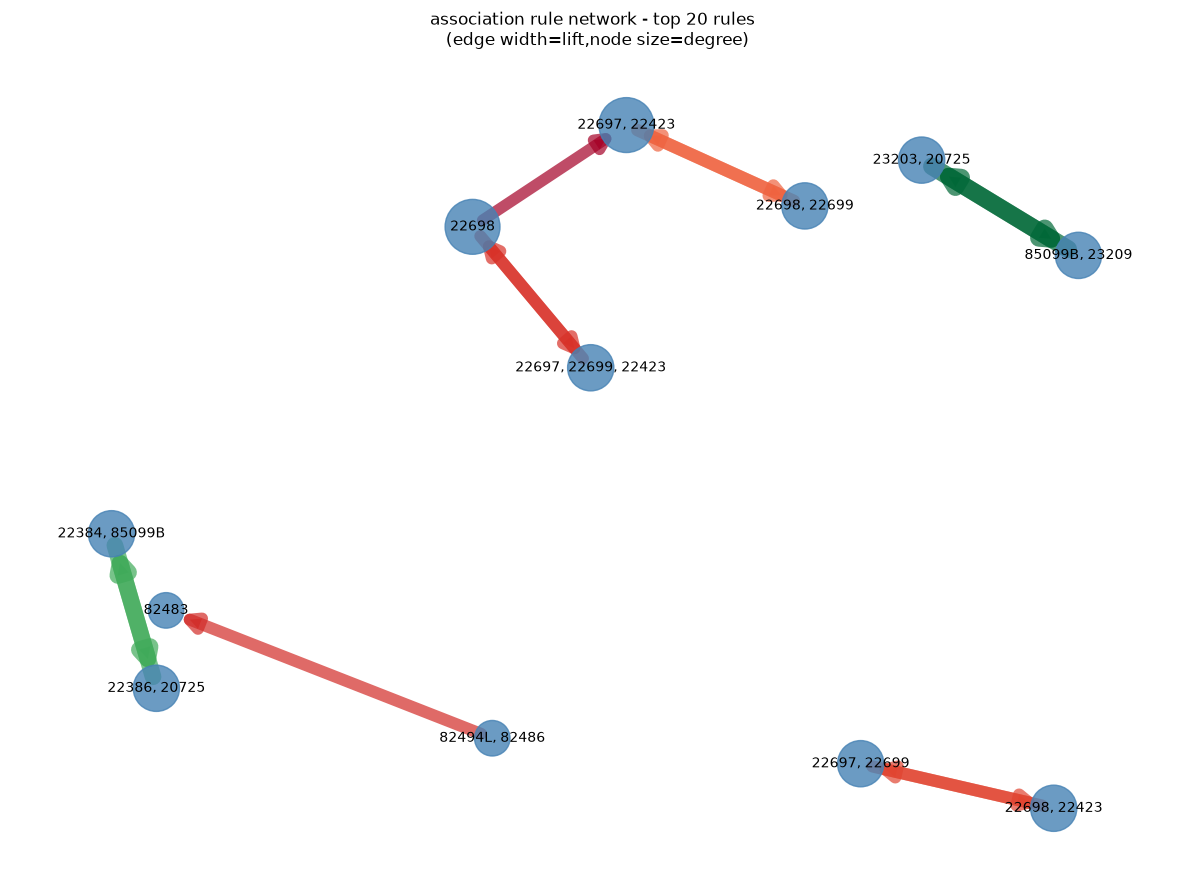

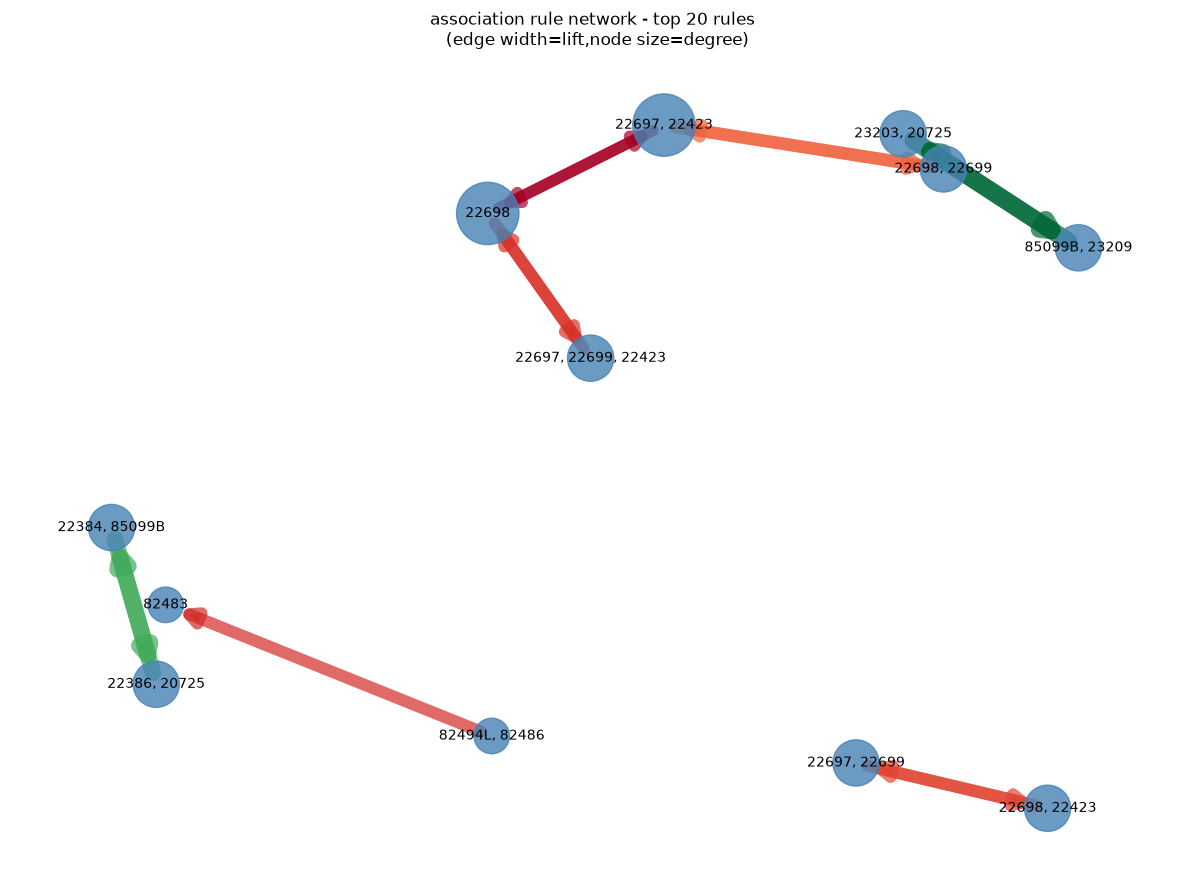

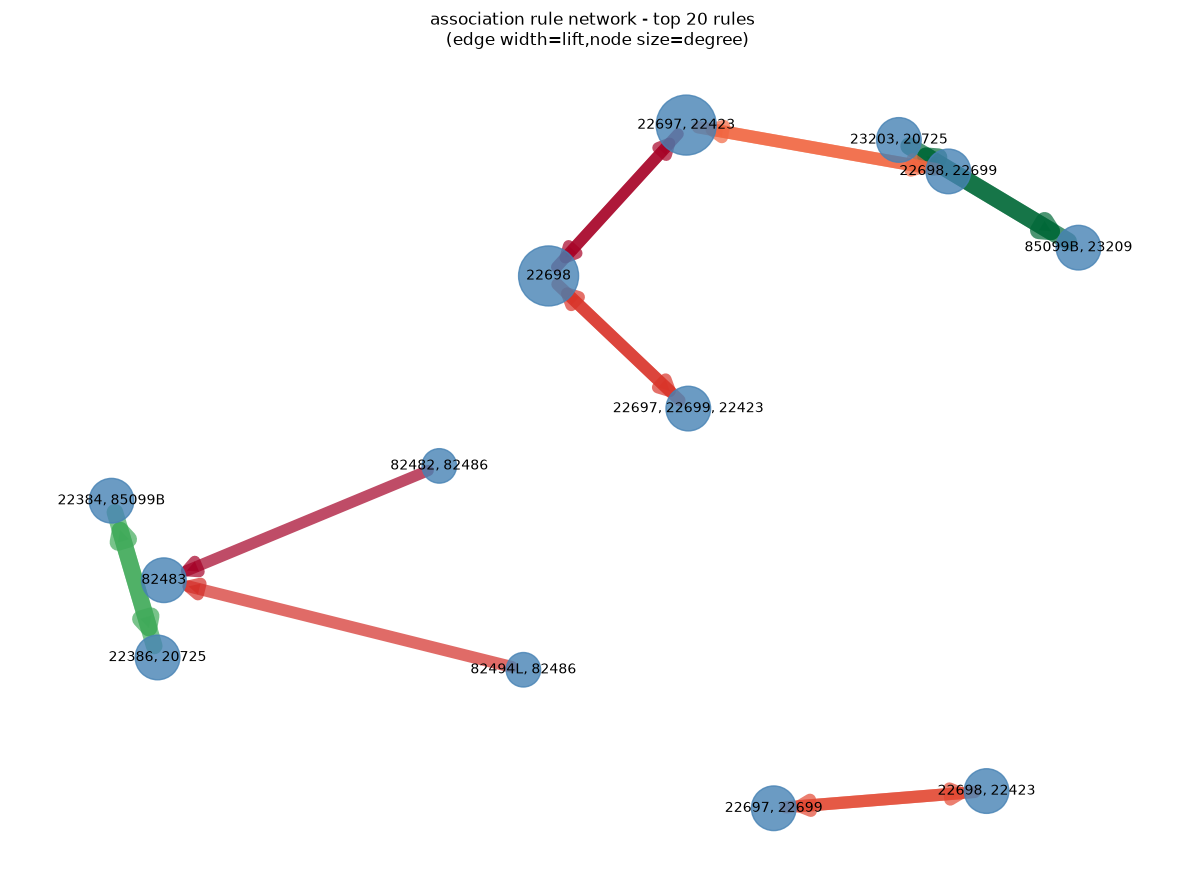

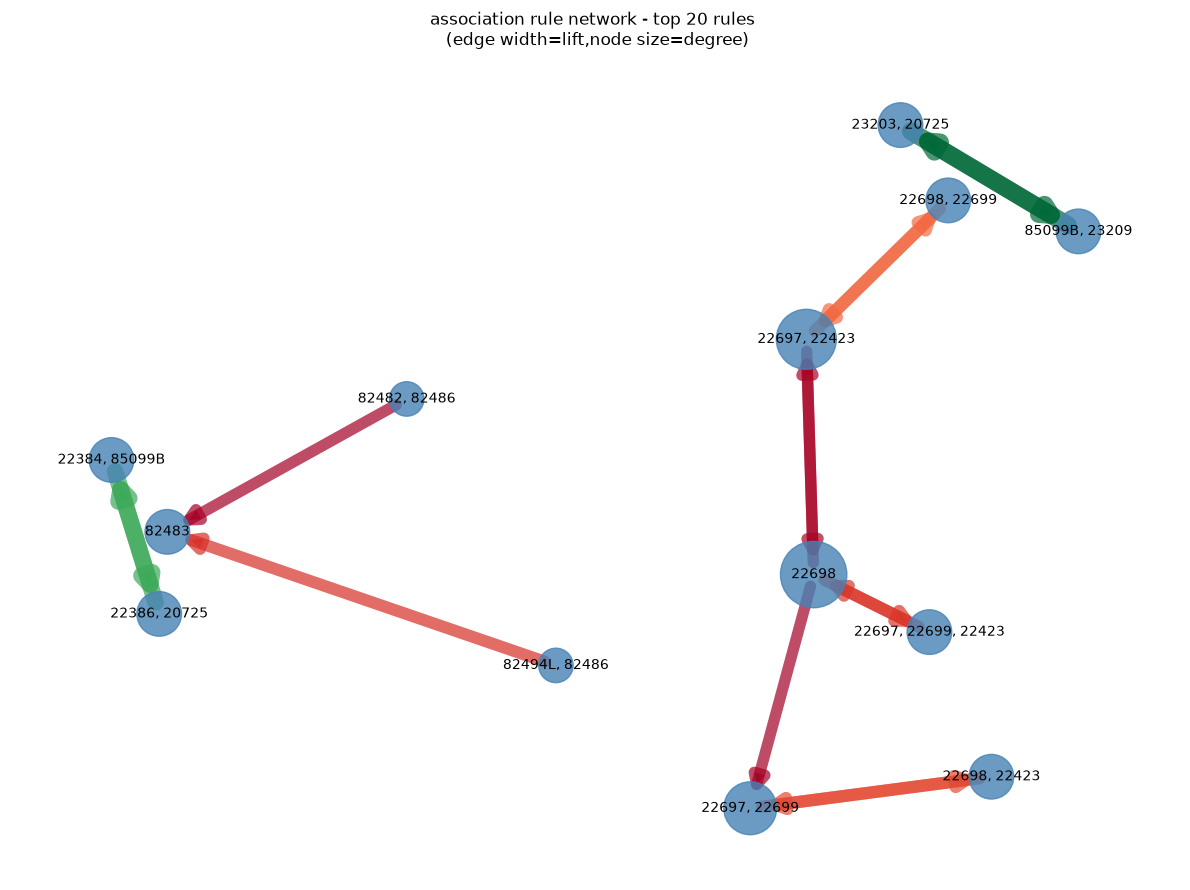

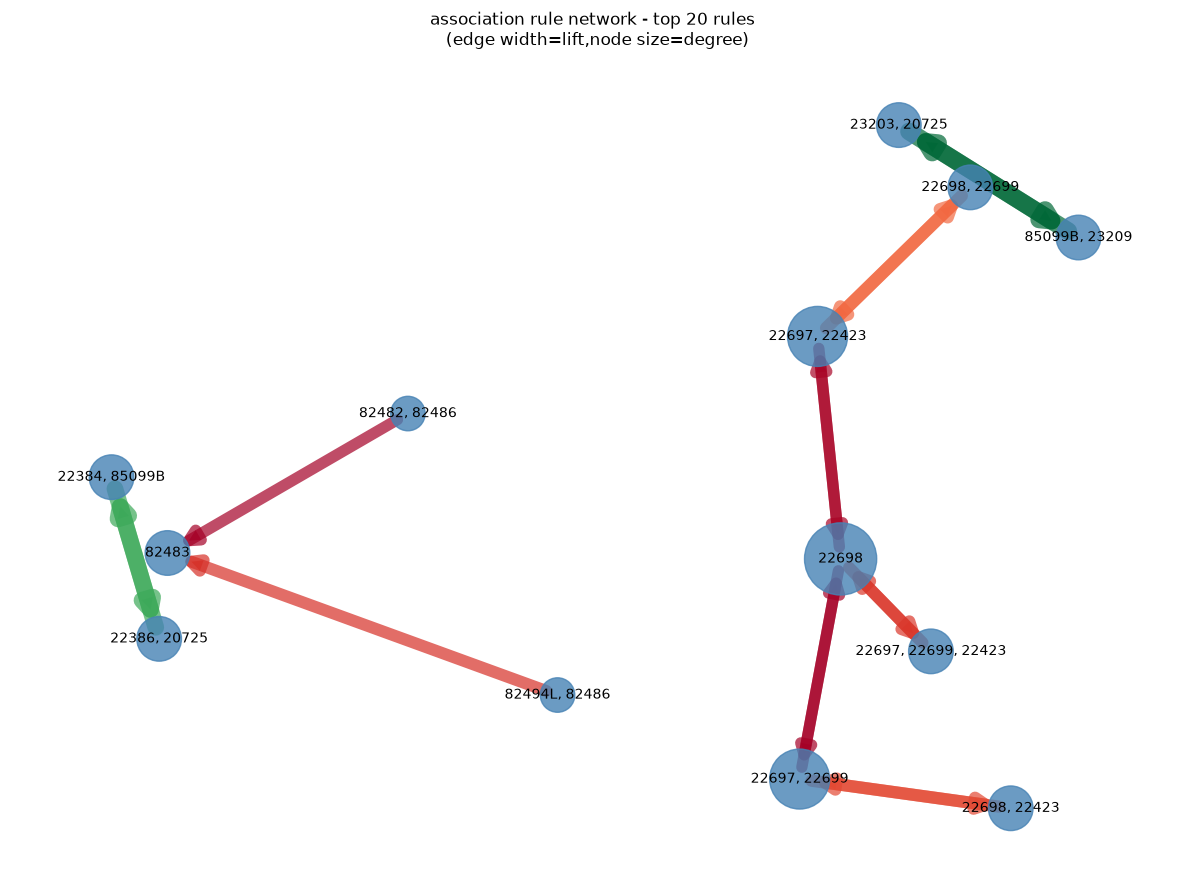

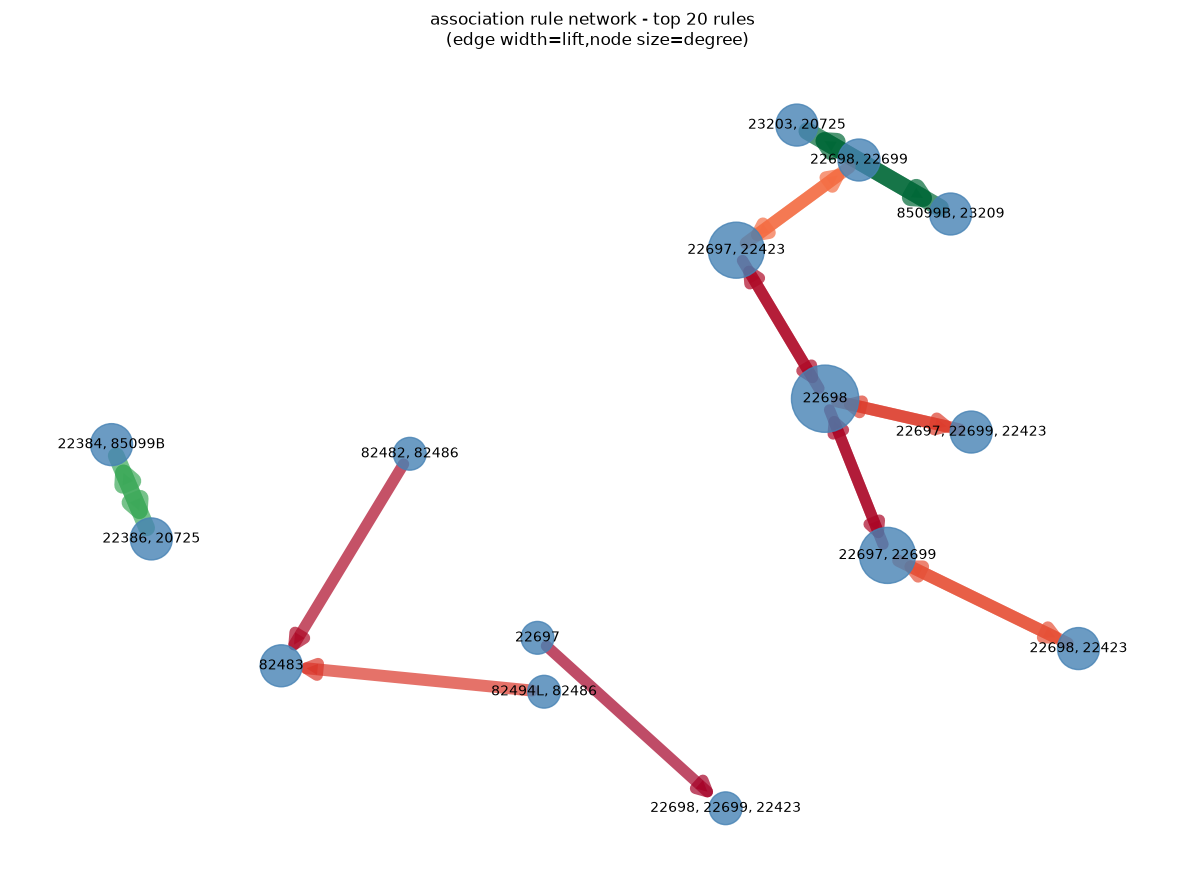

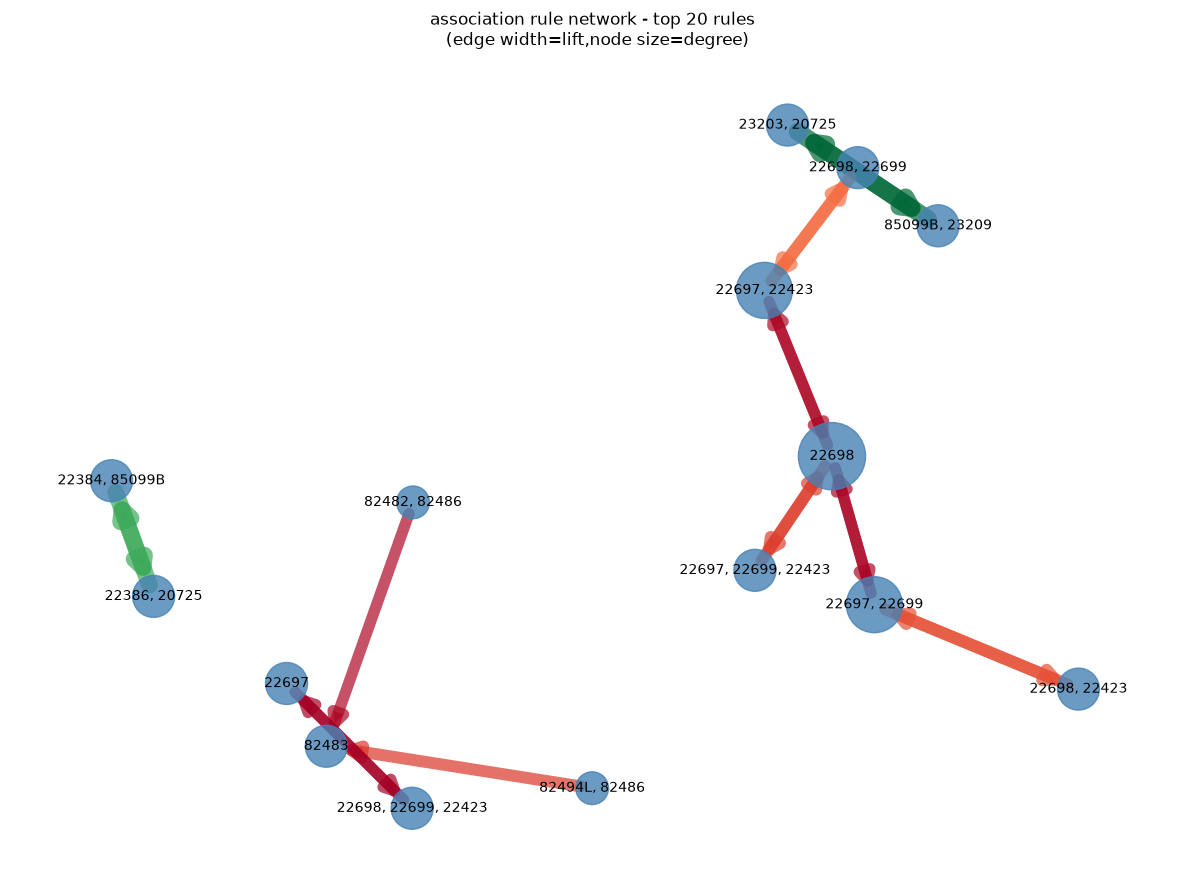

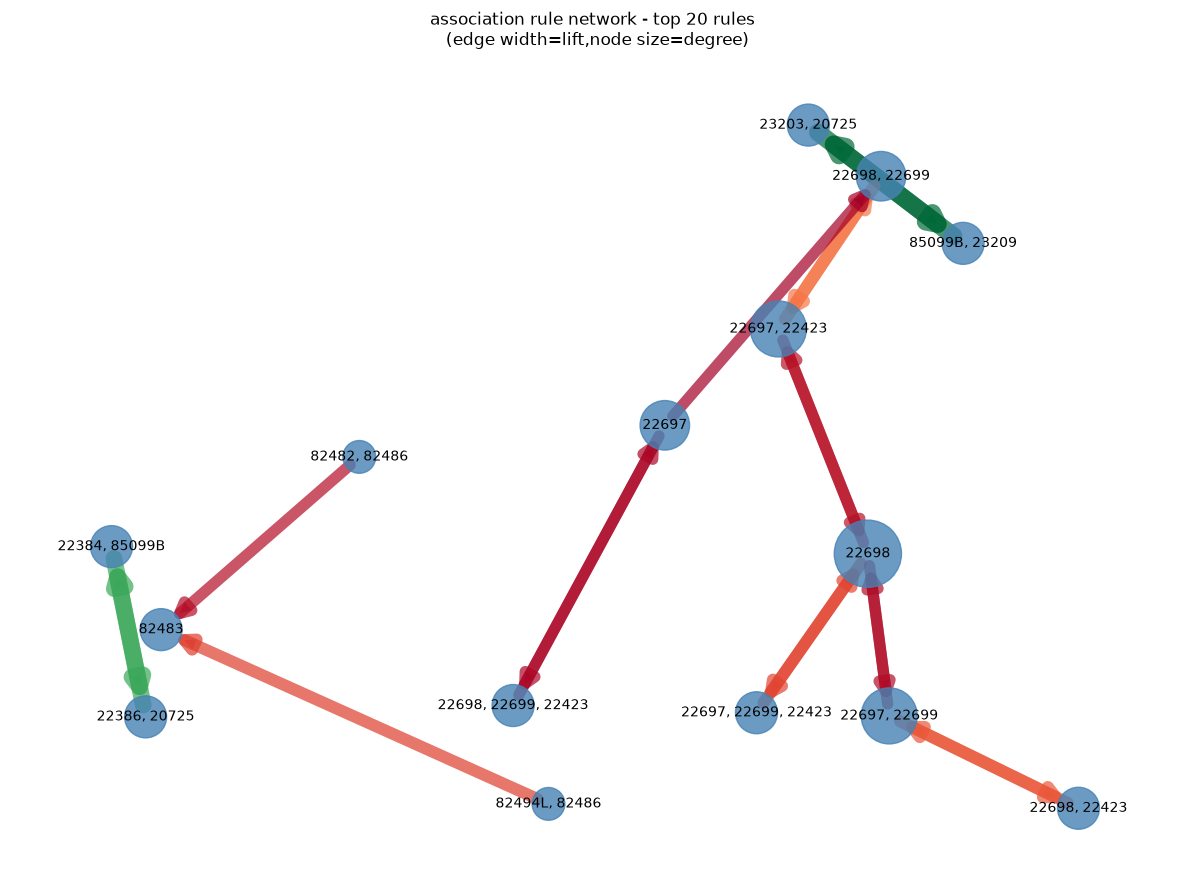

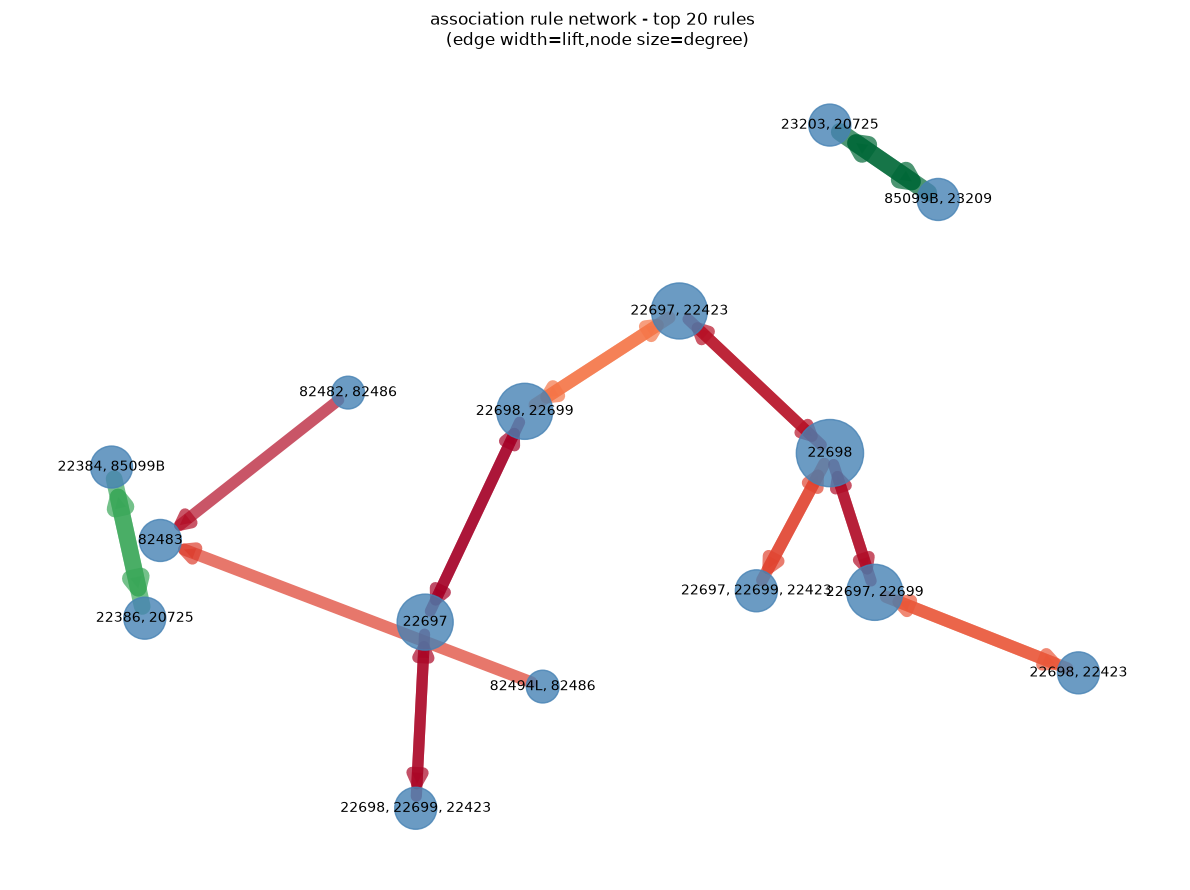

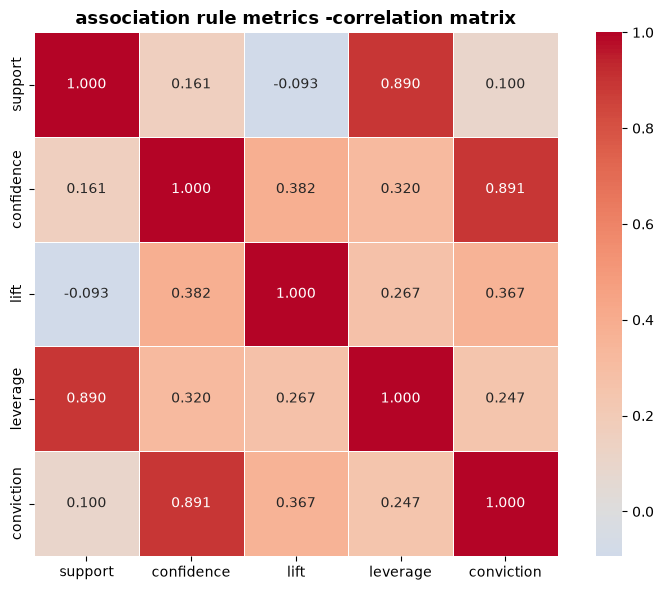

 rule metric stats
         support  confidence       lift   leverage  conviction
count  3496.0000   3496.0000  3496.0000  3496.0000   3496.0000
mean      0.0141      0.3362     6.7990     0.0113      1.5977
std       0.0050      0.1890     3.0038     0.0046      0.6924
min       0.0101      0.0689     1.0342     0.0004      1.0030
25%       0.0111      0.1742     4.9785     0.0092      1.1613
50%       0.0124      0.2864     6.8519     0.0103      1.3329
75%       0.0150      0.4750     8.5169     0.0124      1.7757
max       0.0444      0.9019    25.4408     0.0405      9.6234


In [23]:
#--rule network graph
try:
    import networkx as nx

    # build graph from top rules
    top_rules=strong_rules.head(20)
    g=nx.DiGraph()

    for _,row in top_rules.iterrows():
        ant=row['ant_str']
        cons=row['cons_str']
        g.add_edge(ant,cons,weight=row['lift'],confidence=row['confidence'],support=row['support'])

        fig,ax=plt.subplots(figsize=(12,9))
        pos=nx.spring_layout(g,k=2,seed=42)

        #node size= degree centrality
        centrality =nx.degree_centrality(g)
        node_sizes=[centrality[n]* 5000 + 200 for n in g.nodes()]

        edge=g.edges(data=True)
        edge_weights=[d['weight'] for _,_, d in edge]

        nx.draw_networkx_nodes(g,pos,node_size=node_sizes,node_color='steelblue',alpha=0.8,ax=ax)
        nx.draw_networkx_labels(g,pos,font_size=10,ax=ax)
        nx.draw_networkx_edges(g,pos,width=[w * 0.5 for w in edge_weights],edge_color=edge_weights,edge_cmap=plt.cm.RdYlGn,alpha=0.7,arrows=True,arrowsize=20,ax=ax)

        ax.set_title('association rule network - top 20 rules \n (edge width=lift,node size=degree)')
        ax.axis('off')
        plt.tight_layout()
        plt.show()


except ImportError:
    print('networkx not installed - skipping rule network graph visualization')
    print('skipping network graph')


metric_cols=['support','confidence','lift','leverage','conviction']
avail_cols=[c for c in metric_cols if c in rules.columns]
rule_corr=rules[avail_cols].corr()

fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(rule_corr,annot=True,fmt='.3f',cmap='coolwarm',center=0,ax=ax,square=True,linewidths=0.5)
ax.set_title('association rule metrics -correlation matrix',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.show()

print(f' rule metric stats')
print(rules[avail_cols].describe().round(4).to_string())

In [24]:
# Enrich Association Rules with Product Descriptions & Export
item_descriptions = raw_df.dropna(subset=['StockCode', 'Description']).drop_duplicates(subset=['StockCode'])
code_to_desc = dict(zip(item_descriptions['StockCode'].astype(str), item_descriptions['Description']))

def map_items_to_desc(item_collection):
    if isinstance(item_collection, (list, set, frozenset)):
        return [code_to_desc.get(str(x), str(x)) for x in item_collection]
    return str(item_collection)

rules_save = strong_rules.copy()
rules_save['antecedent_names'] = rules_save['antecedents'].apply(map_items_to_desc)
rules_save['consequent_names'] = rules_save['consequents'].apply(map_items_to_desc)

rules_out_path = PROCESSED_DIR / 'association_rules.csv'
rules_save.to_csv(rules_out_path, index=False)
print(f"Enriched association rules exported to: {rules_out_path} ({rules_save.shape[0]} strong rules)")


Enriched association rules exported to: C:\--------projects------\Customer_Segmentation--UCI-\data\processed\association_rules.csv (1688 strong rules)


# 04 | anomaly detection


> **Goal:** Identify unusual customers — fraud signals, VIP outliers, data quality issues  
> **Methods:** Isolation Forest · Local Outlier Factor · One-Class SVM · Elliptic Envelope · DBSCAN Outliers · Autoencoder Reconstruction Error

| Method | Assumption | Best For |
|---|---|---|
| **Isolation Forest** | Anomalies are easier to isolate | General purpose, fast |
| **LOF** | Anomalies have low local density | Local density anomalies |
| **One-Class SVM** | Anomalies outside learned boundary | Non-linear boundaries |
| **Elliptic Envelope** | Data is Gaussian distributed | Multivariate normal data |
| **Autoencoder** | Anomalies have high reconstruction error | Complex non-linear patterns |


In [25]:
#-- contamination assumption--
# how much of the data we expect to be anomalous (typical: 1-5%)

contamination=0.05

print(f'anomaly detection setup:')
print(f' data shape: {x_scaled.shape}')
print(f' contamination: {contamination} ({contamination* 100:.0f}% expected anomalies)')
print(f' expected anomalies : {int(x_scaled.shape[0] * contamination)} customers')



anomaly detection setup:
 data shape: (4319, 14)
 contamination: 0.05 (5% expected anomalies)
 expected anomalies : 215 customers


fitting isolation forest


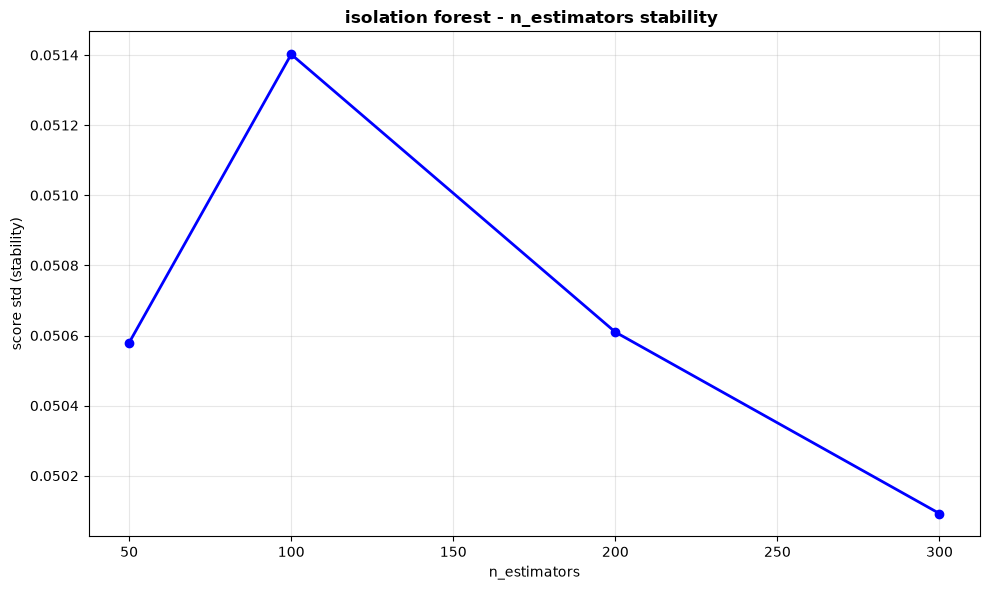

 isolation forest 
 anomalies detected: 216 (5.00%)
 score range: -0.6889, -0.3895
Isolation Forest model saved to: C:\--------projects------\Customer_Segmentation--UCI-\models\isolation_forest.joblib


In [26]:
# --1. isolation forest---
print(f'fitting isolation forest')

n_est_scores=[]
for n_est in [50,100,200,300]:
    ifo=IsolationForest(n_estimators=n_est,contamination=contamination,random_state=42,n_jobs=-1)
    ifo.fit(x_scaled)
    scores=ifo.score_samples(x_scaled)
    n_est_scores.append(scores.std())


fig,ax=plt.subplots(figsize=(10,6))
ax.plot([50,100,200,300],n_est_scores,'bo-',lw=2)
ax.set_xlabel('n_estimators')
ax.set_ylabel('score std (stability)')
ax.set_title('isolation forest - n_estimators stability ',fontsize=12,fontweight='bold')
ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

ifo_final=IsolationForest(n_estimators=200,contamination=contamination,random_state=42,max_samples='auto',max_features=1.0,n_jobs=-1,bootstrap=False)
ifo_labels=ifo_final.fit_predict(x_scaled)
ifo_scores=ifo_final.score_samples(x_scaled)
ifo_anomaly=(ifo_labels==-1).astype(int)

rfm['IsoForest_Anomaly']=ifo_anomaly
rfm['IsoForest_Score']=ifo_scores

print(f' isolation forest ')
print(f' anomalies detected: {ifo_anomaly.sum()} ({ifo_anomaly.mean():.2%})')
print(f' score range: {ifo_scores.min():.4f}, {ifo_scores.max():.4f}')


# Save trained Isolation Forest model
joblib.dump(ifo_final, MODELS_DIR / 'isolation_forest.joblib')
print(f'Isolation Forest model saved to: {MODELS_DIR / "isolation_forest.joblib"}')


 fitting lof


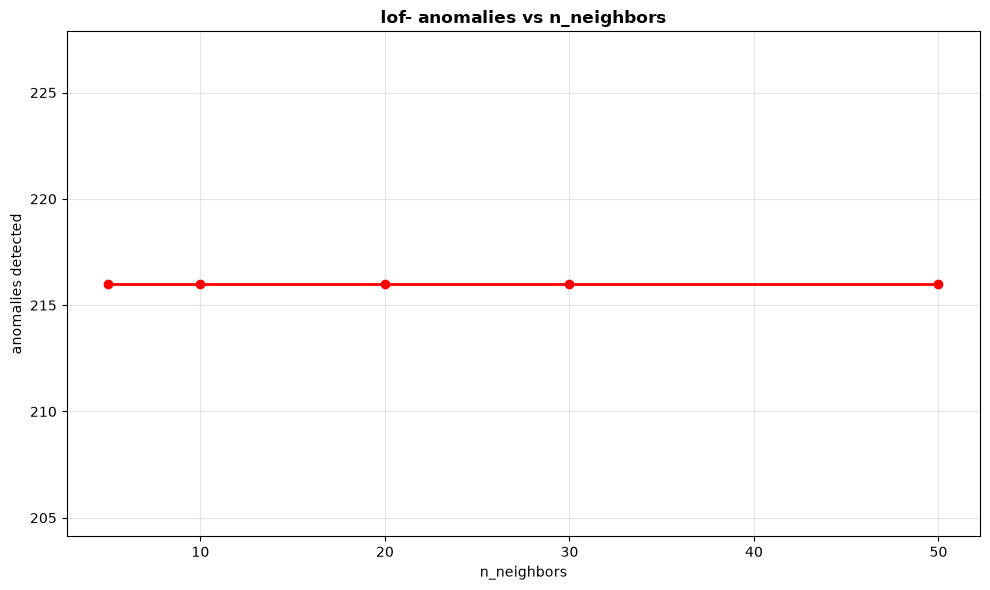

 lof
 anomalies detected : 216 (5.0%)
 lof score range: [-2.2183,-0.9539]
 lof score >1 = potential outlier | much >1 = strong outlier


In [27]:
#-- 2. local outlier factor (lof)---
print(f' fitting lof')

lof_n_neighbors=[5,10,20,30,50]
lof_n_anomalies=[]

for nn in lof_n_neighbors:
    lof_tmp=LocalOutlierFactor(n_neighbors=nn,contamination=contamination,n_jobs=-1)
    lof_pred=lof_tmp.fit_predict(x_scaled)
    lof_n_anomalies.append((lof_pred==-1).sum())

fig,ax=plt.subplots(figsize=(10,6))
ax.plot(lof_n_neighbors,lof_n_anomalies,'ro-',lw=2)
ax.set_xlabel('n_neighbors')
ax.set_ylabel('anomalies detected')
ax.set_title('lof- anomalies vs n_neighbors',fontsize=12,fontweight='bold')
ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

lof_final=LocalOutlierFactor(n_neighbors=20,contamination=contamination,n_jobs=-1)
lof_labels=lof_final.fit_predict(x_scaled)
lof_scores=lof_final.negative_outlier_factor_
lof_anomaly=(lof_labels==-1).astype(int)


rfm['lof_anomaly']=lof_anomaly
rfm['lof_score']=lof_scores

print(f' lof')
print(f' anomalies detected : {lof_anomaly.sum()} ({lof_anomaly.mean():.1%})')
print(f' lof score range: [{lof_scores.min():.4f},{lof_scores.max():.4f}]')
print(f' lof score >1 = potential outlier | much >1 = strong outlier')



 sampled to 2000 for ocsvm training


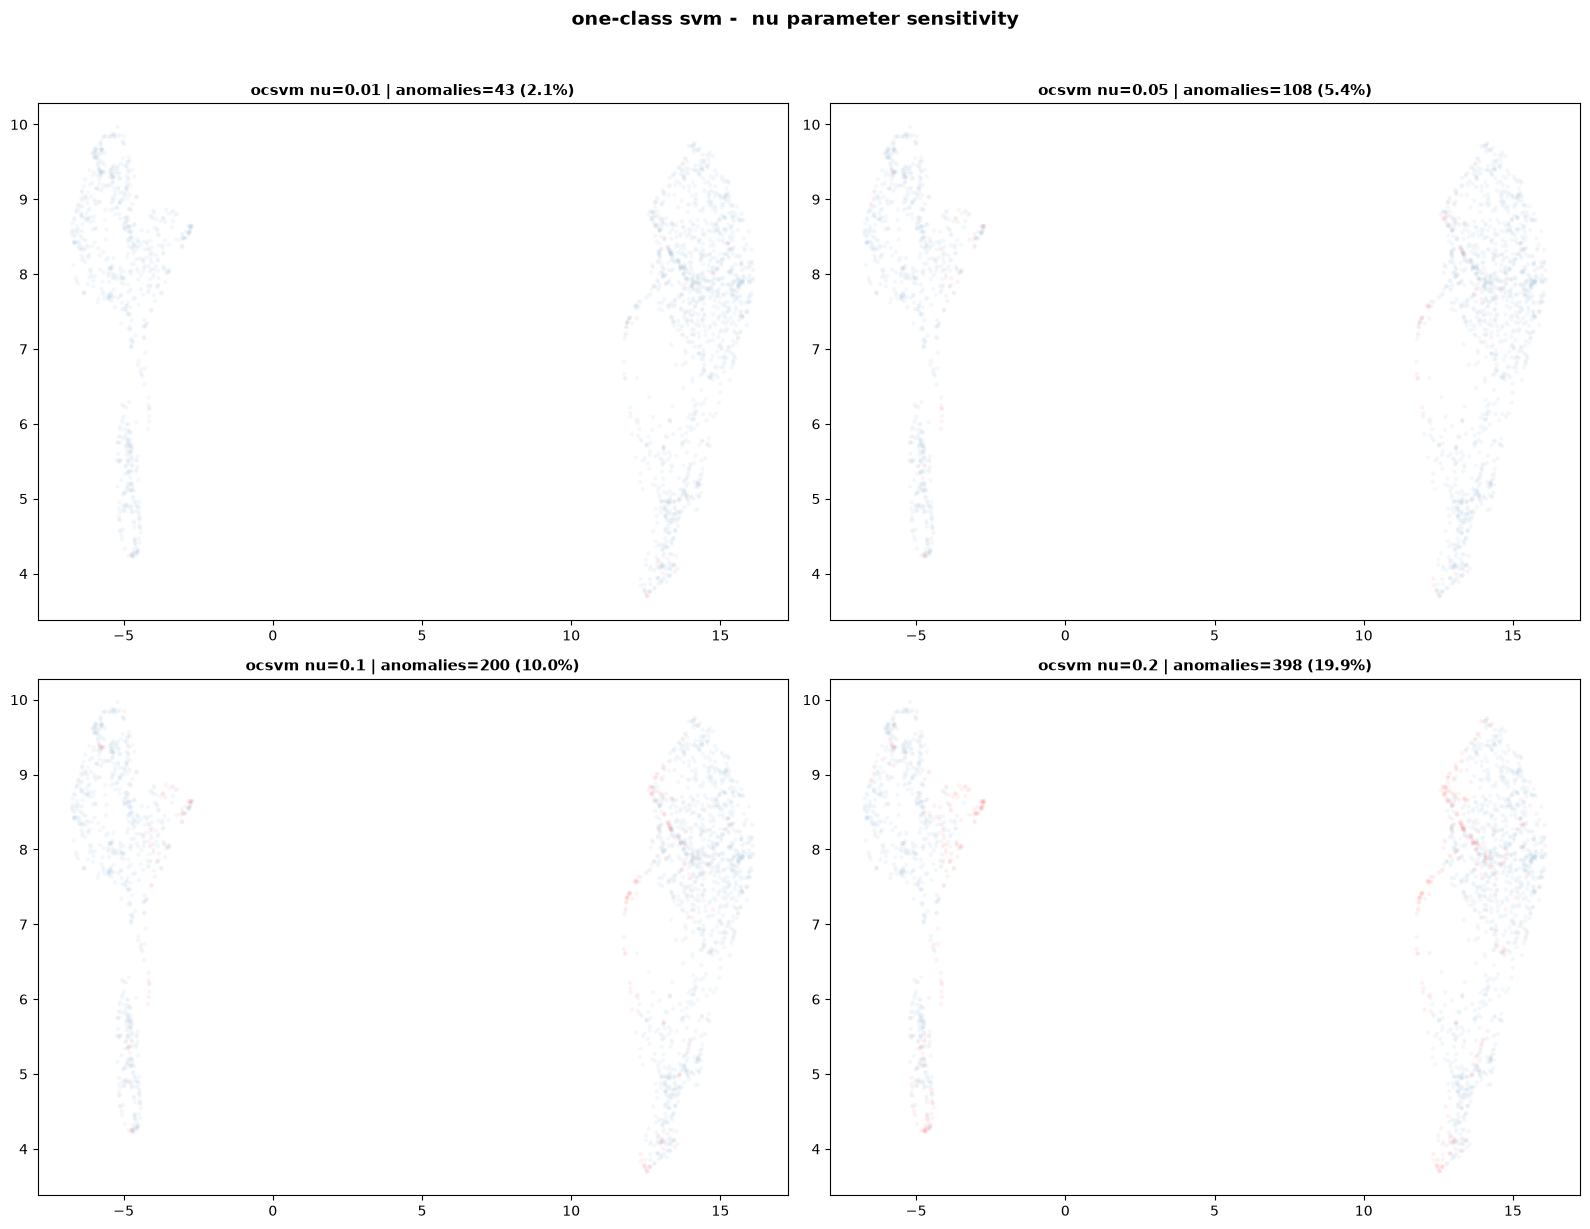

 one-class svm
 anomalies detected : 247 (5.7%)


In [28]:
# 3. one-class svm

max_svm=2000
if x_scaled.shape[0]>max_svm:
    np.random.seed(42)
    svm_idx=np.random.choice(x_scaled.shape[0],max_svm,replace=False)
    x_svm=x_scaled[svm_idx]
    print(f' sampled to {max_svm} for ocsvm training')

else:
    svm_idx=np.arange(x_scaled.shape[0])
    x_svm=x_scaled

nu_values=[0.01,0.05,0.1,0.2]
fig,axes=plt.subplots(2,2,figsize=(16,12))
axes=axes.flatten()

for idx,nu in enumerate(nu_values):
    ocsvm=OneClassSVM(kernel='rbf',nu=nu,gamma='scale')
    ocsvm.fit(x_svm)
    pred_svm=ocsvm.predict(x_svm)
    n_anom=(pred_svm ==-1).sum()
    scores_svm=ocsvm.score_samples(x_svm)

    #umap viz(sample to svm size)

    x_vis=x_umap_3d[svm_idx] if x_scaled.shape[0] > max_svm else x_umap_2d
    colors_svm=['red' if p==-1 else 'steelblue' for p in pred_svm]
    axes[idx].scatter(x_vis[:,0],x_vis[:,1],c=colors_svm,alpha=0.05,s=10,edgecolor='none')
    axes[idx].set_title(f'ocsvm nu={nu} | anomalies={n_anom} ({n_anom/len(pred_svm):.1%})',fontsize=11,fontweight='bold')

plt.suptitle('one-class svm -  nu parameter sensitivity',fontsize=14,fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

#final ocsvm (nu=contamination)
ocsvm_final=OneClassSVM(kernel='rbf',nu=contamination,gamma='scale')
ocsvm_final.fit(x_svm)
ocsvm_labels_sample=ocsvm_final.predict(x_svm)
ocsvm_scores_sample=ocsvm_final.score_samples(x_svm)

#predict on full data
ocsvm_labels_full=ocsvm_final.predict(x_scaled)
ocsvm_scores_full=ocsvm_final.score_samples(x_scaled)
ocsvm_anomaly=(ocsvm_labels_full==-1).astype(int)

rfm['ocsvm_anomaly']=ocsvm_anomaly
rfm['ocsvm_score']=ocsvm_scores_full

print(f' one-class svm')
print(f' anomalies detected : {ocsvm_anomaly.sum()} ({ocsvm_anomaly.mean():.1%})')





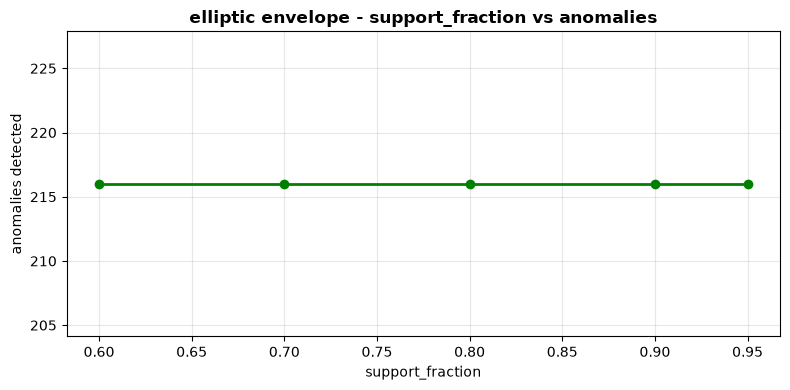

 elliptic envelope
 anomalies detected : 216 (5.0%)
 mahalanobis offset: -358.4105


In [29]:
# --4. elliptiv envelope (rubus covariance)---
support_fraction=[0.6,0.7,0.8,0.9,0.95]
ee_anomaly_counts=[]

for sf in support_fraction:
    ee_tmp=EllipticEnvelope(contamination=contamination,support_fraction=sf,random_state=42)

    try:
        ee_pred=ee_tmp.fit_predict(x_scaled)
        ee_anomaly_counts.append((ee_pred==-1).sum())

    except Exception as e:
        ee_anomaly_counts.append(None)


fig,ax=plt.subplots(figsize=(8,4))
valid=[(sf,n) for sf,n in zip(support_fraction,ee_anomaly_counts) if n is not None]
ax.plot([x[0] for x in valid],[x[1] for x in valid],'go-',lw=2)
ax.set_xlabel('support_fraction')
ax.set_ylabel('anomalies detected')
ax.set_title('elliptic envelope - support_fraction vs anomalies', fontsize=12,fontweight='bold')
ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

try:
    ee_final=EllipticEnvelope(contamination=contamination,support_fraction=0.8,random_state=42)
    ee_labels=ee_final.fit_predict(x_scaled)
    ee_scores=ee_final.score_samples(x_scaled)
    ee_anomaly=(ee_labels==-1).astype(int)

    rfm['ellipticenv_anomaly']=ee_anomaly
    rfm['ellipticenv_score']=ee_scores

    print(f' elliptic envelope')
    print(f' anomalies detected : {ee_anomaly.sum()} ({ee_anomaly.mean():.1%})')
    offset_val = getattr(ee_final, 'offset_', getattr(ee_final, 'threshold_', 0.0))
    print(f' mahalanobis offset: {offset_val:.4f}')

except Exception as e:
    print(f' elliptic envelope failed: {e}')
    rfm['ellipticenv_anomaly']=0
    rfm['ellipticenv_score']=0.0

    ee_anomaly=np.zeros(x_scaled.shape[0],dtype=int)

    

 autoencoder reconstruction :
 threshold (95th pct): 0.992963
 anomalies detected : 216 (5.0%)


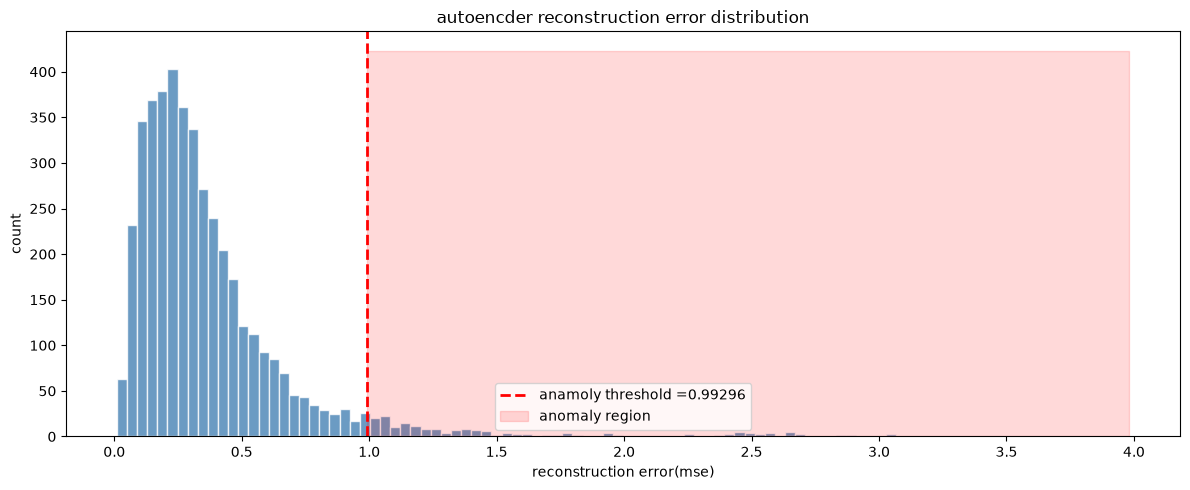

In [30]:
#-- 5. autoencoder reconstruction error
# points with high reconstruction error =anomalies (model can't reconstruct them well)

# reuse AE fro DR section: compute per-sample reconstruction error

if  ae_available:
    recon=autoencoder.predict(x_scaled,verbose=0)
    ae_recon_errors=np.mean((x_scaled - recon)** 2, axis=1)

else:
    #svd-based linear AE
    x_reconstructed=svd_ae.inverse_transform(x_svd)
    ae_recon_errors=np.mean((x_scaled - x_reconstructed) ** 2,axis=1)


# threshold at (1-contamination) percentile

ae_threshold=np.percentile(ae_recon_errors,(1-contamination)*100)
ae_anomaly=(ae_recon_errors > ae_threshold).astype(int)

rfm['ae_anomaly']=ae_anomaly
rfm['ae_reconerror']=ae_recon_errors

print(f' autoencoder reconstruction :')
print(f' threshold (95th pct): {ae_threshold:.6f}')
print(f' anomalies detected : {ae_anomaly.sum()} ({ae_anomaly.mean():.1%})')

#recon error distribution

fig,ax=plt.subplots(figsize=(12,5))
ax.hist(ae_recon_errors,bins=100,color='steelblue',edgecolor='white',alpha=0.8)
ax.axvline(x=ae_threshold,color='red',linestyle='--',lw=2,label=f'anamoly threshold ={ae_threshold:.5f}')
ax.fill_betweenx([0,ax.get_ylim()[1] if ax.get_ylim()[1]>0 else 100],ae_threshold,ae_recon_errors.max(),alpha=0.15,color='red',label='anomaly region')
ax.set_xlabel('reconstruction error(mse)')
ax.set_ylabel('count')
ax.set_title('autoencder reconstruction error distribution')
ax.legend()
plt.tight_layout()
plt.show()

In [31]:
# -- anomaly detection -- full comparision---
print(f' all anaomaly detection summary')

detectors={
    'isoloation forest': (ifo_anomaly,ifo_scores),
    'lof':(lof_anomaly,lof_scores),
    'one-class svm': (ocsvm_anomaly,ocsvm_scores_full),
    'elliptic env': (ee_anomaly,rfm['ellipticenv_score'].values if 'ellipticenv_score' in rfm.columns else np.zeros(x_scaled.shape[0])),
    'ae recon': (ae_anomaly,-ae_recon_errors),

}

anomaly_summary=[]

for name,(labels,scores) in detectors.items():
    anomaly_summary.append({
        'detector':name,
        'anomalies':int(labels.sum()),
        'pct':f'{labels.mean():.1%}',
        'score_min':round(float(scores.min()),4),
        'score_max':round(float(scores.max()),4),
        'score_mean':round(float(scores.mean()),4),
    })


anomaly_df=pd.DataFrame(anomaly_summary)
print(anomaly_df.to_string(index=False))


# -- venn-like overlap: how many flagged by multiple detectors

all_anomaly_cols=['isoforest_anomaly','lof_anomaly','ocsvm_anomaly','ellipticenv_anomaly','ae_anomaly']

avail_cols_anom=[c for c in all_anomaly_cols if c in rfm.columns]

rfm['anomaly_votes']=rfm[avail_cols_anom].sum(axis=1)
vote_dist=rfm['anomaly_votes'].value_counts().sort_index()
print(f'\n ensemble anomaly votes:')
for votes,count in vote_dist.items():
    bar='█' * min(count//5,30)
    print(f' {votes} detectors flagged: {count:5d} customers {bar}')


# consensus anomaly (flagged by majority)

majority=len(avail_cols_anom)// 2+1

rfm['consensus_anomaly']=(rfm['anomaly_votes']>= majority).astype(int)
print(f'\n consensus anomalies (>={majority} detectors): {rfm["consensus_anomaly"].sum()}')


 all anaomaly detection summary
         detector  anomalies  pct   score_min  score_max  score_mean
isoloation forest        216 5.0%     -0.6889    -0.3895     -0.4620
              lof        216 5.0%     -2.2183    -0.9539     -1.0846
    one-class svm        247 5.7%      1.8389    11.3436      8.3318
     elliptic env        216 5.0% -23818.5426    -2.7225   -120.9326
         ae recon        216 5.0%     -3.9822    -0.0098     -0.3828

 ensemble anomaly votes:
 0 detectors flagged:  3794 customers ██████████████████████████████
 1 detectors flagged:   300 customers ██████████████████████████████
 2 detectors flagged:   117 customers ███████████████████████
 3 detectors flagged:    71 customers ██████████████
 4 detectors flagged:    37 customers ███████

 consensus anomalies (>=3 detectors): 108


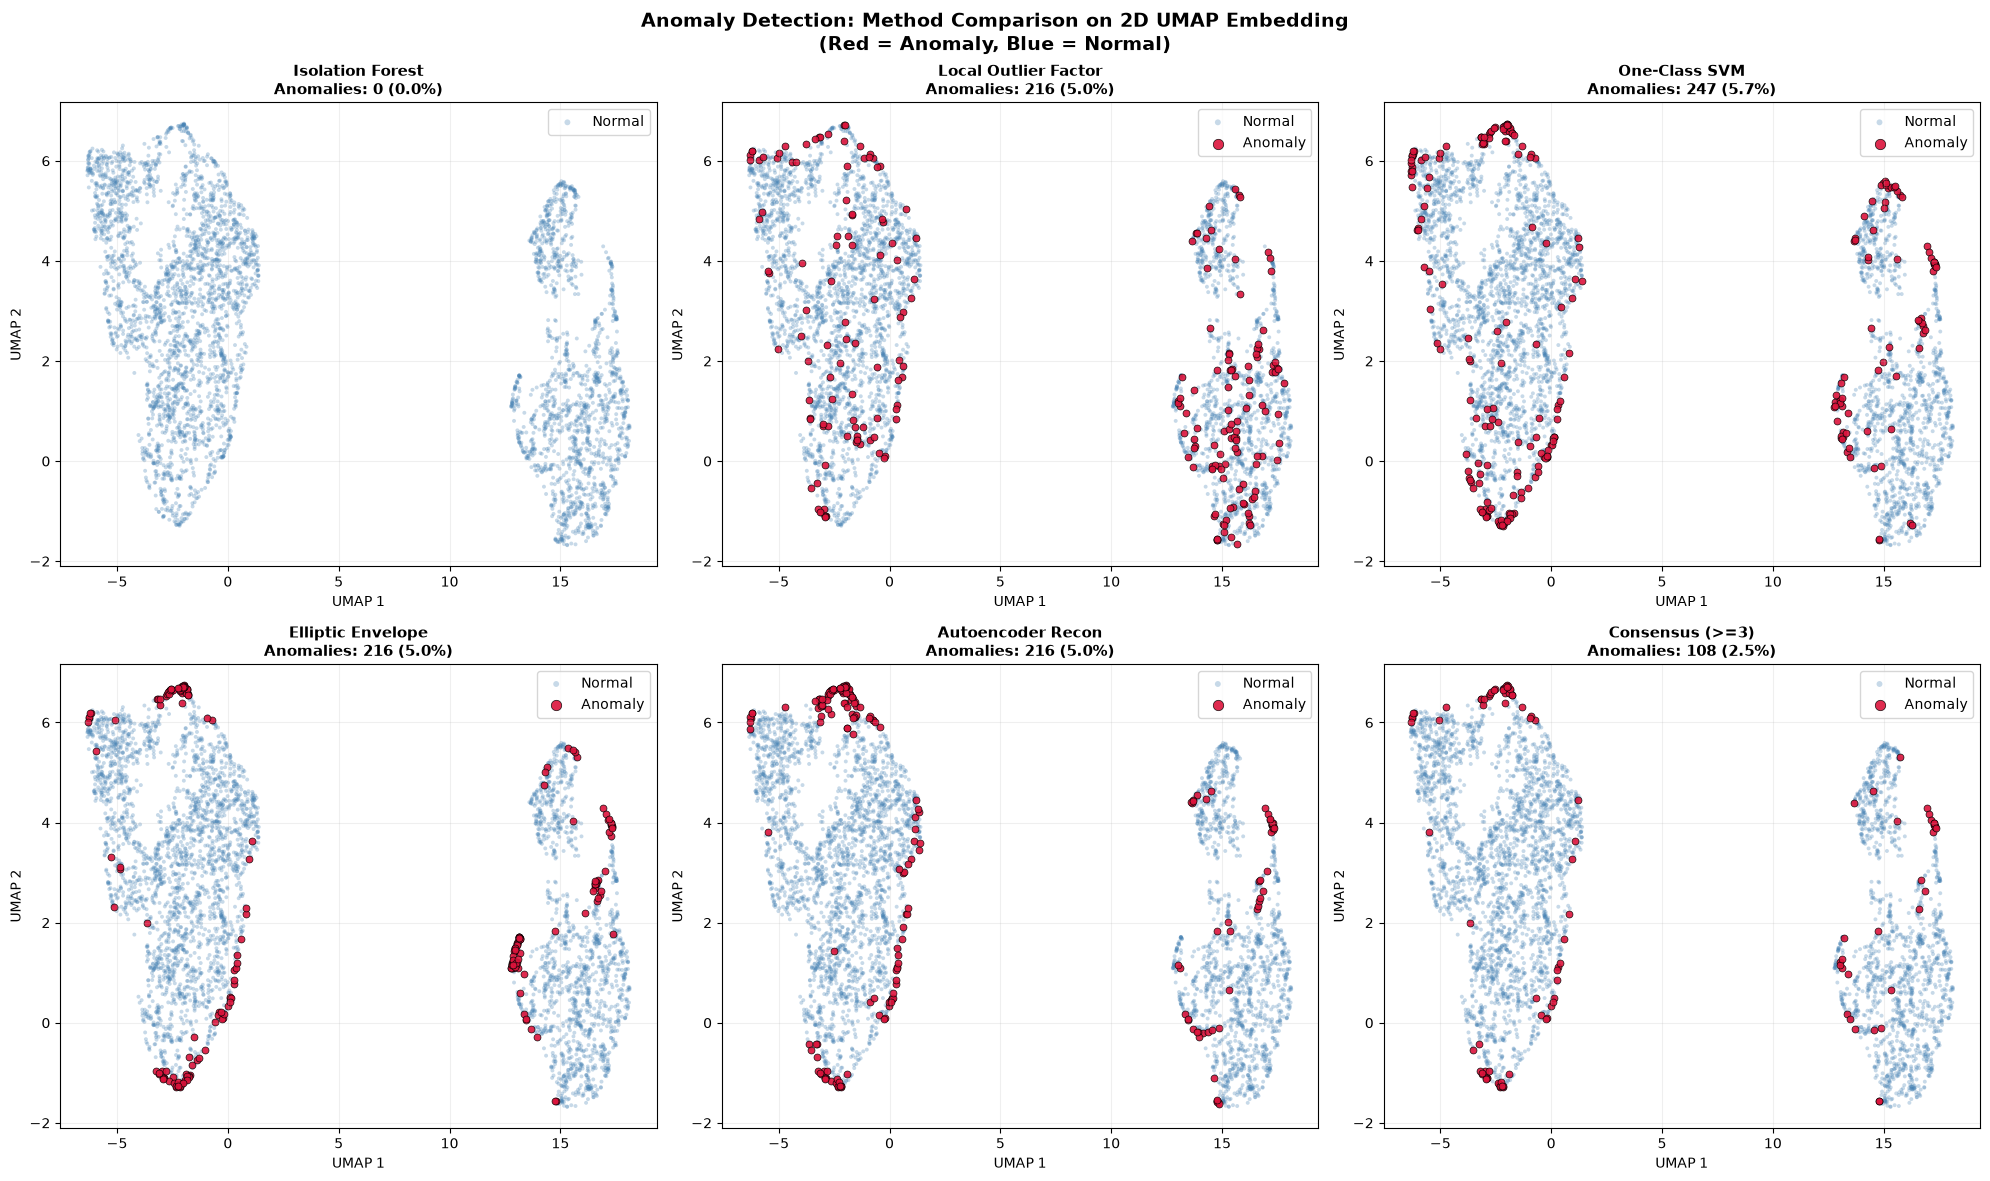

In [32]:
# -- Anomaly Visualization in UMAP Space (Vectorized for Performance) --
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

det_list = [
    ('Isolation Forest', 'isoforest_anomaly', ifo_scores),
    ('Local Outlier Factor', 'lof_anomaly', lof_scores),
    ('One-Class SVM', 'ocsvm_anomaly', ocsvm_scores_full),
    ('Elliptic Envelope', 'ellipticenv_anomaly', rfm['ellipticenv_anomaly'].values if 'ellipticenv_anomaly' in rfm.columns else np.zeros(len(x_scaled))),
    ('Autoencoder Recon', 'ae_anomaly', -ae_recon_errors),
    ('Consensus (>=3)', 'consensus_anomaly', rfm['consensus_anomaly'].values if 'consensus_anomaly' in rfm.columns else np.zeros(len(x_scaled)))
]

for idx, (name, col, scores) in enumerate(det_list):
    ax = axes[idx]
    labels_viz = rfm[col].values if col in rfm.columns else np.zeros(len(x_scaled))
    n_anom = int(labels_viz.sum())
    
    # Normal points (blue, small, low alpha)
    normal_mask = (labels_viz == 0)
    ax.scatter(x_umap_2d[normal_mask, 0], x_umap_2d[normal_mask, 1],
               c='steelblue', s=8, alpha=0.3, edgecolors='none', label='Normal')
    
    # Anomaly points (red, larger, high alpha)
    anom_mask = (labels_viz == 1)
    if anom_mask.sum() > 0:
        ax.scatter(x_umap_2d[anom_mask, 0], x_umap_2d[anom_mask, 1],
                   c='crimson', s=25, alpha=0.9, edgecolors='black', linewidth=0.5, label='Anomaly')
    
    ax.set_title(f'{name}\nAnomalies: {n_anom} ({n_anom/len(labels_viz):.1%})', fontsize=11, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.grid(True, alpha=0.2)
    ax.legend(loc='upper right', markerscale=1.5)

plt.suptitle('Anomaly Detection: Method Comparison on 2D UMAP Embedding\n(Red = Anomaly, Blue = Normal)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Anomaly vs Normal Customer Profile (Mean Values):
         Recency  Frequency  Monetary  AvgOrderValue  ProductVariety  CancelRate  CLV_score
Normal      92.8       3.94   1536.34          26.87           59.42        0.02      14.64
Anomaly     81.4      16.49  15432.26          94.16          150.30        0.05     331.49


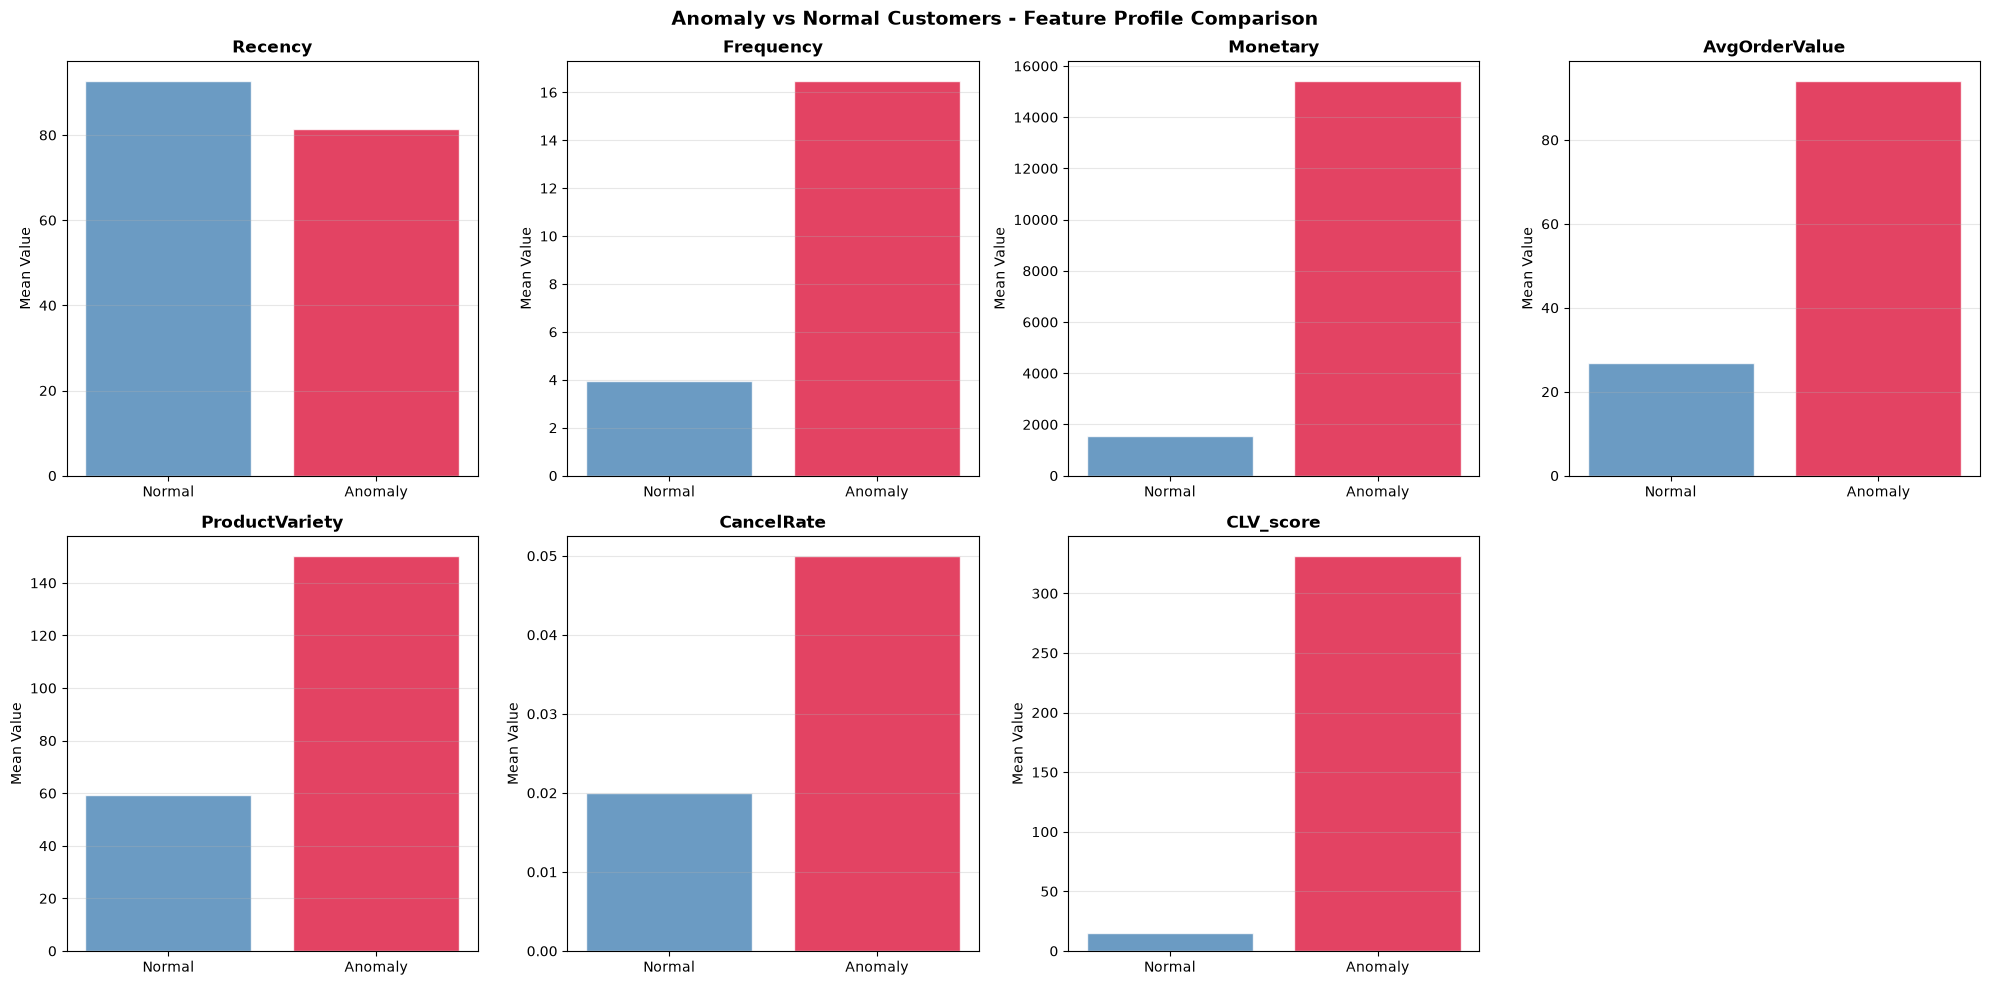


Business Interpretation of Detected Anomalies:
  -> High Spend Outliers: Extreme VIP whales or large institutional wholesale buyers.
  -> High Cancellation Outliers: Potential return-abuse or dissatisfied customer accounts.


In [33]:
# --- Anomaly Profile: Who are the anomalous customers? ---
profile_cols = [c for c in ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'ProductVariety', 'CancelRate', 'CLV_score'] if c in rfm.columns]

if 'consensus_anomaly' in rfm.columns and rfm['consensus_anomaly'].sum() > 0:
    anomaly_profile = rfm.groupby('consensus_anomaly')[profile_cols].mean().round(2)
    anomaly_profile.index = ['Normal', 'Anomaly']

    print('Anomaly vs Normal Customer Profile (Mean Values):')
    print(anomaly_profile.to_string())

    n_metrics = len(profile_cols)
    fig, axes = plt.subplots(2, (n_metrics + 1) // 2, figsize=(20, 10))
    axes = axes.flatten()

    for idx, col in enumerate(profile_cols):
        ax = axes[idx]
        vals = anomaly_profile[col]
        ax.bar(['Normal', 'Anomaly'], vals.values, color=['steelblue', 'crimson'], alpha=0.8, edgecolor='white')
        ax.set_title(col, fontsize=12, fontweight='bold')
        ax.set_ylabel('Mean Value')
        ax.grid(True, alpha=0.3, axis='y')

    for j in range(len(profile_cols), len(axes)):
        axes[j].axis('off')

    plt.suptitle('Anomaly vs Normal Customers - Feature Profile Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Business Interpretation of Anomalies
    print('\nBusiness Interpretation of Detected Anomalies:')
    anom_rfm = rfm[rfm['consensus_anomaly'] == 1]
    normal_rfm = rfm[rfm['consensus_anomaly'] == 0]

    if 'Monetary' in profile_cols:
        if anom_rfm['Monetary'].mean() > normal_rfm['Monetary'].mean() * 2:
            print('  -> High Spend Outliers: Extreme VIP whales or large institutional wholesale buyers.')
        elif anom_rfm['Monetary'].mean() < normal_rfm['Monetary'].mean() * 0.5:
            print('  -> Low Spend Outliers: Single small transactions or low-engagement accounts.')

    if 'CancelRate' in profile_cols:
        if anom_rfm['CancelRate'].mean() > normal_rfm['CancelRate'].mean() * 1.5:
            print('  -> High Cancellation Outliers: Potential return-abuse or dissatisfied customer accounts.')


# 05 | final summary -- all unsupervised methods

In [34]:
master_summary = pd.DataFrame([
    # Customer Segmentation / Clustering
    {'Domain': 'Clustering', 'Method': 'K-Means++ (Final)', 'Type': 'Centroid', 'Output': f'K=4 clusters', 'Key Metric': f'Silhouette={silhouette_score(x_scaled, rfm["Cluster"]):.4f}'},
    {'Domain': 'Clustering', 'Method': 'MiniBatch K-Means', 'Type': 'Centroid (Batch)', 'Output': f'K=4 clusters', 'Key Metric': 'Fast Scalable'},
    {'Domain': 'Clustering', 'Method': 'Hierarchical (Ward)', 'Type': 'Agglomerative', 'Output': f'K=4 clusters', 'Key Metric': 'Dendrogram/Variance'},
    {'Domain': 'Clustering', 'Method': 'Gaussian Mixture (GMM)', 'Type': 'Probabilistic', 'Output': f'K=4 clusters', 'Key Metric': 'Soft Clustering'},

    # Dimensionality Reduction
    {'Domain': 'DR', 'Method': 'PCA', 'Type': 'Linear', 'Output': f'{x_pca.shape}', 'Key Metric': f'Var={pca_final.explained_variance_ratio_.sum():.2%}'},
    {'Domain': 'DR', 'Method': 'Kernel PCA (RBF)', 'Type': 'Non-linear', 'Output': f'{x_kpca_best.shape}', 'Key Metric': 'Kernel=RBF, gamma=0.1'},
    {'Domain': 'DR', 'Method': 't-SNE', 'Type': 'Non-linear', 'Output': f'{x_tsne_best.shape}', 'Key Metric': f'KL={tsne.kl_divergence_:.4f}'},
    {'Domain': 'DR', 'Method': 'UMAP', 'Type': 'Non-linear', 'Output': f'{x_umap_2d.shape}', 'Key Metric': 'n_nbrs=15, min_dist=0.1'},
    {'Domain': 'DR', 'Method': 'NMF', 'Type': 'Linear', 'Output': f'{x_nmf.shape}', 'Key Metric': f'ReconErr={nmf_final.reconstruction_err_:.4f}'},
    {'Domain': 'DR', 'Method': 'Factor Analysis', 'Type': 'Probabilistic', 'Output': f'{x_fa.shape}', 'Key Metric': f'n_factors={best_fa_n}'},
    {'Domain': 'DR', 'Method': 'ISOMAP', 'Type': 'Manifold', 'Output': f'{x_isomap.shape}', 'Key Metric': 'n_nbrs=10'},
    {'Domain': 'DR', 'Method': 'LLE', 'Type': 'Manifold', 'Output': 'varies', 'Key Metric': 'Standard + Modified'},
    {'Domain': 'DR', 'Method': 'Autoencoder', 'Type': 'Deep', 'Output': f'{x_ae_encoded.shape}', 'Key Metric': f'ReconMSE={ae_recon_err:.6f}'},

    # Association Rule Mining
    {'Domain': 'ARM', 'Method': 'Apriori', 'Type': 'Freq. Pattern', 'Output': f'{len(frequent_itemsets_apriori)} itemsets', 'Key Metric': f'min_sup={min_support}'},
    {'Domain': 'ARM', 'Method': 'FP-Growth', 'Type': 'Freq. Pattern', 'Output': f'{len(strong_rules)} rules', 'Key Metric': f'lift={strong_rules["lift"].mean():.2f}'},

    # Anomaly Detection
    {'Domain': 'Anomaly', 'Method': 'Isolation Forest', 'Type': 'Tree-based', 'Output': f'{ifo_anomaly.sum()} anomalies', 'Key Metric': 'n_est=200'},
    {'Domain': 'Anomaly', 'Method': 'LOF', 'Type': 'Density-based', 'Output': f'{lof_anomaly.sum()} anomalies', 'Key Metric': 'n_nbrs=20'},
    {'Domain': 'Anomaly', 'Method': 'One-Class SVM', 'Type': 'Boundary', 'Output': f'{ocsvm_anomaly.sum()} anomalies', 'Key Metric': f'nu={contamination}'},
    {'Domain': 'Anomaly', 'Method': 'Elliptic Env', 'Type': 'Statistical', 'Output': f'{ee_anomaly.sum()} anomalies', 'Key Metric': 'Mahalanobis dist'},
    {'Domain': 'Anomaly', 'Method': 'AE Reconstruction', 'Type': 'Deep', 'Output': f'{ae_anomaly.sum()} anomalies', 'Key Metric': f'thresh={ae_threshold:.5f}'},
    {'Domain': 'Anomaly', 'Method': 'Consensus (≥3)', 'Type': 'Ensemble', 'Output': f'{rfm["consensus_anomaly"].sum() if "consensus_anomaly" in rfm.columns else 0} anomalies', 'Key Metric': 'Majority vote'}
])

print('\n' + '='*85)
print('MASTER SUMMARY OF ALL UNSUPERVISED METHODS'.center(85))
print('='*85)

for domain, group in master_summary.groupby('Domain', sort=False):
    print(f'\n[{domain.upper()}]')
    print(group[['Method', 'Type', 'Output', 'Key Metric']].to_string(index=False))

print('\n' + '='*85)



                      MASTER SUMMARY OF ALL UNSUPERVISED METHODS                     

[CLUSTERING]
                Method             Type       Output          Key Metric
     K-Means++ (Final)         Centroid K=4 clusters   Silhouette=0.2589
     MiniBatch K-Means Centroid (Batch) K=4 clusters       Fast Scalable
   Hierarchical (Ward)    Agglomerative K=4 clusters Dendrogram/Variance
Gaussian Mixture (GMM)    Probabilistic K=4 clusters     Soft Clustering

[DR]
          Method          Type    Output              Key Metric
             PCA        Linear (4319, 7)              Var=97.00%
Kernel PCA (RBF)    Non-linear (4319, 2)   Kernel=RBF, gamma=0.1
           t-SNE    Non-linear (3000, 2)               KL=0.9330
            UMAP    Non-linear (4319, 2) n_nbrs=15, min_dist=0.1
             NMF        Linear (4319, 4)        ReconErr=27.6377
 Factor Analysis Probabilistic (4319, 9)             n_factors=9
          ISOMAP      Manifold (2000, 2)               n_nbrs=10
        